# Macao Visitor Flows: Long-run Economic Coupling and Monthly Recovery Dynamics, 1995–2026

**CISC7204 Data Science and Data Visualization — Class F Team 02**

This notebook is a complete, reproducible research report. It uses official DSEC, World Bank,
DSEC annual releases, MGTO entry-point statistics and public Macao boundary data. The analytical
window is **January 2008–July 2026** for monthly data (223 months) and **1995–2020** for the
World Bank visitor/GDP regression overlap.

The notebook deliberately distinguishes three claims:

1. What the official data record;
2. What descriptive statistics and models suggest;
3. What cannot be concluded without additional data or a causal design.

## Executive summary

- Visitor arrivals fell from **39.41 million in 2019** to **5.90 million in 2020**, a decline of
  **85.0%**, then rose to **40.07 million in 2025**.
- January–July 2026 recorded **24.49 million arrivals**, equal to **102.8%** of the same
  January–July period in 2019.
- The annual visitor–GDP overlap is **1995–2020 (n = 26)**. A simple OLS fit has
  **R² = 0.817**; excluding 2020 gives **R² = 0.860 (n = 25)**. This is a strong association, not
  a causal effect.
- The additive seasonal decomposition has a peak in **August** and troughs in **June and
  September**. The 2022 trough and the abrupt 2020 collapse make a stable seasonal model
  descriptively inadequate for the pandemic years.
- 2025 source markets are highly concentrated: **Mainland China 72.4%**, Hong Kong SAR 18.2%,
  Taiwan Region 2.49%; HHI is **0.5594 (5,594 on a 0–10,000 scale)**.
- In 2025, land checkpoints handled most visitor entries; Border Gate alone accounted for
  **41.6%**, HZMB Macao Port **22.9%**, and Hengqin Port **14.6%**.

## 1. Project introduction and research questions

Macao is a small, tourism-dependent economy with a highly concentrated source-market structure and
a border system dominated by land crossings. The project asks four questions:

**RQ1 — Long-run association.** How strongly are annual visitor arrivals and GDP per capita
associated over the available overlapping years, and how does the pandemic observation affect that
association?

**RQ2 — Monthly dynamics.** What seasonal structure is visible in monthly arrivals, and how did the
2020–2022 disruption alter it?

**RQ3 — Recovery.** By 2026, which months have returned to their 2019 visitor volume, and which
remain below it?

**RQ4 — Composition and geography.** Which source markets and entry checkpoints dominate, and how
are recorded visitor person-times distributed across districts?

The analysis is intentionally descriptive and predictive only in a limited statistical sense. It
does not estimate a structural model of tourism demand.

## 2. Data sources and acquisition

The raw files are preserved unchanged under `data/raw/` and `data/external/`. The notebook reads
these saved files rather than making live network calls, so a clean execution remains reproducible
even if an API changes. Retrieval date: **9 November 2026**.

| Source | Provider | Coverage used | Unit / definition | Role |
|---|---|---|---|---|
| DSEC monthly visitor arrivals | DSEC / data.gov.mo | Jan 2008–Jul 2026; 223 months | Visitor arrivals per month | Main monthly series |
| DSEC monthly hotel guests | DSEC / data.gov.mo | Jan 2008–Jul 2026; 223 months | Guests of hotel establishments | Context and co-movement |
| World Bank `ST.INT.ARVL` | World Bank | 1995–2020 | Annual international visitor arrivals | Long-run arrivals |
| World Bank `NY.GDP.PCAP.CD` | World Bank | 1995–2025 | GDP per capita, current US$ | Annual economic variable |
| DSEC 2024 annual release | DSEC | 2024 | Visitor arrivals and source markets | Market composition |
| DSEC 2025 annual release | DSEC | 2025 | Visitor arrivals and source markets | Latest complete year |
| MGTO Tourism Highlights | MGTO | Jan–Dec 2025 | Visitor arrivals by entry checkpoint | Entry-point map |
| DSEC district visitor data | DSEC | Jan–Jul 2026 | Visitor person-times by district | District choropleth |
| Macao statistics-zone GeoJSON | `ngsiolei/macau-map-data` | Current boundary files | Polygon geography | Base maps |
| OSM / Nominatim coordinates | OpenStreetMap contributors | Queried 9 Nov 2026 | Point coordinates | Checkpoint locations |

Key provenance links:

- DSEC monthly visitor dataset: <https://data.gov.mo/Detail?id=3546225a-2a34-4645-b01e-6752aed03993>
- DSEC hotel-guest dataset: <https://data.gov.mo/Detail?id=00eae9c4-a51d-4fa2-bd36-7e2db18374a8>
- World Bank arrivals: <https://data.worldbank.org/indicator/ST.INT.ARVL?locations=MO>
- World Bank GDP per capita: <https://data.worldbank.org/indicator/NY.GDP.PCAP.CD?locations=MO>
- MGTO statistics: <https://www.macaotourism.gov.mo/en/statistics>
- Macao map data: <https://github.com/ngsiolei/macau-map-data>
- Nominatim: <https://nominatim.openstreetmap.org/>

**Critical data caveat.** World Bank arrivals are available only through 2020. The years 2021–2025
are retained as missing values; they are not interpolated. The annual regression therefore uses
only the observed overlap, 1995–2020, even though GDP per capita extends to 2025.

## 3. Reproducible environment and project paths

In [1]:
from pathlib import Path
import os
import sys
import warnings

def find_project_root(start: Path | None = None) -> Path:
    """Locate the submission root from either the project or notebooks folder."""
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "raw").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root containing data/raw and notebooks")

PROJECT_ROOT = find_project_root()
print("Project root:", PROJECT_ROOT)

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

import numpy, pandas, scipy, sklearn, statsmodels, matplotlib, seaborn, plotly, dash, geopandas
print("Python:", sys.version.split()[0])
print("numpy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("scipy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("statsmodels:", statsmodels.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", seaborn.__version__)
print("plotly:", plotly.__version__)
print("dash:", dash.__version__)
print("geopandas:", geopandas.__version__)

Project root: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project


Python: 3.13.18
numpy: 2.5.4
pandas: 3.1.0
scipy: 1.18.1
scikit-learn: 1.9.1
statsmodels: 0.15.0
matplotlib: 3.11.2
seaborn: 0.13.2
plotly: 7.1.0
dash: 4.5.0
geopandas: 1.2.0


### Raw-file provenance

The next cell inventories the saved official files and their checksums. This makes it possible to
verify that the notebook is using the same frozen data snapshot described in
`documentation/Data_Source_Register.csv`.

In [2]:
import hashlib

inventory_rows = []
for folder in [PROJECT_ROOT / "data" / "raw", PROJECT_ROOT / "data" / "external"]:
    for path in sorted(folder.rglob("*")):
        if path.is_file():
            inventory_rows.append(
                {
                    "file": str(path.relative_to(PROJECT_ROOT)),
                    "bytes": path.stat().st_size,
                    "sha256": hashlib.sha256(path.read_bytes()).hexdigest()[:16],
                }
            )
display(pd.DataFrame(inventory_rows))

,file,bytes,sha256
0,data/raw/border_crossing_by_station.xlsx,18637,f8e180bf2eca714a
1,data/raw/dsec_monthly_hotel_guests_api_2026-11...,14104,f6b9d7959742e3e0
2,data/raw/dsec_monthly_visitor_arrivals_api_202...,14179,40975cab12cabf69
3,data/raw/dst_visitor_source_district.xlsx,61053,6cfc1aa591d7b352
4,data/raw/macao_2024_annual.html,81935,7d07e010a01dacba
5,data/raw/macao_2025_annual.html,80959,f72d99c2e4de3da4
6,data/raw/metadata/0039fc15-28ae-4287-8096-9fba...,14142,ae76cf7d2871035d
7,data/raw/metadata/30a54e15-7206-46a3-ab63-d557...,14364,b0a06b1a5e2f9239
8,data/raw/metadata/5ca58222-41a0-4e83-8e9d-fc11...,15476,599935b1d60a677c
9,data/raw/metadata/6b02781c-d483-4664-b899-2c35...,14256,b84c23c0dedc3ac2


### Optional refresh path

The analysis itself is offline and uses the frozen raw files. A refresh would require the official
provider's current terms and, for the DSEC API, an authorized application code supplied through an
environment variable. The notebook does not embed credentials or make network access a hidden
dependency.

## 4. Data loading, cleaning and feature construction

In [3]:
# The following cell embeds the data-preparation logic used to create the processed CSV files.
"""Build analysis-ready datasets for the Macao visitor-flow project.

This script is a development aid. The final notebook repeats the same
transformations so that the submitted analysis is reproducible end to end.
"""


import json
import re
from pathlib import Path

import pymupdf as fitz
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup

ROOT = PROJECT_ROOT
RAW = ROOT / "data" / "raw"
EXTERNAL = ROOT / "data" / "external"
PROCESSED = ROOT / "data" / "processed"

ANALYSIS_END = pd.Timestamp("2026-07-01")


def parse_month(period: str) -> pd.Timestamp:
    """Parse DSEC period strings such as 'Jan./2008' or 'May/2026'."""
    match = re.match(r"([A-Za-z]{3})\.?/(\d{4})", period.strip())
    if not match:
        raise ValueError(f"Unrecognised period string: {period!r}")
    month, year = match.groups()
    return pd.Timestamp(f"{year}-{month}-01")


def build_monthly() -> pd.DataFrame:
    raw = json.loads(
        (RAW / "dsec_monthly_visitor_arrivals_api_2026-11-09.json").read_text()
    )
    value_block = raw["value"]
    frame = pd.DataFrame(value_block["values"])
    frame["visitor_arrivals"] = frame["value"].astype(int)
    frame["month"] = frame["periodString"].map(parse_month)
    frame = frame.sort_values("month").reset_index(drop=True)

    expected = pd.date_range(frame["month"].min(), frame["month"].max(), freq="MS")
    if len(frame) != len(expected) or not frame["month"].equals(pd.Series(expected)):
        raise AssertionError("Monthly visitor series is not a complete monthly grid")
    if frame["month"].duplicated().any():
        raise AssertionError("Duplicate months found")
    if (frame["visitor_arrivals"] <= 0).any():
        raise AssertionError("Non-positive visitor arrival count found")

    # Freeze the analytical window at July 2026, even though the API returned
    # August and September 2026 by the retrieval date.
    frame = frame.loc[frame["month"] <= ANALYSIS_END].copy()
    if len(frame) != 223:
        raise AssertionError(f"Expected 223 months, found {len(frame)}")

    frame["year"] = frame["month"].dt.year
    frame["month_number"] = frame["month"].dt.month
    frame["phase"] = np.select(
        [
            frame["year"].between(2008, 2019),
            frame["year"].between(2020, 2022),
            frame["year"].between(2023, 2026),
        ],
        ["Growth and Baseline", "Disruption", "Recovery"],
        default="Outside scope",
    )
    frame["yoy_pct"] = frame["visitor_arrivals"].pct_change(12) * 100

    base_2019 = (
        frame.loc[frame["year"] == 2019, ["month_number", "visitor_arrivals"]]
        .set_index("month_number")["visitor_arrivals"]
    )
    frame["recovery_index"] = (
        frame["visitor_arrivals"]
        / frame["month_number"].map(base_2019)
        * 100
    )
    frame.loc[frame["year"] < 2019, "recovery_index"] = np.nan

    cols = [
        "month",
        "year",
        "month_number",
        "visitor_arrivals",
        "phase",
        "yoy_pct",
        "recovery_index",
    ]
    return frame[cols]


def build_hotel_guests() -> pd.DataFrame:
    raw = json.loads(
        (RAW / "dsec_monthly_hotel_guests_api_2026-11-09.json").read_text()
    )
    frame = pd.DataFrame(raw["value"]["values"])
    frame["hotel_guests"] = frame["value"].astype(int)
    frame["month"] = frame["periodString"].map(parse_month)
    frame = frame.sort_values("month").reset_index(drop=True)
    frame = frame.loc[frame["month"] <= ANALYSIS_END].copy()
    if len(frame) != 223:
        raise AssertionError(f"Expected 223 hotel-guest months, found {len(frame)}")
    return frame[["month", "hotel_guests"]]


def build_annual(monthly: pd.DataFrame) -> pd.DataFrame:
    arrivals = json.loads(
        (RAW / "worldbank_ST.INT.ARVL_MO_2026-11-09.json").read_text()
    )[1]
    gdp = json.loads(
        (RAW / "worldbank_NY.GDP.PCAP.CD_MO_2026-11-09.json").read_text()
    )[1]

    arr = pd.DataFrame(
        [{"year": int(row["date"]), "visitor_arrivals_wb": row["value"]} for row in arrivals]
    )
    gdp_frame = pd.DataFrame(
        [{"year": int(row["date"]), "gdp_pc_usd": row["value"]} for row in gdp]
    )
    annual = (
        arr.merge(gdp_frame, on="year", how="outer")
        .sort_values("year")
        .reset_index(drop=True)
    )
    if annual["year"].duplicated().any():
        raise AssertionError("Duplicate years in annual data")
    if annual["gdp_pc_usd"].isna().any():
        raise AssertionError("Missing GDP per capita values")

    dsec = (
        monthly.groupby("year")["visitor_arrivals"]
        .sum()
        .rename("visitor_arrivals_dsec")
        .reset_index()
    )
    dsec["dsec_partial_year"] = dsec["year"].eq(2026)
    annual = annual.merge(dsec, on="year", how="left")
    annual["overlap_wb"] = annual["visitor_arrivals_wb"].notna() & annual["gdp_pc_usd"].notna()
    annual["phase"] = np.select(
        [
            annual["year"].between(1995, 2019),
            annual["year"].between(2020, 2022),
            annual["year"].between(2023, 2025),
        ],
        ["Long-run baseline", "Disruption", "Recovery"],
        default="Outside scope",
    )
    return annual


def parse_press_release(path: Path, total_keyword: str) -> dict[str, float]:
    """Extract headline source-market figures from a DSEC press release."""
    soup = BeautifulSoup(path.read_text(encoding="utf-8", errors="ignore"), "html.parser")
    for tag in soup(["script", "style"]):
        tag.decompose()
    text = " ".join(soup.get_text(" ").split())

    patterns = {
        "total": r"total of ([\d,]+) visitor arrivals were recorded in 2025",
        "mainland": r"visitors from the Chinese mainland increased by [\d.]+% year-on-year to ([\d,]+)",
        "hong_kong": r"Visitors from the Hong Kong Special Administrative Region \(([\d,]+)\)",
        "taiwan": r"Taiwan region \(([\d,]+)\)",
        "international": r"international visitors increased by [\d.]+% year-on-year to ([\d,]+)",
        "philippines": r"Philippines \(([\d,]+)\)",
        "indonesia": r"Indonesia \(([\d,]+)\)",
        "malaysia": r"Malaysia \(([\d,]+)\)",
        "thailand": r"Thailand \(([\d,]+)\)",
        "singapore": r"Singapore \(([\d,]+)\)",
        "india": r"India \(([\d,]+)\)",
        "korea": r"Republic of Korea \(([\d,]+)\)",
        "japan": r"Japan \(([\d,]+)\)",
        "usa": r"USA \(([\d,]+)\)",
    }

    out: dict[str, float] = {}
    for key, pattern in patterns.items():
        match = re.search(pattern, text)
        if not match:
            raise ValueError(f"Could not extract {key} from {path.name}")
        out[key] = float(match.group(1).replace(",", ""))
    if "2025" not in total_keyword:
        # The 2024 release uses a different opening phrase; handle it below.
        pass
    return out


def parse_press_release_2024(path: Path) -> dict[str, float]:
    soup = BeautifulSoup(path.read_text(encoding="utf-8", errors="ignore"), "html.parser")
    for tag in soup(["script", "style"]):
        tag.decompose()
    text = " ".join(soup.get_text(" ").split())
    patterns = {
        "total": r"visitor arrivals totalled ([\d,]+) in 2024",
        "mainland": r"visitors from mainland China increased by [\d.]+% year-on-year to ([\d,]+)",
        "hong_kong": r"Hong Kong Special Administrative Region \(([\d,]+)\)",
        "taiwan": r"Taiwan region \(([\d,]+)\)",
        "international": r"international visitors leapt by [\d.]+% year-on-year to ([\d,]+)",
        "philippines": r"Philippines \(([\d,]+)\)",
        "indonesia": r"Indonesia \(([\d,]+)\)",
        "malaysia": r"Malaysia \(([\d,]+)\)",
        "thailand": r"Thailand \(([\d,]+)\)",
        "singapore": r"Singapore \(([\d,]+)\)",
        "india": r"India \(([\d,]+)\)",
        "korea": r"Republic of Korea \(([\d,]+)\)",
        "japan": r"Japan \(([\d,]+)\)",
        "usa": r"USA \(([\d,]+)\)",
    }
    out: dict[str, float] = {}
    for key, pattern in patterns.items():
        match = re.search(pattern, text)
        if not match:
            raise ValueError(f"Could not extract {key} from {path.name}")
        out[key] = float(match.group(1).replace(",", ""))
    return out


def build_source_markets() -> pd.DataFrame:
    sm_2024 = parse_press_release_2024(RAW / "macao_2024_annual.html")
    sm_2025 = parse_press_release(RAW / "macao_2025_annual.html", "2025")

    names = [
        ("mainland", "Mainland China"),
        ("hong_kong", "Hong Kong SAR"),
        ("taiwan", "Taiwan Region"),
        ("korea", "Republic of Korea"),
        ("philippines", "Philippines"),
        ("indonesia", "Indonesia"),
        ("malaysia", "Malaysia"),
        ("thailand", "Thailand"),
        ("japan", "Japan"),
        ("usa", "USA"),
        ("singapore", "Singapore"),
        ("india", "India"),
    ]
    rows = []
    for key, label in names:
        rows.append(
            {
                "market": label,
                "arrivals_2024": sm_2024[key],
                "arrivals_2025": sm_2025[key],
            }
        )
    frame = pd.DataFrame(rows)

    # Rank on 2025 and keep top eight. "Other" is the residual to the official total.
    frame = frame.sort_values("arrivals_2025", ascending=False).reset_index(drop=True)
    top8 = frame.head(8).copy()
    other_2024 = sm_2024["total"] - top8["arrivals_2024"].sum()
    other_2025 = sm_2025["total"] - top8["arrivals_2025"].sum()
    frame = pd.concat(
        [
            top8,
            pd.DataFrame(
                [
                    {
                        "market": "Other (residual)",
                        "arrivals_2024": other_2024,
                        "arrivals_2025": other_2025,
                    }
                ]
            ),
        ],
        ignore_index=True,
    )
    frame["share_2024_pct"] = frame["arrivals_2024"] / sm_2024["total"] * 100
    frame["share_2025_pct"] = frame["arrivals_2025"] / sm_2025["total"] * 100
    frame["yoy_pct"] = (frame["arrivals_2025"] / frame["arrivals_2024"] - 1) * 100
    frame["is_top8"] = frame["market"].ne("Other (residual)")
    frame.attrs["total_2024"] = sm_2024["total"]
    frame.attrs["total_2025"] = sm_2025["total"]
    return frame


def parse_entry_points() -> pd.DataFrame:
    doc = fitz.open(RAW / "mgto_tourism_highlights_Dec_2025.pdf")
    text = " ".join("\n".join(page.get_text() for page in doc).split())
    if "Jan-Dec 2025" not in text:
        raise AssertionError("Expected the December 2025 annual highlights PDF")

    table_start = text.find("Visitor Arrivals % Change")
    if table_start < 0:
        raise AssertionError("Could not locate the entry-point table")
    table_text = text[table_start:]

    labels = [
        ("Land", None),
        ("Checkpoint of Border Gate", "Land"),
        ("Checkpoint of the Macao Port Area at Hengqin Port", "Land"),
        ("Checkpoint of the Zhuhai-Macao Cross-Border Industrial Zone", "Land"),
        ("Checkpoint of Macao Port Administration Area of Hong Kong-Zhuhai-Macao Bridge", "Land"),
        ("Checkpoint of Qingmao", "Land"),
        ("Sea", None),
        ("Outer Harbour Ferry Terminal", "Sea"),
        ("Taipa Ferry Terminal", "Sea"),
        ("Inner Harbour Ferry Terminal", "Sea"),
        ("Air", None),
        ("Airport", "Air"),
        ("Heliport of Outer Harbour Ferry Terminal", "Air"),
    ]
    rows = []
    for label, mode in labels:
        # Find label and the first following number token.
        pattern = re.escape(label) + r"\s+([\d,]+)"
        match = re.search(pattern, table_text)
        if not match:
            raise ValueError(f"Could not extract entry-point row: {label}")
        value = int(match.group(1).replace(",", ""))
        rows.append({"mode": mode, "checkpoint": label, "visitor_arrivals_2025": value})
    frame = pd.DataFrame(rows)
    total = int(frame.loc[frame["checkpoint"].eq("Land"), "visitor_arrivals_2025"].iloc[0]) + int(
        frame.loc[frame["checkpoint"].eq("Sea"), "visitor_arrivals_2025"].iloc[0]
    ) + int(frame.loc[frame["checkpoint"].eq("Air"), "visitor_arrivals_2025"].iloc[0])
    if total != 40_069_360:
        raise AssertionError(f"Entry-point mode totals do not reconcile: {total}")

    detail = frame.loc[frame["mode"].notna()].copy()
    detail["share_2025_pct"] = detail["visitor_arrivals_2025"] / total * 100
    return detail.reset_index(drop=True)


def build_district_visitors() -> pd.DataFrame:
    source = pd.read_excel(RAW / "dst_visitor_source_district.xlsx")
    frame = source.loc[
        source["ORIGIN_EN"].eq("Overall") & source["MONTH"].between(1, 7)
    ].copy()
    grouped = (
        frame.groupby(["DISTRICT_EN", "DISTRICT_PT"], as_index=False)["PERSONTIME"]
        .sum()
        .rename(columns={"PERSONTIME": "visitor_person_times_2026_jan_jul"})
        .sort_values("visitor_person_times_2026_jan_jul", ascending=False)
    )
    grouped["share_2026_jan_jul_pct"] = (
        grouped["visitor_person_times_2026_jan_jul"]
        / grouped["visitor_person_times_2026_jan_jul"].sum()
        * 100
    )
    return grouped.reset_index(drop=True)


def main() -> None:
    PROCESSED.mkdir(parents=True, exist_ok=True)

    monthly = build_monthly()
    hotel = build_hotel_guests()
    annual = build_annual(monthly)
    source_markets = build_source_markets()
    entry_points = parse_entry_points()
    districts = build_district_visitors()

    monthly.to_csv(PROCESSED / "monthly_visitor_arrivals.csv", index=False)
    hotel.to_csv(PROCESSED / "monthly_hotel_guests.csv", index=False)
    annual.to_csv(PROCESSED / "annual_tourism_gdp.csv", index=False)
    source_markets.to_csv(PROCESSED / "source_markets_2024_2025.csv", index=False)
    entry_points.to_csv(PROCESSED / "entry_points_2025.csv", index=False)
    districts.to_csv(PROCESSED / "district_visitors_2026_jan_jul.csv", index=False)

    print("monthly", monthly.shape, monthly["month"].min(), monthly["month"].max())
    print("hotel", hotel.shape)
    print("annual", annual.shape, annual["year"].min(), annual["year"].max())
    print("source markets")
    print(source_markets.to_string(index=False))
    print("entry points")
    print(entry_points.to_string(index=False))
    print("districts", districts.shape)
    print(districts.head(10).to_string(index=False))

In [4]:
PROCESSED.mkdir(parents=True, exist_ok=True)
CORE = ROOT / "figures" / "core"
SUPP = ROOT / "figures" / "supplementary"
CORE.mkdir(parents=True, exist_ok=True)
SUPP.mkdir(parents=True, exist_ok=True)

monthly = build_monthly()
hotel_guests = build_hotel_guests()
annual = build_annual(monthly)
source_markets = build_source_markets()
entry_points = parse_entry_points()
districts = build_district_visitors()

monthly.to_csv(PROCESSED / "monthly_visitor_arrivals.csv", index=False)
hotel_guests.to_csv(PROCESSED / "monthly_hotel_guests.csv", index=False)
annual.to_csv(PROCESSED / "annual_tourism_gdp.csv", index=False)
source_markets.to_csv(PROCESSED / "source_markets_2024_2025.csv", index=False)
entry_points.to_csv(PROCESSED / "entry_points_2025.csv", index=False)
districts.to_csv(PROCESSED / "district_visitors_2026_jan_jul.csv", index=False)

print(f"Monthly visitor arrivals: {monthly.shape[0]} rows, {monthly.month.min():%Y-%m} to {monthly.month.max():%Y-%m}")
print(f"Monthly hotel guests: {hotel_guests.shape[0]} rows")
print(f"Annual visitor/GDP table: {annual.shape[0]} rows, {annual.year.min()} to {annual.year.max()}")
print(f"Source markets: {source_markets.shape[0]} rows")
print(f"Entry points: {entry_points.shape[0]} checkpoints")
print(f"District observations: {districts.shape[0]} zones")
display(monthly.head(3))

Monthly visitor arrivals: 223 rows, 2008-01 to 2026-07
Monthly hotel guests: 223 rows
Annual visitor/GDP table: 31 rows, 1995 to 2025
Source markets: 9 rows
Entry points: 10 checkpoints
District observations: 24 zones


,month,year,month_number,visitor_arrivals,phase,yoy_pct,recovery_index
0,2008-01-01,2008,1,1900592,Growth and Baseline,NaN,NaN
1,2008-02-01,2008,2,2000243,Growth and Baseline,NaN,NaN
2,2008-03-01,2008,3,2135523,Growth and Baseline,NaN,NaN


The processed tables are written back to `data/processed/`. Monthly observations are required to
form a complete contiguous grid; the code asserts 223 rows, no duplicate months, no non-positive
counts and a 2026 series containing only January–July. `year`, `month_number`, `phase`, `yoy_pct`
and `recovery_index` are deterministic transformations of the official monthly series.

## 5. Data quality assessment

In [5]:
expected_grid = pd.date_range(monthly.month.min(), monthly.month.max(), freq="MS")
missing_months = expected_grid.difference(pd.DatetimeIndex(monthly.month))
duplicate_months = int(monthly.month.duplicated().sum())
missing_values = int(monthly.isna().sum().sum())
non_positive = int((monthly.visitor_arrivals <= 0).sum())
min_row = monthly.loc[monthly.visitor_arrivals.idxmin()]
max_row = monthly.loc[monthly.visitor_arrivals.idxmax()]

quality_report = pd.DataFrame(
    {
        "Check": [
            "Observations",
            "Start month",
            "End month",
            "Missing months in grid",
            "Duplicate months",
            "Missing cells across all columns",
            "Non-positive visitor counts",
            "Minimum arrivals",
            "Maximum arrivals",
            "2026 months present",
        ],
        "Result": [
            len(monthly),
            f"{monthly.month.min():%Y-%m}",
            f"{monthly.month.max():%Y-%m}",
            len(missing_months),
            duplicate_months,
            missing_values,
            non_positive,
            f"{int(min_row.visitor_arrivals):,} ({min_row.month:%Y-%m})",
            f"{int(max_row.visitor_arrivals):,} ({max_row.month:%Y-%m})",
            f"{monthly.loc[monthly.year.eq(2026), 'month_number'].tolist()}",
        ],
    }
)
display(quality_report)
display(monthly.dtypes.rename("dtype").to_frame())
assert len(monthly) == 223
assert len(missing_months) == 0
assert duplicate_months == 0
assert non_positive == 0
assert monthly.loc[monthly.year.eq(2026), "month_number"].tolist() == list(range(1, 8))
print("All structural monthly-data checks passed.")

,Check,Result
0,Observations,223
1,Start month,2008-01
2,End month,2026-07
3,Missing months in grid,0
4,Duplicate months,0
5,Missing cells across all columns,144
6,Non-positive visitor counts,0
7,Minimum arrivals,"9,759 (2022-07)"
8,Maximum arrivals,"4,219,034 (2025-08)"
9,2026 months present,"[1, 2, 3, 4, 5, 6, 7]"


,dtype
month,datetime64[us]
year,int32
month_number,int32
visitor_arrivals,int64
phase,str
yoy_pct,float64
recovery_index,float64


All structural monthly-data checks passed.


The monthly series passes all structural tests. The 12 `NaN` values at the beginning of
`yoy_pct` are expected: the first available year has no same-month prior-year observation. The
trend and residual series from seasonal decomposition also contain six missing values at each
endpoint by construction, not because observations were dropped.

### Annual coverage and headline totals

In [6]:
arrivals_missing_years = annual.loc[annual.visitor_arrivals_wb.isna(), "year"].astype(int).tolist()
gdp_missing_years = annual.loc[annual.gdp_pc_usd.isna(), "year"].astype(int).tolist()

annual_checks = pd.DataFrame(
    {
        "Check": [
            "Annual table years",
            "Years with GDP per capita",
            "Years with World Bank arrivals",
            "Years missing World Bank arrivals",
            "Duplicate years",
        ],
        "Result": [
            f"{annual.year.min()}–{annual.year.max()}",
            int(annual.gdp_pc_usd.notna().sum()),
            int(annual.visitor_arrivals_wb.notna().sum()),
            f"{arrivals_missing_years[0]}–{arrivals_missing_years[-1]}",
            int(annual.year.duplicated().sum()),
        ],
    }
)
display(annual_checks)
display(annual[["year", "visitor_arrivals_wb", "gdp_pc_usd", "visitor_arrivals_dsec", "dsec_partial_year"]].tail(12))

totals = monthly.groupby("year")["visitor_arrivals"].sum()
summary_2019_2025 = pd.DataFrame(
    {
        "Year": [2019, 2020, 2024, 2025],
        "Visitor arrivals": [totals.loc[y] for y in [2019, 2020, 2024, 2025]],
    }
)
summary_2019_2025["Year-over-year change (%)"] = [
    np.nan,
    (totals.loc[2020] / totals.loc[2019] - 1) * 100,
    np.nan,
    (totals.loc[2025] / totals.loc[2024] - 1) * 100,
]
summary_2019_2025["Share of 2019 (%)"] = summary_2019_2025["Visitor arrivals"] / totals.loc[2019] * 100
display(summary_2019_2025)

jan_jul_2026 = monthly.loc[monthly.year.eq(2026), "visitor_arrivals"].sum()
jan_jul_2019 = monthly.loc[monthly.year.eq(2019) & monthly.month_number.le(7), "visitor_arrivals"].sum()
print(f"2026 Jan–Jul arrivals: {jan_jul_2026:,}")
print(f"2019 Jan–Jul arrivals: {jan_jul_2019:,}")
print(f"2026 Jan–Jul volume relative to 2019: {jan_jul_2026 / jan_jul_2019 * 100:.2f}%")
print("No interpolation is applied to World Bank arrivals for 2021–2025.")

,Check,Result
0,Annual table years,1995–2025
1,Years with GDP per capita,31
2,Years with World Bank arrivals,26
3,Years missing World Bank arrivals,2021–2025
4,Duplicate years,0


,year,visitor_arrivals_wb,gdp_pc_usd,visitor_arrivals_dsec,dsec_partial_year
19,2014,"31,526,000.0000","88,355.3182","31,525,632.0000",False
20,2015,"30,715,000.0000","69,902.9606","30,714,628.0000",False
21,2016,"30,950,000.0000","68,911.6756","30,950,336.0000",False
22,2017,"32,611,000.0000","77,570.9876","32,610,506.0000",False
23,2018,"35,804,000.0000","83,588.2875","35,803,663.0000",False
24,2019,"39,406,000.0000","81,882.6965","39,406,181.0000",False
25,2020,"5,897,000.0000","36,883.6653","5,896,848.0000",False
26,2021,NaN,"44,884.8962","7,705,943.0000",False
27,2022,NaN,"36,806.8913","5,700,339.0000",False
28,2023,NaN,"67,216.3631","28,213,003.0000",False


,Year,Visitor arrivals,Year-over-year change (%),Share of 2019 (%)
0,2019,39406181,NaN,100.0000
1,2020,5896848,-85.0357,14.9643
2,2024,34928650,NaN,88.6375
3,2025,40069360,14.7177,101.6829


2026 Jan–Jul arrivals: 24,486,664
2019 Jan–Jul arrivals: 23,814,866
2026 Jan–Jul volume relative to 2019: 102.82%
No interpolation is applied to World Bank arrivals for 2021–2025.


The annual World Bank series has 26 observed arrival years (1995–2020) and 31 GDP-per-capita
years (1995–2025). The absence of 2021–2025 arrivals is a source limitation. It is not valid to
fill those years with DSEC monthly totals and call the resulting variable the same World Bank
series: the two providers use different collection and definitional systems.

### Manual verification of derived metrics

In [7]:
def show_hand_check(month_text: str, kind: str) -> None:
    row = monthly.loc[monthly.month.eq(pd.Timestamp(month_text))].iloc[0]
    if kind == "yoy":
        previous = monthly.loc[monthly.month.eq(pd.Timestamp(month_text) - pd.DateOffset(years=1))].iloc[0]
        manual = (row.visitor_arrivals / previous.visitor_arrivals - 1) * 100
        stored = row.yoy_pct
        explanation = f"({row.visitor_arrivals:,} / {previous.visitor_arrivals:,} − 1) × 100"
    else:
        baseline = monthly.loc[
            monthly.year.eq(2019) & monthly.month_number.eq(row.month_number), "visitor_arrivals"
        ].iloc[0]
        manual = row.visitor_arrivals / baseline * 100
        stored = row.recovery_index
        explanation = f"{row.visitor_arrivals:,} / {baseline:,} × 100"
    display(
        pd.DataFrame(
            {
                "Check": [kind],
                "Month": [f"{row.month:%Y-%m}"],
                "Formula": [explanation],
                "Manual result": [manual],
                "Stored result": [stored],
                "Absolute difference": [abs(manual - stored)],
            }
        )
    )

show_hand_check("2023-01-01", "yoy")
show_hand_check("2026-07-01", "recovery")
show_hand_check("2026-02-01", "recovery")

,Check,Month,Formula,Manual result,Stored result,Absolute difference
0,yoy,2023-01,"(1,397,748 / 694,430 − 1) × 100",101.2799,101.2799,0.0000


,Check,Month,Formula,Manual result,Stored result,Absolute difference
0,recovery,2026-07,"3,542,218 / 3,530,233 × 100",100.3395,100.3395,0.0000


,Check,Month,Formula,Manual result,Stored result,Absolute difference
0,recovery,2026-02,"4,172,940 / 3,545,701 × 100",117.6901,117.6901,0.0000


All three hand checks match the stored values to machine precision. The 2026 recovery baseline is
the matching calendar month in 2019, not the annual total and not the previous year.

## 6. Annual visitor arrivals and GDP per capita

### Method

The annual relationship is estimated with ordinary least squares:

\[
	ext{arrivals}_{t}	ext{ (millions)} = eta_0 + eta_1 	ext{GDP per capita}_{t} + \epsilon_t
\]

Two specifications are reported: all available overlap years (1995–2020) and the same sample
excluding 2020. The second model is a sensitivity check, not a causal "pandemic-adjusted" model.

In [8]:
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_metrics(frame: pd.DataFrame) -> dict:
    x = frame[["gdp_pc_usd"]].to_numpy()
    y = frame["visitor_arrivals_wb"].to_numpy() / 1e6
    model = LinearRegression().fit(x, y)
    prediction = model.predict(x)
    return {
        "n": len(frame),
        "first_year": int(frame.year.min()),
        "last_year": int(frame.year.max()),
        "r2": r2_score(y, prediction),
        "rmse_m": float(np.sqrt(mean_squared_error(y, prediction))),
        "mae_m": mean_absolute_error(y, prediction),
        "pearson_r": pearsonr(frame.gdp_pc_usd, frame.visitor_arrivals_wb)[0],
        "slope_m_per_usd": model.coef_[0],
        "slope_m_per_usd_1000": model.coef_[0] * 1000,
        "intercept_m": model.intercept_,
    }

annual_overlap = annual.dropna(subset=["visitor_arrivals_wb", "gdp_pc_usd"]).copy()
full_model = regression_metrics(annual_overlap)
excl_2020_model = regression_metrics(annual_overlap.loc[annual_overlap.year.ne(2020)])

regression_table = pd.DataFrame(
    [
        {"Model": "Full overlap", **full_model},
        {"Model": "Excluding 2020", **excl_2020_model},
    ]
).set_index("Model")
display(regression_table.T)
print("The slope is reported in millions of arrivals per US$1 of GDP per capita and per US$1,000.")

Model,Full overlap,Excluding 2020
n,26.0000,25.0000
first_year,"1,995.0000","1,995.0000"
last_year,"2,020.0000","2,019.0000"
r2,0.8171,0.8599
rmse_m,4.4429,3.8109
mae_m,3.4547,3.0891
pearson_r,0.9039,0.9273
slope_m_per_usd,0.0003,0.0003
slope_m_per_usd_1000,0.3500,0.3455
intercept_m,4.9907,5.6679


The slope is reported in millions of arrivals per US$1 of GDP per capita and per US$1,000.


The full model has `n = 26`, R² = 0.817, RMSE = 4.44 million and Pearson r = 0.904. Excluding
2020 gives `n = 25`, R² = 0.860 and RMSE = 3.81 million. The positive slope is large in magnitude:
about 0.350 million additional arrivals per additional US$1,000 of GDP per capita. The intercept
is not a meaningful "zero-GDP" prediction; it is an extrapolation outside the observed range.

## 7. Core visual analytics

In [9]:
# The following cell embeds the reproducible figure-generation functions.
"""Generate the figures for the Macao visitor-flow project.

Development script; the final notebook contains the same plotting logic.
"""


import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
import seaborn as sns
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from pywaffle import Waffle
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.seasonal import seasonal_decompose

ROOT = PROJECT_ROOT
PROCESSED = ROOT / "data" / "processed"
EXTERNAL = ROOT / "data" / "external"
CORE = ROOT / "figures" / "core"
SUPP = ROOT / "figures" / "supplementary"

PHASE_COLORS = {
    "Growth and Baseline": "#4C72B0",
    "Disruption": "#C44E52",
    "Recovery": "#55A868",
    "Long-run baseline": "#4C72B0",
}
GDP_COLOR = "#8172B2"
ACCENT = "#DD8452"
NEUTRAL = "#6E6E6E"


def setup_style() -> None:
    mpl.rcParams.update(
        {
            "font.family": "DejaVu Sans",
            "font.size": 10,
            "axes.titlesize": 13,
            "axes.titleweight": "bold",
            "axes.labelsize": 10,
            "axes.edgecolor": "#4A4A4A",
            "axes.linewidth": 0.8,
            "axes.grid": True,
            "grid.color": "#E5E5E5",
            "grid.linewidth": 0.7,
            "xtick.labelsize": 9,
            "ytick.labelsize": 9,
            "legend.fontsize": 9,
            "legend.frameon": False,
            "figure.dpi": 120,
            "savefig.dpi": 300,
            "savefig.bbox": "tight",
            "savefig.facecolor": "white",
        }
    )


def add_source_note(fig: plt.Figure, note: str) -> None:
    fig.text(
        0.01,
        0.005,
        note,
        ha="left",
        va="bottom",
        fontsize=7.5,
        color=NEUTRAL,
        wrap=True,
    )


def save(fig: plt.Figure, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.close(fig)


def shade_disruption(ax: plt.Axes, alpha: float = 0.10) -> None:
    ax.axvspan(
        pd.Timestamp("2020-01-01"),
        pd.Timestamp("2023-01-01"),
        color=PHASE_COLORS["Disruption"],
        alpha=alpha,
        linewidth=0,
        zorder=0,
    )


def load_data() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    monthly = pd.read_csv(PROCESSED / "monthly_visitor_arrivals.csv", parse_dates=["month"])
    hotel = pd.read_csv(PROCESSED / "monthly_hotel_guests.csv", parse_dates=["month"])
    annual = pd.read_csv(PROCESSED / "annual_tourism_gdp.csv")
    source = pd.read_csv(PROCESSED / "source_markets_2024_2025.csv")
    return monthly, hotel, annual, source


def fit_model(frame: pd.DataFrame) -> dict:
    x = frame[["gdp_pc_usd"]].to_numpy()
    y = frame["visitor_arrivals_wb"].to_numpy() / 1e6
    model = LinearRegression().fit(x, y)
    pred = model.predict(x)
    return {
        "model": model,
        "n": len(frame),
        "r2": r2_score(y, pred),
        "rmse": float(np.sqrt(mean_squared_error(y, pred))),
        "mae": mean_absolute_error(y, pred),
        "pearson": pearsonr(frame["gdp_pc_usd"], frame["visitor_arrivals_wb"])[0],
        "slope": model.coef_[0],
        "intercept": model.intercept_,
    }


def figure_01(annual: pd.DataFrame) -> None:
    frame = annual.copy()
    fig, ax1 = plt.subplots(figsize=(12, 6.2))
    ax2 = ax1.twinx()

    arr = frame.dropna(subset=["visitor_arrivals_wb"])
    ax1.plot(
        arr["year"],
        arr["visitor_arrivals_wb"] / 1e6,
        color=PHASE_COLORS["Growth and Baseline"],
        linewidth=2.4,
        marker="o",
        markersize=4,
        label="Visitor arrivals (left axis)",
        zorder=3,
    )
    ax2.plot(
        frame["year"],
        frame["gdp_pc_usd"] / 1000,
        color=GDP_COLOR,
        linewidth=2.2,
        marker="s",
        markersize=3.5,
        label="GDP per capita (right axis)",
        zorder=3,
    )

    ax1.axvspan(2020, 2022, color=PHASE_COLORS["Disruption"], alpha=0.10, linewidth=0)
    ax1.text(
        2021,
        ax1.get_ylim()[1] * 0.94,
        "2020–2022\nCOVID-19 disruption",
        ha="center",
        va="top",
        fontsize=8.5,
        color=PHASE_COLORS["Disruption"],
    )

    ax1.annotate(
        "2019: 39.4M",
        xy=(2019, 39.406),
        xytext=(2019.4, 42.7),
        fontsize=8.5,
        color=PHASE_COLORS["Growth and Baseline"],
        arrowprops=dict(arrowstyle="-", color=PHASE_COLORS["Growth and Baseline"], lw=0.8),
    )
    ax1.annotate(
        "2020: 5.9M",
        xy=(2020, 5.897),
        xytext=(2013.8, 10.3),
        fontsize=8.5,
        color=PHASE_COLORS["Disruption"],
        arrowprops=dict(arrowstyle="-", color=PHASE_COLORS["Disruption"], lw=0.8),
    )
    ax2.annotate(
        "2025 GDP:\nUS$75.9k",
        xy=(2025, 75.902),
        xytext=(2020.8, 66.0),
        fontsize=8.5,
        color=GDP_COLOR,
        ha="left",
        arrowprops=dict(arrowstyle="-", color=GDP_COLOR, lw=0.8),
    )

    ax1.set_xlim(1994, 2026)
    ax1.set_xlabel("Year")
    ax1.set_ylabel("Visitor arrivals (millions)")
    ax2.set_ylabel("GDP per capita (thousand current US$)")
    ax1.set_title("Macao visitor arrivals and GDP per capita, 1995–2025")
    ax1.set_xticks(range(1995, 2026, 5))
    ax1.set_ylim(0, 45)
    ax2.set_ylim(0, 95)
    ax1.grid(axis="x", visible=False)
    ax2.grid(False)

    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left", ncol=2)

    ax1.text(
        1995.4,
        1.0,
        "Visitor series ends in 2020;\nno interpolation to 2021–2025",
        fontsize=7.5,
        color=NEUTRAL,
        ha="left",
    )
    add_source_note(
        fig,
        "Sources: World Bank ST.INT.ARVL (visitor arrivals, 1995–2020) and NY.GDP.PCAP.CD "
        "(GDP per capita, current US$, 1995–2025), retrieved 9 Nov 2026. Shaded period is descriptive, not causal.",
    )
    save(fig, CORE / "Figure_01_Long_Run_Trends.png")


def figure_02(annual: pd.DataFrame) -> dict:
    frame = annual.dropna(subset=["visitor_arrivals_wb", "gdp_pc_usd"]).copy()
    full = fit_model(frame)
    excl = fit_model(frame.loc[frame["year"] != 2020])

    fig, ax = plt.subplots(figsize=(9.6, 6.4))
    ax.scatter(
        frame["gdp_pc_usd"] / 1000,
        frame["visitor_arrivals_wb"] / 1e6,
        c=np.where(frame["year"].eq(2020), PHASE_COLORS["Disruption"], PHASE_COLORS["Growth and Baseline"]),
        s=55,
        edgecolor="white",
        linewidth=0.7,
        zorder=3,
        label="Observed years",
    )

    x_grid = np.linspace(frame["gdp_pc_usd"].min(), frame["gdp_pc_usd"].max(), 100).reshape(-1, 1)
    ax.plot(
        x_grid[:, 0] / 1000,
        full["model"].predict(x_grid),
        color=PHASE_COLORS["Growth and Baseline"],
        linewidth=2.0,
        label=f"Full overlap (n={full['n']}, R²={full['r2']:.3f})",
    )
    ax.plot(
        x_grid[:, 0] / 1000,
        excl["model"].predict(x_grid),
        color=ACCENT,
        linewidth=2.0,
        linestyle="--",
        label=f"Excluding 2020 (n={excl['n']}, R²={excl['r2']:.3f})",
    )

    ax.annotate(
        "2020\nCOVID-19 shock",
        xy=(frame.loc[frame["year"].eq(2020), "gdp_pc_usd"].iloc[0] / 1000,
            frame.loc[frame["year"].eq(2020), "visitor_arrivals_wb"].iloc[0] / 1e6),
        xytext=(45, 13),
        fontsize=9,
        color=PHASE_COLORS["Disruption"],
        arrowprops=dict(arrowstyle="->", color=PHASE_COLORS["Disruption"], lw=1.0),
    )
    for year in [1995, 2000, 2010, 2019]:
        row = frame.loc[frame["year"].eq(year)].iloc[0]
        ax.annotate(
            str(year),
            (row["gdp_pc_usd"] / 1000, row["visitor_arrivals_wb"] / 1e6),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
            color=NEUTRAL,
        )

    text = (
        f"Full:  R²={full['r2']:.3f},  r={full['pearson']:.3f},  RMSE={full['rmse']:.2f}M\n"
        f"Excl.: R²={excl['r2']:.3f},  r={excl['pearson']:.3f},  RMSE={excl['rmse']:.2f}M\n"
        f"Slope: {full['slope']:.5f}M per US$1,000 (full)"
    )
    ax.text(
        0.03,
        0.97,
        text,
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=8.5,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#D0D0D0", alpha=0.95),
    )

    ax.set_xlabel("GDP per capita (thousand current US$)")
    ax.set_ylabel("Visitor arrivals (millions)")
    ax.set_title("Visitor arrivals and GDP per capita: association, not causation")
    ax.set_xlim(10, 90)
    ax.set_ylim(0, 45)
    ax.legend(loc="lower right")
    add_source_note(
        fig,
        "Sources: World Bank ST.INT.ARVL and NY.GDP.PCAP.CD, 1995–2020 overlap (n=26). "
        "Ordinary least squares; the 2020 observation is the only shock year in the overlap.",
    )
    save(fig, CORE / "Figure_02_Arrivals_GDP_Scatter.png")
    return {"full": full, "excl": excl}


def figure_03(monthly: pd.DataFrame) -> None:
    frame = monthly.copy()
    fig, (ax_top, ax_bottom) = plt.subplots(
        2, 1, figsize=(12, 8.2), sharex=False, gridspec_kw={"height_ratios": [1.35, 1]}
    )

    ax_top.plot(
        frame["month"],
        frame["visitor_arrivals"] / 1e6,
        color=PHASE_COLORS["Growth and Baseline"],
        linewidth=1.4,
        label="Monthly visitor arrivals",
    )
    shade_disruption(ax_top)
    ax_top.set_ylabel("Visitor arrivals (millions)")
    ax_top.set_title("Monthly visitor arrivals, January 2008 – July 2026")
    ax_top.set_ylim(0, 4.6)
    ax_top.legend(loc="upper left")

    trough_2020 = frame.loc[frame["month"].eq(pd.Timestamp("2020-04-01"))].iloc[0]
    trough_2022 = frame.loc[frame["visitor_arrivals"].idxmin()]
    for row, label, offset in [
        (trough_2020, f"Apr 2020\n{row_text(trough_2020['visitor_arrivals'])}", (-110, 30)),
        (trough_2022, f"Jul 2022\n{row_text(trough_2022['visitor_arrivals'])}", (35, 35)),
    ]:
        ax_top.annotate(
            label,
            xy=(row["month"], row["visitor_arrivals"] / 1e6),
            xytext=offset,
            textcoords="offset points",
            fontsize=8,
            color=PHASE_COLORS["Disruption"],
            arrowprops=dict(arrowstyle="-", color="#8A8A8A", lw=0.7),
        )

    ax_top.axvline(pd.Timestamp("2023-01-01"), color=PHASE_COLORS["Recovery"], lw=1.0, ls="--", alpha=0.8)
    ax_top.text(
        pd.Timestamp("2023-03-01"),
        4.25,
        "Recovery phase begins",
        fontsize=8.5,
        color=PHASE_COLORS["Recovery"],
    )

    zoom = frame.loc[frame["month"] >= pd.Timestamp("2019-01-01")].copy()
    ax_bottom.plot(
        zoom["month"],
        zoom["visitor_arrivals"] / 1e6,
        color=PHASE_COLORS["Growth and Baseline"],
        linewidth=1.6,
    )
    shade_disruption(ax_bottom)
    ax_bottom.set_ylabel("Visitor arrivals (millions)")
    ax_bottom.set_xlabel("Month")
    ax_bottom.set_title("Zoom: 2019 – July 2026")
    ax_bottom.set_ylim(0, 4.6)
    ax_bottom.xaxis.set_major_locator(mdates.YearLocator())
    ax_bottom.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax_bottom.tick_params(axis="x", rotation=0)
    ax_bottom.axvline(pd.Timestamp("2023-01-01"), color=PHASE_COLORS["Recovery"], lw=1.0, ls="--", alpha=0.8)

    # Mark 2026 as a partial year.
    ax_bottom.axvspan(pd.Timestamp("2026-01-01"), pd.Timestamp("2026-07-31"), color=ACCENT, alpha=0.07, linewidth=0)
    ax_bottom.text(
        pd.Timestamp("2026-02-01"),
        4.25,
        "2026\nJan–Jul",
        fontsize=8,
        color=ACCENT,
        ha="left",
        va="top",
    )

    add_source_note(
        fig,
        "Source: DSEC monthly visitor arrivals via data.gov.mo API (retrieved 9 Nov 2026); "
        "analysis window frozen at July 2026 (223 months). Shaded 2020–2022 is descriptive, not causal.",
    )
    save(fig, CORE / "Figure_03_Monthly_Visitor_Trends.png")


def row_text(value: int) -> str:
    return f"{int(value):,}"


def figure_04(monthly: pd.DataFrame) -> None:
    series = (
        monthly.set_index("month")["visitor_arrivals"]
        .asfreq("MS")
        .astype(float)
    )
    decomposition = seasonal_decompose(series, model="additive", period=12)

    fig, axes = plt.subplots(4, 1, figsize=(12, 9.2), sharex=True)
    components = [
        ("Observed", decomposition.observed / 1e6, PHASE_COLORS["Growth and Baseline"], "Visitor arrivals (millions)"),
        ("Trend (12-month centred moving average)", decomposition.trend / 1e6, ACCENT, "Visitor arrivals (millions)"),
        ("Seasonal component (period = 12)", decomposition.seasonal / 1e3, PHASE_COLORS["Recovery"], "Arrivals (thousands)"),
        ("Residual", decomposition.resid / 1e6, NEUTRAL, "Residual (millions)"),
    ]
    for ax, (title, values, color, ylabel) in zip(axes, components):
        ax.plot(values.index, values.values, color=color, linewidth=1.4)
        shade_disruption(ax, alpha=0.08)
        ax.set_title(title, loc="left", fontsize=10.5, pad=4)
        ax.set_ylabel(ylabel, fontsize=8.5)
        ax.grid(axis="x", visible=False)
        ax.tick_params(axis="y", labelsize=8)
        ax.axvline(pd.Timestamp("2020-01-01"), color=PHASE_COLORS["Disruption"], lw=0.8, ls="--", alpha=0.8)

    axes[0].set_ylim(0, 4.6)
    axes[1].set_ylim(0, 4.6)
    axes[2].set_ylim(-320, 360)
    axes[3].set_ylim(-1.6, 1.6)
    axes[-1].set_xlabel("Month")
    axes[-1].xaxis.set_major_locator(mdates.YearLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    fig.suptitle(
        "Additive seasonal decomposition of monthly visitor arrivals, 2008–2026",
        fontsize=14,
        fontweight="bold",
        y=0.995,
    )
    fig.text(
        0.01,
        0.965,
        "Trend endpoints are undefined by construction: the centred 12-month moving average "
        "loses six values at each end. The decomposition is descriptive, not causal.",
        fontsize=7.5,
        color=NEUTRAL,
    )
    add_source_note(
        fig,
        "Source: DSEC monthly visitor arrivals via data.gov.mo API (retrieved 9 Nov 2026); "
        "223 complete monthly observations, January 2008 – July 2026.",
    )
    save(fig, CORE / "Figure_04_Seasonal_Decomposition.png")


def figure_05(monthly: pd.DataFrame) -> None:
    pivot = (
        monthly.pivot(index="year", columns="month_number", values="visitor_arrivals")
        .reindex(columns=range(1, 13))
        .div(1e6)
    )
    annot = pivot.copy().astype(object)
    for year in pivot.index:
        for month in pivot.columns:
            value = pivot.loc[year, month]
            if pd.isna(value):
                annot.loc[year, month] = ""
            elif value >= 0.1:
                annot.loc[year, month] = f"{value:.2f}"
            else:
                annot.loc[year, month] = f"{value:.3f}"

    fig, ax = plt.subplots(figsize=(12, 8.6))
    sns.heatmap(
        pivot,
        mask=pivot.isna(),
        annot=annot,
        fmt="",
        cmap="YlGnBu",
        linewidths=0.6,
        linecolor="white",
        cbar_kws={"label": "Visitor arrivals (millions)", "shrink": 0.75},
        annot_kws={"fontsize": 7.2},
        ax=ax,
    )
    ax.set_xticklabels(
        ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
        rotation=0,
    )
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    ax.set_xlabel("Calendar month")
    ax.set_ylabel("Year")
    ax.set_title("Year × month heatmap of visitor arrivals, 2008–2026")
    add_source_note(
        fig,
        "Source: DSEC monthly visitor arrivals via data.gov.mo API (retrieved 9 Nov 2026). "
        "Cells show millions of visitor arrivals; colour scale is linear and shared across all years. "
        "August–December 2026 are blank because the frozen analysis window ends in July 2026.",
    )
    save(fig, CORE / "Figure_05_Year_Month_Heatmap.png")


def figure_06(monthly: pd.DataFrame) -> None:
    frame = monthly.loc[monthly["year"] >= 2023].copy()
    years = sorted(frame["year"].unique())
    year_colors = {
        2023: ACCENT,
        2024: "#8172B2",
        2025: PHASE_COLORS["Growth and Baseline"],
        2026: PHASE_COLORS["Recovery"],
    }
    status_color = {
        "Below 2019": PHASE_COLORS["Disruption"],
        "Near 2019": "#8C8C8C",
        "Above 2019": PHASE_COLORS["Recovery"],
    }
    status_marker = {"Below 2019": "v", "Near 2019": "o", "Above 2019": "^"}

    def classify(value: float) -> str:
        if value < 98:
            return "Below 2019"
        if value > 102:
            return "Above 2019"
        return "Near 2019"

    fig, ax = plt.subplots(figsize=(11.8, 6.6))
    ax.axhspan(30, 100, color=PHASE_COLORS["Disruption"], alpha=0.035, zorder=0)
    ax.axhspan(100, 130, color=PHASE_COLORS["Recovery"], alpha=0.035, zorder=0)
    ax.axhline(100, color="#333333", linewidth=1.2, linestyle="--", zorder=1)
    ax.text(
        0.35,
        101.5,
        "2019 monthly volume = 100",
        fontsize=8,
        color="#333333",
        va="bottom",
    )

    for year in years:
        sub = frame.loc[frame["year"].eq(year)].sort_values("month_number")
        ax.plot(
            sub["month_number"],
            sub["recovery_index"],
            color=year_colors[year],
            linewidth=2.0,
            zorder=3,
            label=str(year),
        )
        statuses = sub["recovery_index"].map(classify)
        for status in status_color:
            points = sub.loc[statuses.eq(status)]
            if points.empty:
                continue
            ax.scatter(
                points["month_number"],
                points["recovery_index"],
                s=46,
                color=status_color[status],
                marker=status_marker[status],
                edgecolor="white",
                linewidth=0.6,
                zorder=4,
            )
        endpoint = sub.iloc[-1]
        ax.annotate(
            str(year),
            xy=(endpoint["month_number"], endpoint["recovery_index"]),
            xytext=(7, 0),
            textcoords="offset points",
            va="center",
            fontsize=8.5,
            color=year_colors[year],
            fontweight="bold",
        )

    ax.set_xlim(0.5, 12.8)
    ax.set_ylim(30, 125)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(
        ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    )
    ax.set_xlabel("Calendar month")
    ax.set_ylabel("Recovery index (2019 same-month volume = 100)")
    ax.set_title("Monthly visitor recovery relative to the same month in 2019")

    year_handles = [Line2D([0], [0], color=year_colors[y], lw=2, label=str(y)) for y in years]
    status_handles = [
        Line2D(
            [0],
            [0],
            marker=status_marker[s],
            color="none",
            markerfacecolor=status_color[s],
            markeredgecolor="white",
            markersize=7,
            label=s,
        )
        for s in status_color
    ]
    first_legend = ax.legend(
        handles=year_handles,
        loc="upper left",
        ncol=4,
        title="Year",
        frameon=False,
    )
    ax.add_artist(first_legend)
    ax.legend(
        handles=status_handles,
        loc="lower right",
        ncol=3,
        title="Marker status",
        frameon=False,
    )
    add_source_note(
        fig,
        "Source: DSEC monthly visitor arrivals via data.gov.mo API (retrieved 9 Nov 2026). "
        "Index = arrivals / same calendar month in 2019 × 100; 2026 covers January–July only. "
        "Recovery refers to visitor volume only, not tourist spending, employment or full economic recovery.",
    )
    save(fig, CORE / "Figure_06_Recovery_Index.png")


def allocate_waffle_blocks(shares: pd.Series, total_blocks: int = 200) -> np.ndarray:
    raw = shares / shares.sum() * total_blocks
    blocks = np.floor(raw).astype(int)
    blocks = np.maximum(blocks, 1).to_numpy(copy=True)
    while blocks.sum() > total_blocks:
        candidate = int(np.argmax(blocks))
        blocks[candidate] -= 1
    remainders = raw - np.floor(raw)
    order = np.argsort(-remainders.to_numpy())
    index = 0
    while blocks.sum() < total_blocks:
        blocks[order[index % len(order)]] += 1
        index += 1
    return blocks


def figure_07(source: pd.DataFrame) -> None:
    frame = source.copy()
    shares = frame.set_index("market")["share_2025_pct"]
    blocks = allocate_waffle_blocks(shares, total_blocks=200)
    hhi_2024 = float(((frame["share_2024_pct"] / 100) ** 2).sum())
    hhi_2025 = float(((frame["share_2025_pct"] / 100) ** 2).sum())
    colors = [
        "#355C7D",
        "#6C5B7B",
        "#C06C84",
        "#F8B195",
        "#4E937A",
        "#D9A441",
        "#8C6D46",
        "#B56576",
        "#9A9A9A",
    ]
    labels = [
        f"{row.market} — {row.share_2025_pct:.2f}%"
        for row in frame.itertuples(index=False)
    ]
    fig = Waffle(
        rows=10,
        columns=20,
        values=dict(zip(labels, blocks.tolist())),
        colors=colors,
        interval_ratio_x=0.12,
        interval_ratio_y=0.12,
        legend={
            "loc": "center left",
            "bbox_to_anchor": (1.02, 0.5),
            "fontsize": 8.5,
            "frameon": False,
            "title": "2025 source market (share of total)",
            "title_fontsize": 9.5,
        },
        figsize=(13.2, 6.8),
        block_aspect_ratio=1,
    )
    fig.suptitle(
        "2025 Macao visitor source-market composition",
        fontsize=15,
        fontweight="bold",
        x=0.06,
        y=0.97,
        ha="left",
    )
    fig.text(
        0.06,
        0.90,
        "Top eight source markets plus the residual 'Other' group; each square represents 0.5% of 2025 arrivals.",
        fontsize=8.5,
        color=NEUTRAL,
    )
    fig.text(
        0.06,
        0.035,
        f"HHI 2025 = {hhi_2025:.4f} on a 0–1 scale ({hhi_2025 * 10000:,.0f} on a 0–10,000 scale). "
        f"HHI 2024 = {hhi_2024:.4f} ({hhi_2024 * 10000:,.0f}). "
        "Because 'Other' is a group rather than one market, this is a lower-bound concentration measure.",
        fontsize=7.4,
        color=NEUTRAL,
        ha="left",
    )
    fig.text(
        0.06,
        0.006,
        "Source: DSEC 2024 and 2025 annual visitor-arrival press releases, retrieved 9 Nov 2026. "
        "Small categories may occupy one minimum-sized square; exact percentages are shown in the legend.",
        fontsize=7.2,
        color=NEUTRAL,
        ha="left",
    )
    save(fig, CORE / "Figure_07_Source_Market_Composition.png")


def entry_point_coordinates() -> dict[str, tuple[float, float]]:
    return {
        "Checkpoint of Border Gate": (22.2159386, 113.5492052),
        "Checkpoint of the Macao Port Area at Hengqin Port": (22.1406664, 113.5458331),
        "Checkpoint of the Zhuhai-Macao Cross-Border Industrial Zone": (22.2099709, 113.5348720),
        "Checkpoint of Macao Port Administration Area of Hong Kong-Zhuhai-Macao Bridge": (
            22.2017231,
            113.5781264,
        ),
        "Checkpoint of Qingmao": (22.2135190, 113.5430558),
        "Outer Harbour Ferry Terminal": (22.1974632, 113.5574774),
        "Taipa Ferry Terminal": (22.1630091, 113.5738656),
        "Inner Harbour Ferry Terminal": (22.1948097, 113.5353768),
        "Airport": (22.1499290, 113.5893607),
        "Heliport of Outer Harbour Ferry Terminal": (22.1968, 113.5568),
    }


def short_entry_name(checkpoint: str) -> str:
    mapping = {
        "Checkpoint of Border Gate": "Border Gate",
        "Checkpoint of the Macao Port Area at Hengqin Port": "Hengqin Port",
        "Checkpoint of the Zhuhai-Macao Cross-Border Industrial Zone": "Industrial Zone",
        "Checkpoint of Macao Port Administration Area of Hong Kong-Zhuhai-Macao Bridge": "HZMB Macao Port",
        "Checkpoint of Qingmao": "Qingmao",
        "Outer Harbour Ferry Terminal": "Outer Harbour",
        "Taipa Ferry Terminal": "Taipa Ferry Terminal",
        "Inner Harbour Ferry Terminal": "Inner Harbour",
        "Airport": "Airport",
        "Heliport of Outer Harbour Ferry Terminal": "Heliport",
    }
    return mapping[checkpoint]


def figure_08() -> None:
    import plotly.graph_objects as go

    entry = pd.read_csv(PROCESSED / "entry_points_2025.csv")
    zones = gpd.read_file(EXTERNAL / "macau_stats_zones.geojson")
    coords = entry_point_coordinates()
    entry["lat"] = entry["checkpoint"].map(lambda x: coords[x][0])
    entry["lon"] = entry["checkpoint"].map(lambda x: coords[x][1])
    entry["short_name"] = entry["checkpoint"].map(short_entry_name)
    entry["arrivals_m"] = entry["visitor_arrivals_2025"] / 1e6

    mode_colors = {"Land": "#4C72B0", "Sea": "#55A868", "Air": "#DD8452"}
    marker_sizes = 35 + 780 * np.sqrt(entry["visitor_arrivals_2025"] / entry["visitor_arrivals_2025"].max())
    label_offsets = {
        "Border Gate": (18, 14),
        "Hengqin Port": (12, -4),
        "Industrial Zone": (-108, -5),
        "HZMB Macao Port": (18, 10),
        "Qingmao": (-95, 10),
        "Outer Harbour": (18, 14),
        "Taipa Ferry Terminal": (14, -16),
        "Inner Harbour": (-92, -20),
        "Airport": (15, 4),
        "Heliport": (15, -22),
    }

    fig = plt.figure(figsize=(14.8, 8.8))
    grid = fig.add_gridspec(1, 2, width_ratios=[1.45, 1.0], wspace=0.14)
    ax_map = fig.add_subplot(grid[0, 0])
    ax_bar = fig.add_subplot(grid[0, 1])

    zones.plot(ax=ax_map, color="#ECECEC", edgecolor="white", linewidth=0.7, zorder=1)
    zones.boundary.plot(ax=ax_map, color="#9A9A9A", linewidth=0.45, zorder=2)
    for mode, color in mode_colors.items():
        sub = entry.loc[entry["mode"].eq(mode)]
        sizes = marker_sizes.loc[sub.index]
        ax_map.scatter(
            sub["lon"],
            sub["lat"],
            s=sizes,
            color=color,
            edgecolor="white",
            linewidth=0.9,
            alpha=0.90,
            zorder=4,
            label=f"{mode} checkpoint",
        )
    for row in entry.itertuples(index=False):
        ax_map.annotate(
            row.short_name,
            xy=(row.lon, row.lat),
            xytext=label_offsets[row.short_name],
            textcoords="offset points",
            fontsize=8,
            color="#333333",
            arrowprops=dict(arrowstyle="-", color="#8A8A8A", lw=0.55),
            zorder=5,
        )

    ax_map.set_xlim(113.518, 113.598)
    ax_map.set_ylim(22.128, 22.225)
    ax_map.set_xticks([113.52, 113.54, 113.56, 113.58, 113.60])
    ax_map.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.2f}"))
    ax_map.set_aspect("equal", adjustable="box")
    ax_map.set_xlabel("Longitude (degrees E)")
    ax_map.set_ylabel("Latitude (degrees N)")
    ax_map.set_title("2025 visitor arrivals by entry checkpoint")
    ax_map.grid(color="#F2F2F2", linewidth=0.5)

    legend_handles = [
        Line2D(
            [0],
            [0],
            marker="o",
            color="none",
            markerfacecolor=color,
            markeredgecolor="white",
            markersize=8,
            label=mode,
        )
        for mode, color in mode_colors.items()
    ]
    legend_handles.extend(
        [
            Line2D(
                [0],
                [0],
                marker="o",
                color="none",
                markerfacecolor="#B0B0B0",
                markeredgecolor="white",
                markersize=np.sqrt(35 + 780 * np.sqrt(v / entry["visitor_arrivals_2025"].max())) / 1.7,
                label=f"{v / 1e6:.1f}M",
            )
            for v in [5_000_000, 10_000_000, 16_000_000]
        ]
    )
    ax_map.legend(
        handles=legend_handles,
        title="Mode / 2025 arrivals",
        loc="lower left",
        frameon=True,
        facecolor="white",
        edgecolor="#D0D0D0",
        fontsize=7.8,
        title_fontsize=8,
    )

    bar = entry.sort_values("visitor_arrivals_2025", ascending=True)
    ax_bar.barh(
        bar["short_name"],
        bar["arrivals_m"],
        color=[mode_colors[m] for m in bar["mode"]],
        edgecolor="white",
    )
    for row in bar.itertuples(index=False):
        if row.arrivals_m < 0.1:
            label = f"{row.arrivals_m:.3f}M ({row.share_2025_pct:.3f}%)"
        else:
            label = f"{row.arrivals_m:.2f}M ({row.share_2025_pct:.1f}%)"
        ax_bar.text(
            row.arrivals_m + 0.28,
            row.short_name,
            label,
            va="center",
            fontsize=7.8,
            color="#333333",
        )
    ax_bar.set_xlim(0, 19.0)
    ax_bar.set_xlabel("Visitor arrivals (millions)")
    ax_bar.set_title("Checkpoint volume and share")
    ax_bar.grid(axis="x", color="#E6E6E6")
    ax_bar.grid(axis="y", visible=False)

    fig.suptitle(
        "Where visitors entered Macao in 2025: proportions by checkpoint",
        fontsize=15,
        fontweight="bold",
        x=0.01,
        ha="left",
        y=0.985,
    )
    fig.text(
        0.01,
        0.955,
        "Circle area is proportional to visitor arrivals. Checkpoints are points, not administrative polygons, "
        "so a proportional-symbol map is the appropriate cartographic form.",
        fontsize=8,
        color=NEUTRAL,
    )
    fig.text(
        0.01,
        0.015,
        "Source: MGTO Tourism Highlights, January–December 2025 (visitor arrivals by entry point), retrieved 9 Nov 2026. "
        "Base boundaries: Macao statistics-zone GeoJSON. Heliport location is approximate; Hengqin Port lies just outside "
        "the Macao boundary. These are visitors, not all-person border crossings.",
        fontsize=7.2,
        color=NEUTRAL,
    )
    fig.subplots_adjust(left=0.05, right=0.98, top=0.91, bottom=0.09)
    save(fig, CORE / "Figure_08_Entry_Point_Choropleth.png")

    # Self-contained interactive Plotly map (no external tile dependency).
    traces: list[go.Scatter] = []
    for _, feature in zones.iterrows():
        geom = feature.geometry
        polygons = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]
        for polygon in polygons:
            x, y = polygon.exterior.xy
            traces.append(
                go.Scatter(
                    x=list(x),
                    y=list(y),
                    fill="toself",
                    fillcolor="rgba(220,220,220,0.55)",
                    line=dict(color="rgba(130,130,130,0.8)", width=0.7),
                    hoverinfo="skip",
                    showlegend=False,
                )
            )
    for mode, color in mode_colors.items():
        sub = entry.loc[entry["mode"].eq(mode)]
        traces.append(
            go.Scatter(
                x=sub["lon"],
                y=sub["lat"],
                mode="markers+text",
                text=sub["short_name"],
                textposition="top center",
                textfont=dict(size=9),
                marker=dict(
                    size=np.sqrt(sub["visitor_arrivals_2025"] / 1500),
                    color=color,
                    line=dict(color="white", width=1),
                    sizemode="diameter",
                    sizeref=2.0,
                ),
                customdata=np.stack(
                    [
                        sub["visitor_arrivals_2025"],
                        sub["share_2025_pct"],
                    ],
                    axis=-1,
                ),
                hovertemplate=(
                    "<b>%{text}</b><br>"
                    "2025 arrivals: %{customdata[0]:,.0f}<br>"
                    "Share: %{customdata[1]:.2f}%<extra></extra>"
                ),
                name=mode,
            )
        )
    interactive = go.Figure(traces)
    interactive.update_layout(
        title="2025 Macao visitor arrivals by entry checkpoint",
        xaxis=dict(title="Longitude", range=[113.515, 113.600], constrain="domain"),
        yaxis=dict(title="Latitude", range=[22.125, 22.228], scaleanchor="x", scaleratio=1),
        template="plotly_white",
        height=760,
        width=1150,
        legend_title="Entry mode",
        annotations=[
            dict(
                text="MGTO 2025 Jan–Dec visitor arrivals; point area proportional to volume.",
                xref="paper",
                yref="paper",
                x=0.0,
                y=-0.12,
                showarrow=False,
                font=dict(size=10, color="#666666"),
            )
        ],
    )
    interactive.write_html(
        CORE / "Figure_08_Entry_Point_Map_Interactive.html",
        include_plotlyjs=True,
        full_html=True,
    )


def figure_s01(monthly: pd.DataFrame) -> None:
    years = sorted(monthly["year"].unique())
    data = [monthly.loc[monthly["year"].eq(year), "visitor_arrivals"].to_numpy() / 1e6 for year in years]
    fig, ax = plt.subplots(figsize=(13.2, 6.3))
    boxes = ax.boxplot(
        data,
        positions=years,
        widths=0.62,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "#222222", "linewidth": 1.2},
        whiskerprops={"color": "#666666", "linewidth": 0.8},
        capprops={"color": "#666666", "linewidth": 0.8},
    )
    phase_map = monthly.groupby("year")["phase"].first().to_dict()
    for patch, year in zip(boxes["boxes"], years):
        if year <= 2019:
            color = PHASE_COLORS["Growth and Baseline"]
        elif year <= 2022:
            color = PHASE_COLORS["Disruption"]
        else:
            color = PHASE_COLORS["Recovery"]
        patch.set_facecolor(color)
        patch.set_alpha(0.68)
        patch.set_edgecolor("#555555")
    rng = np.random.default_rng(7204)
    for year, values in zip(years, data):
        ax.scatter(
            np.full(len(values), year) + rng.uniform(-0.18, 0.18, len(values)),
            values,
            s=8,
            color="#333333",
            alpha=0.35,
            linewidth=0,
            zorder=3,
        )
    ax.set_xlabel("Year")
    ax.set_ylabel("Monthly visitor arrivals (millions)")
    ax.set_title("Distribution of monthly visitor arrivals within each year, 2008–2026")
    ax.set_xticks(years)
    ax.set_xticklabels([str(y) for y in years], rotation=45, ha="right")
    ax.legend(
        handles=[
            Patch(facecolor=PHASE_COLORS["Growth and Baseline"], alpha=0.68, label="Growth and baseline (2008–2019)"),
            Patch(facecolor=PHASE_COLORS["Disruption"], alpha=0.68, label="Disruption (2020–2022)"),
            Patch(facecolor=PHASE_COLORS["Recovery"], alpha=0.68, label="Recovery (2023–Jul 2026)"),
        ],
        loc="upper left",
        ncol=3,
    )
    add_source_note(
        fig,
        "Source: DSEC monthly visitor arrivals via data.gov.mo API (retrieved 9 Nov 2026). "
        "Boxes show the interquartile range and whiskers the non-outlier range; dots are monthly observations. "
        "2026 contains January–July only.",
    )
    save(fig, SUPP / "Figure_S01_Yearly_Boxplot.png")


def figure_s02(monthly: pd.DataFrame) -> None:
    frame = monthly.copy()
    profile = (
        frame.groupby(["phase", "month_number"], as_index=False)["visitor_arrivals"]
        .mean()
        .assign(arrivals_m=lambda d: d["visitor_arrivals"] / 1e6)
    )
    colors = {
        "Growth and Baseline": PHASE_COLORS["Growth and Baseline"],
        "Disruption": PHASE_COLORS["Disruption"],
        "Recovery": PHASE_COLORS["Recovery"],
    }
    fig, ax = plt.subplots(figsize=(10.6, 6.0))
    for phase, color in colors.items():
        sub = profile.loc[profile["phase"].eq(phase)].sort_values("month_number")
        ax.plot(
            sub["month_number"],
            sub["arrivals_m"],
            marker="o",
            markersize=4.2,
            linewidth=2.0,
            color=color,
            label=phase,
        )
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
    ax.set_xlabel("Calendar month")
    ax.set_ylabel("Average monthly visitor arrivals (millions)")
    ax.set_title("Average seasonal profile by phase")
    ax.legend(loc="best")
    add_source_note(
        fig,
        "Source: DSEC monthly visitor arrivals via data.gov.mo API (retrieved 9 Nov 2026). "
        "Phase averages are descriptive; the recovery phase includes only January–July 2026.",
    )
    save(fig, SUPP / "Figure_S02_Seasonal_Profile_By_Phase.png")


def figure_s03(monthly: pd.DataFrame) -> None:
    frame = monthly.dropna(subset=["yoy_pct"]).copy()
    fig, ax = plt.subplots(figsize=(12.2, 6.0))
    plotted = frame["yoy_pct"].clip(lower=-150, upper=300)
    ax.plot(frame["month"], plotted, color="#4C72B0", linewidth=1.35, zorder=3)
    ax.fill_between(
        frame["month"],
        0,
        plotted,
        where=plotted >= 0,
        color=PHASE_COLORS["Recovery"],
        alpha=0.18,
        interpolate=True,
    )
    ax.fill_between(
        frame["month"],
        0,
        plotted,
        where=plotted < 0,
        color=PHASE_COLORS["Disruption"],
        alpha=0.18,
        interpolate=True,
    )
    clipped = frame.loc[frame["yoy_pct"] > 300]
    ax.scatter(
        clipped["month"],
        np.full(len(clipped), 296),
        marker="^",
        s=26,
        color=PHASE_COLORS["Recovery"],
        edgecolor="white",
        linewidth=0.4,
        zorder=5,
    )
    ax.axhline(0, color="#333333", linewidth=0.9)
    ax.axhline(100, color="#A0A0A0", linewidth=0.8, linestyle=":")
    ax.axhline(-100, color="#A0A0A0", linewidth=0.8, linestyle=":")
    shade_disruption(ax, alpha=0.07)
    ax.set_xlim(frame["month"].min(), frame["month"].max())
    ax.set_ylim(-150, 320)
    ax.set_xlabel("Month")
    ax.set_ylabel("Year-over-year change (%), clipped to [-150, 300]")
    ax.set_title("Year-over-year visitor-arrival growth, 2009–July 2026")
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.text(
        0.015,
        0.96,
        f"{len(clipped)} observations above +300% are shown at the upper boundary; "
        f"the maximum is July 2023 at +{frame['yoy_pct'].max():,.0f}%.",
        transform=ax.transAxes,
        va="top",
        fontsize=7.8,
        color=NEUTRAL,
        bbox=dict(boxstyle="round,pad=0.30", fc="white", ec="#D8D8D8", alpha=0.95),
    )
    add_source_note(
        fig,
        "Source: DSEC monthly visitor arrivals via data.gov.mo API (retrieved 9 Nov 2026). "
        "The first twelve months are omitted because the same-month prior-year value is unavailable. "
        "Percentage changes from very low bases can be large and should be interpreted cautiously.",
    )
    save(fig, SUPP / "Figure_S03_YoY_Growth.png")


def figure_s04(monthly: pd.DataFrame, hotel: pd.DataFrame) -> None:
    frame = monthly.merge(hotel, on="month", how="inner")
    corr = frame["visitor_arrivals"].corr(frame["hotel_guests"])
    fig, ax = plt.subplots(figsize=(9.4, 6.4))
    for phase, color in [
        ("Growth and Baseline", PHASE_COLORS["Growth and Baseline"]),
        ("Disruption", PHASE_COLORS["Disruption"]),
        ("Recovery", PHASE_COLORS["Recovery"]),
    ]:
        sub = frame.loc[frame["phase"].eq(phase)]
        ax.scatter(
            sub["visitor_arrivals"] / 1e6,
            sub["hotel_guests"] / 1e6,
            s=20,
            alpha=0.68,
            color=color,
            edgecolor="white",
            linewidth=0.3,
            label=phase,
        )
    slope, intercept = np.polyfit(
        frame["visitor_arrivals"] / 1e6,
        frame["hotel_guests"] / 1e6,
        deg=1,
    )
    x_grid = np.linspace(frame["visitor_arrivals"].min(), frame["visitor_arrivals"].max(), 100) / 1e6
    ax.plot(x_grid, intercept + slope * x_grid, color="#333333", linewidth=1.4, linestyle="--", label="Linear fit")
    ax.text(
        0.03,
        0.96,
        f"Pearson r = {corr:.3f}\nSlope = {slope:.3f} hotel guests per visitor",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#D0D0D0"),
    )
    ax.set_xlabel("Visitor arrivals (millions per month)")
    ax.set_ylabel("Hotel guests (millions per month)")
    ax.set_title("Monthly hotel guests and visitor arrivals: strong co-movement")
    ax.legend(loc="lower right")
    add_source_note(
        fig,
        "Sources: DSEC monthly visitor arrivals and guests of hotel establishments via data.gov.mo API "
        "(retrieved 9 Nov 2026; 223 months). The relationship is descriptive and does not identify causality.",
    )
    save(fig, SUPP / "Figure_S04_Hotel_Guests_vs_Visitors.png")


def figure_s05(source: pd.DataFrame) -> None:
    frame = source.copy()
    frame["contribution_2024"] = (frame["share_2024_pct"] / 100) ** 2
    frame["contribution_2025"] = (frame["share_2025_pct"] / 100) ** 2
    hhi_2024 = frame["contribution_2024"].sum()
    hhi_2025 = frame["contribution_2025"].sum()
    fig, axes = plt.subplots(1, 2, figsize=(13.4, 6.0), gridspec_kw={"width_ratios": [0.9, 1.45]})

    bars = axes[0].bar(
        ["2024", "2025"],
        [hhi_2024, hhi_2025],
        color=["#8C8C8C", PHASE_COLORS["Growth and Baseline"]],
        width=0.55,
    )
    for bar, value in zip(bars, [hhi_2024, hhi_2025]):
        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.012,
            f"{value:.4f}\n({value * 10000:,.0f})",
            ha="center",
            va="bottom",
            fontsize=10,
        )
    axes[0].axhline(0.25, color=PHASE_COLORS["Disruption"], linestyle="--", linewidth=1.0)
    axes[0].set_ylim(0, 0.66)
    axes[0].set_ylabel("HHI (0–1 scale)")
    axes[0].set_title("Market concentration")

    contributions = frame.sort_values("contribution_2025", ascending=True)
    axes[1].barh(
        contributions["market"],
        contributions["contribution_2025"],
        color=PHASE_COLORS["Growth and Baseline"],
        alpha=0.82,
    )
    for row in contributions.itertuples(index=False):
        value_text = (
            f"{row.contribution_2025:.4f}"
            if row.contribution_2025 < 0.01
            else f"{row.contribution_2025:.3f}"
        )
        axes[1].text(
            row.contribution_2025 + 0.004,
            row.market,
            value_text,
            va="center",
            fontsize=8,
        )
    axes[1].set_xlim(0, 0.60)
    axes[1].set_xlabel("Squared market share (HHI contribution, 2025)")
    axes[1].set_title("What drives concentration in 2025")
    axes[1].grid(axis="x", color="#E6E6E6")
    axes[1].grid(axis="y", visible=False)

    fig.suptitle("Source-market concentration: HHI is high in both available years", fontsize=14, fontweight="bold", y=1.01)
    fig.text(
        0.01,
        0.015,
        "Source: DSEC annual press releases for 2024 and 2025, retrieved 9 Nov 2026. "
        "HHI uses decimal shares on a 0–1 scale; multiply by 10,000 for the commonly used 0–10,000 scale. "
        "The dashed line marks HHI = 0.25. The residual 'Other' category prevents a full market-by-market HHI, "
        "so the values are lower bounds.",
        fontsize=7.3,
        color=NEUTRAL,
    )
    fig.subplots_adjust(bottom=0.13, top=0.90, wspace=0.32)
    save(fig, SUPP / "Figure_S05_Market_Concentration_HHI.png")


def figure_s06(monthly: pd.DataFrame) -> None:
    annual = (
        monthly.groupby("year", as_index=False)["visitor_arrivals"]
        .sum()
        .loc[lambda d: d["year"].between(2015, 2025)]
    )
    monthly_focus = monthly.loc[monthly["year"].isin([2019, 2020, 2022, 2025])].copy()
    fig, axes = plt.subplots(1, 2, figsize=(14.0, 5.9), gridspec_kw={"width_ratios": [1.0, 1.25]})

    colors = [
        PHASE_COLORS["Growth and Baseline"] if y <= 2019 else PHASE_COLORS["Disruption"] if y <= 2022 else PHASE_COLORS["Recovery"]
        for y in annual["year"]
    ]
    bars = axes[0].bar(annual["year"].astype(str), annual["visitor_arrivals"] / 1e6, color=colors, width=0.72)
    for bar, value in zip(bars, annual["visitor_arrivals"] / 1e6):
        axes[0].text(bar.get_x() + bar.get_width() / 2, value + 0.8, f"{value:.1f}", ha="center", fontsize=7.5)
    axes[0].set_xlabel("Year")
    axes[0].set_ylabel("Visitor arrivals (millions)")
    axes[0].set_title("Annual visitor arrivals")
    axes[0].tick_params(axis="x", rotation=45)

    focus_colors = {
        2019: PHASE_COLORS["Growth and Baseline"],
        2020: PHASE_COLORS["Disruption"],
        2022: "#8C4F52",
        2025: PHASE_COLORS["Recovery"],
    }
    for year in [2019, 2020, 2022, 2025]:
        sub = monthly_focus.loc[monthly_focus["year"].eq(year)].sort_values("month_number")
        axes[1].plot(
            sub["month_number"],
            sub["visitor_arrivals"] / 1e6,
            marker="o",
            markersize=3.5,
            linewidth=1.8,
            color=focus_colors[year],
            label=str(year),
        )
    axes[1].set_xticks(range(1, 13))
    axes[1].set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
    axes[1].set_xlabel("Calendar month")
    axes[1].set_ylabel("Visitor arrivals (millions)")
    axes[1].set_title("Monthly profiles: baseline, disruption and recovery")
    axes[1].legend(title="Year", loc="upper left", ncol=4)

    fig.suptitle("Pandemic before-and-after comparison", fontsize=14, fontweight="bold", y=1.01)
    add_source_note(
        fig,
        "Source: DSEC monthly visitor arrivals via data.gov.mo API (retrieved 9 Nov 2026). "
        "Annual totals exclude the incomplete 2026 year. Shading and phase labels are descriptive.",
    )
    fig.subplots_adjust(bottom=0.14, top=0.88, wspace=0.25)
    save(fig, SUPP / "Figure_S06_Pandemic_Before_After.png")


def normalize_zone_name(value: str) -> str:
    return value.replace("&", "e").replace("  ", " ").strip().casefold()


def figure_s07() -> None:
    districts = pd.read_csv(PROCESSED / "district_visitors_2026_jan_jul.csv")
    zones = gpd.read_file(EXTERNAL / "macau_stats_zones.geojson").copy()
    districts["join_key"] = districts["DISTRICT_PT"].map(normalize_zone_name)
    zones["join_key"] = zones["namePor"].map(normalize_zone_name)
    merged = zones.merge(
        districts[["join_key", "visitor_person_times_2026_jan_jul", "share_2026_jan_jul_pct"]],
        on="join_key",
        how="left",
    )
    if merged["visitor_person_times_2026_jan_jul"].notna().sum() != len(districts):
        missing = districts.loc[
            ~districts["join_key"].isin(zones["join_key"]),
            ["DISTRICT_EN", "DISTRICT_PT"],
        ]
        raise AssertionError(f"Unmatched district names: {missing.to_dict('records')}")

    fig, ax = plt.subplots(figsize=(10.2, 8.7))
    merged.plot(
        column="share_2026_jan_jul_pct",
        ax=ax,
        cmap="YlOrRd",
        norm=mpl.colors.LogNorm(vmin=0.25, vmax=30),
        edgecolor="white",
        linewidth=0.75,
        legend=True,
        legend_kwds={
            "label": "Share of district visitor person-times, Jan–Jul 2026 (%) — log scale",
            "shrink": 0.72,
        },
        missing_kwds={"color": "#EDEDED", "edgecolor": "#BDBDBD"},
    )
    top = merged.dropna(subset=["share_2026_jan_jul_pct"]).nlargest(6, "share_2026_jan_jul_pct")
    short_labels = {
        "Zona de aterro entre Taipa e Coloane": "COTAI",
        "Baixa de Macau": "Baixa",
        "Novos Aterros do Porto Exterior e Aterros da Baía da Praia Grande": "NAPE",
        "Zona de Aterros do Porto Exterior": "ZAPE",
        "Areia Preta e Iao Hon": "Areia Preta",
        "Cidade e Hipódromo da Taipa": "Taipa centre",
    }
    for row in top.itertuples(index=False):
        point = row.geometry.representative_point()
        ax.annotate(
            f"{short_labels.get(row.namePor, row.namePor)}\n{row.share_2026_jan_jul_pct:.1f}%",
            xy=(point.x, point.y),
            ha="center",
            va="center",
            fontsize=7.2,
            color="#222222",
            bbox=dict(boxstyle="round,pad=0.18", fc="white", ec="none", alpha=0.80),
        )
    ax.set_xlim(113.52, 113.61)
    ax.set_ylim(22.10, 22.23)
    ax.set_xticks([113.52, 113.54, 113.56, 113.58, 113.60])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.2f}"))
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Longitude (degrees E)")
    ax.set_ylabel("Latitude (degrees N)")
    ax.set_title("District distribution of visitor person-times, January–July 2026")
    fig.text(
        0.01,
        0.02,
        "Source: DSEC district visitor data, January–July 2026 (retrieved 9 Nov 2026); base boundaries: Macao statistics-zone GeoJSON. "
        "Values are visitor person-times, not unique visitors. Two zones without a matching 2026 observation are shown in grey.",
        fontsize=7.3,
        color=NEUTRAL,
    )
    fig.subplots_adjust(left=0.06, right=0.95, top=0.93, bottom=0.10)
    save(fig, SUPP / "Figure_S07_District_Choropleth.png")


def main() -> None:
    setup_style()
    monthly, hotel, annual, source = load_data()
    figure_01(annual)
    metrics = figure_02(annual)
    figure_03(monthly)
    figure_04(monthly)
    figure_05(monthly)
    figure_06(monthly)
    figure_07(source)
    figure_08()
    figure_s01(monthly)
    figure_s02(monthly)
    figure_s03(monthly)
    figure_s04(monthly, hotel)
    figure_s05(source)
    figure_s06(monthly)
    figure_s07()
    print("regression metrics:", metrics)

In [10]:
setup_style()
print('Figure environment configured.')

Figure environment configured.


### Figure 1. Long-run visitor arrivals and GDP per capita

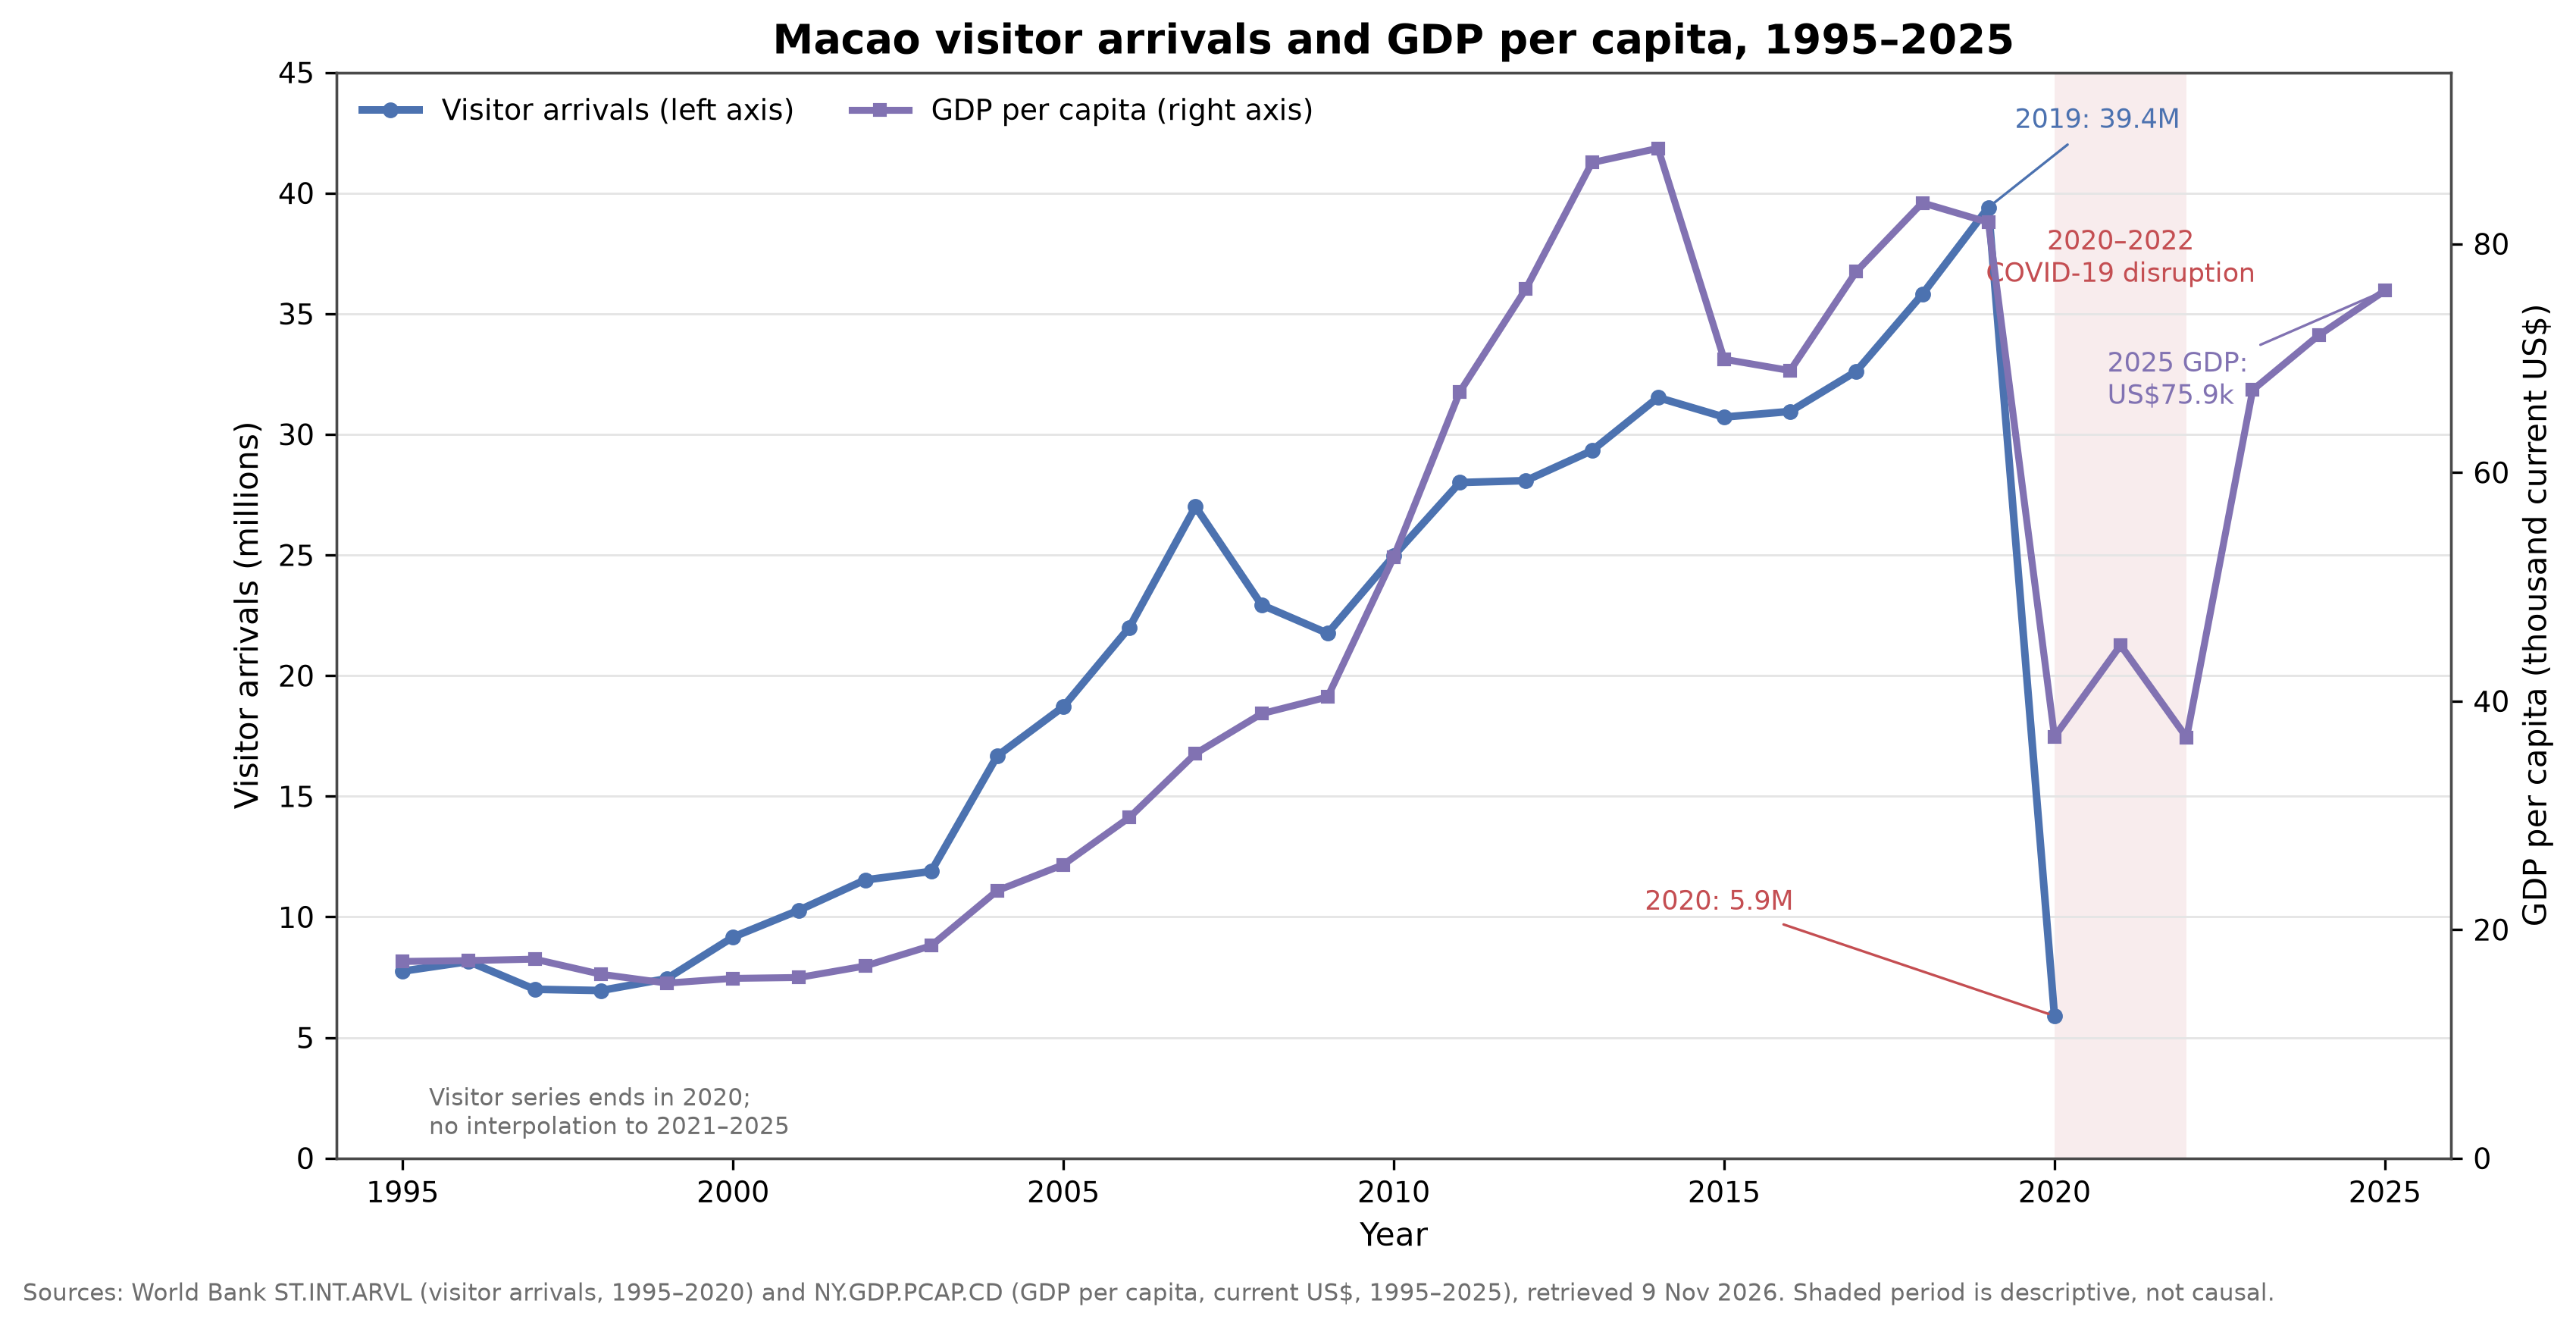

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/core/Figure_01_Long_Run_Trends.png


In [11]:
figure_01(annual)
display(Image(filename=str(CORE / 'Figure_01_Long_Run_Trends.png'), width=1100))
print('Saved:', CORE / 'Figure_01_Long_Run_Trends.png')

**Interpretation.** The dual-axis chart places the annual World Bank visitor series (1995–2020)
beside GDP per capita (1995–2025). Both grew strongly before the pandemic, although the two lines
use different units and should not be read as a causal mechanism. The visitor series stops in 2020
because World Bank observations are missing for 2021–2025; no values are interpolated. GDP per
capita is shown through 2025 to preserve its actual coverage. The 2020 collapse is a shock visible
in both series, while the post-2020 GDP rebound is not matched by an observed visitor series in
this source.

### Figure 2. Arrivals versus GDP per capita

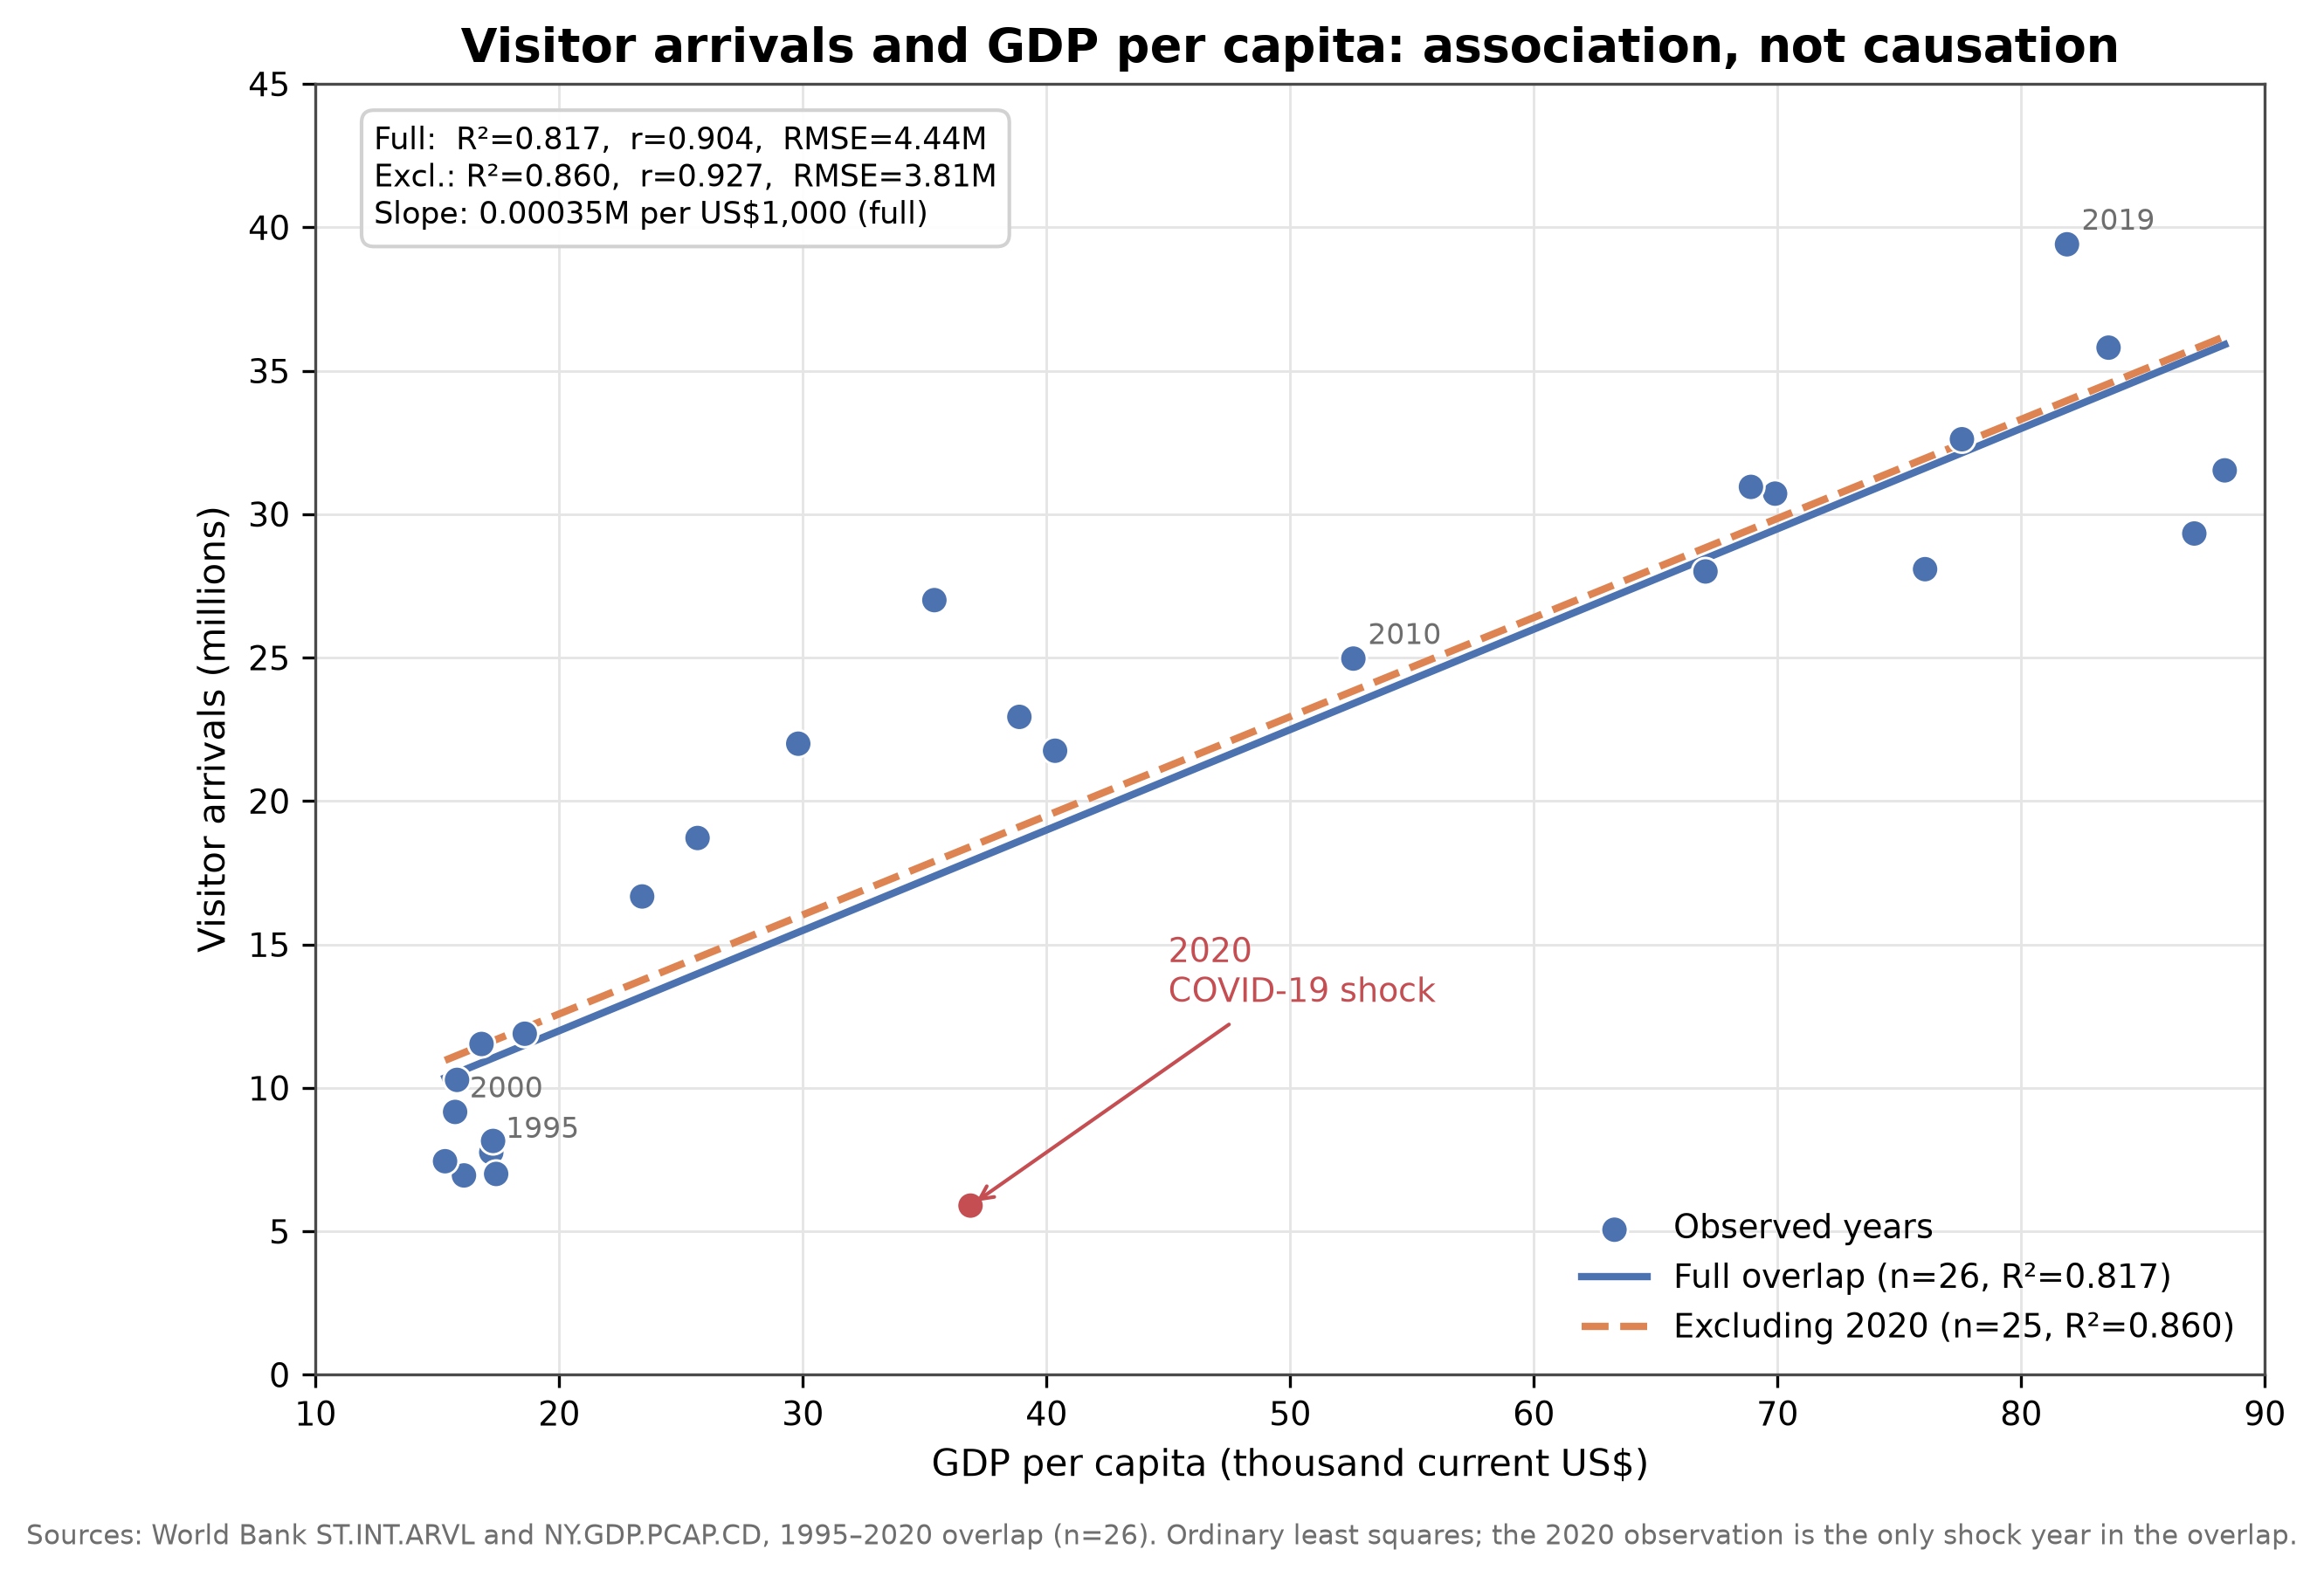

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/core/Figure_02_Arrivals_GDP_Scatter.png


In [12]:
metrics = figure_02(annual)
display(Image(filename=str(CORE / 'Figure_02_Arrivals_GDP_Scatter.png'), width=1100))
print('Saved:', CORE / 'Figure_02_Arrivals_GDP_Scatter.png')

**Interpretation.** The scatter plot and two ordinary least-squares fits show a strong positive
association over the 26 overlapping years, with R² = 0.817 including 2020 and R² = 0.860 when 2020
is excluded. The 2020 observation is far below the pre-pandemic relationship. The slope is
0.000350 million arrivals per additional US$1 of GDP per capita, or about 0.350 million per
US$1,000. This is an association, not a causal estimate: income, transport capacity, policy,
exchange rates and visitor preferences can all move together.

### Figure 3. Monthly visitor arrivals, 2008–2026

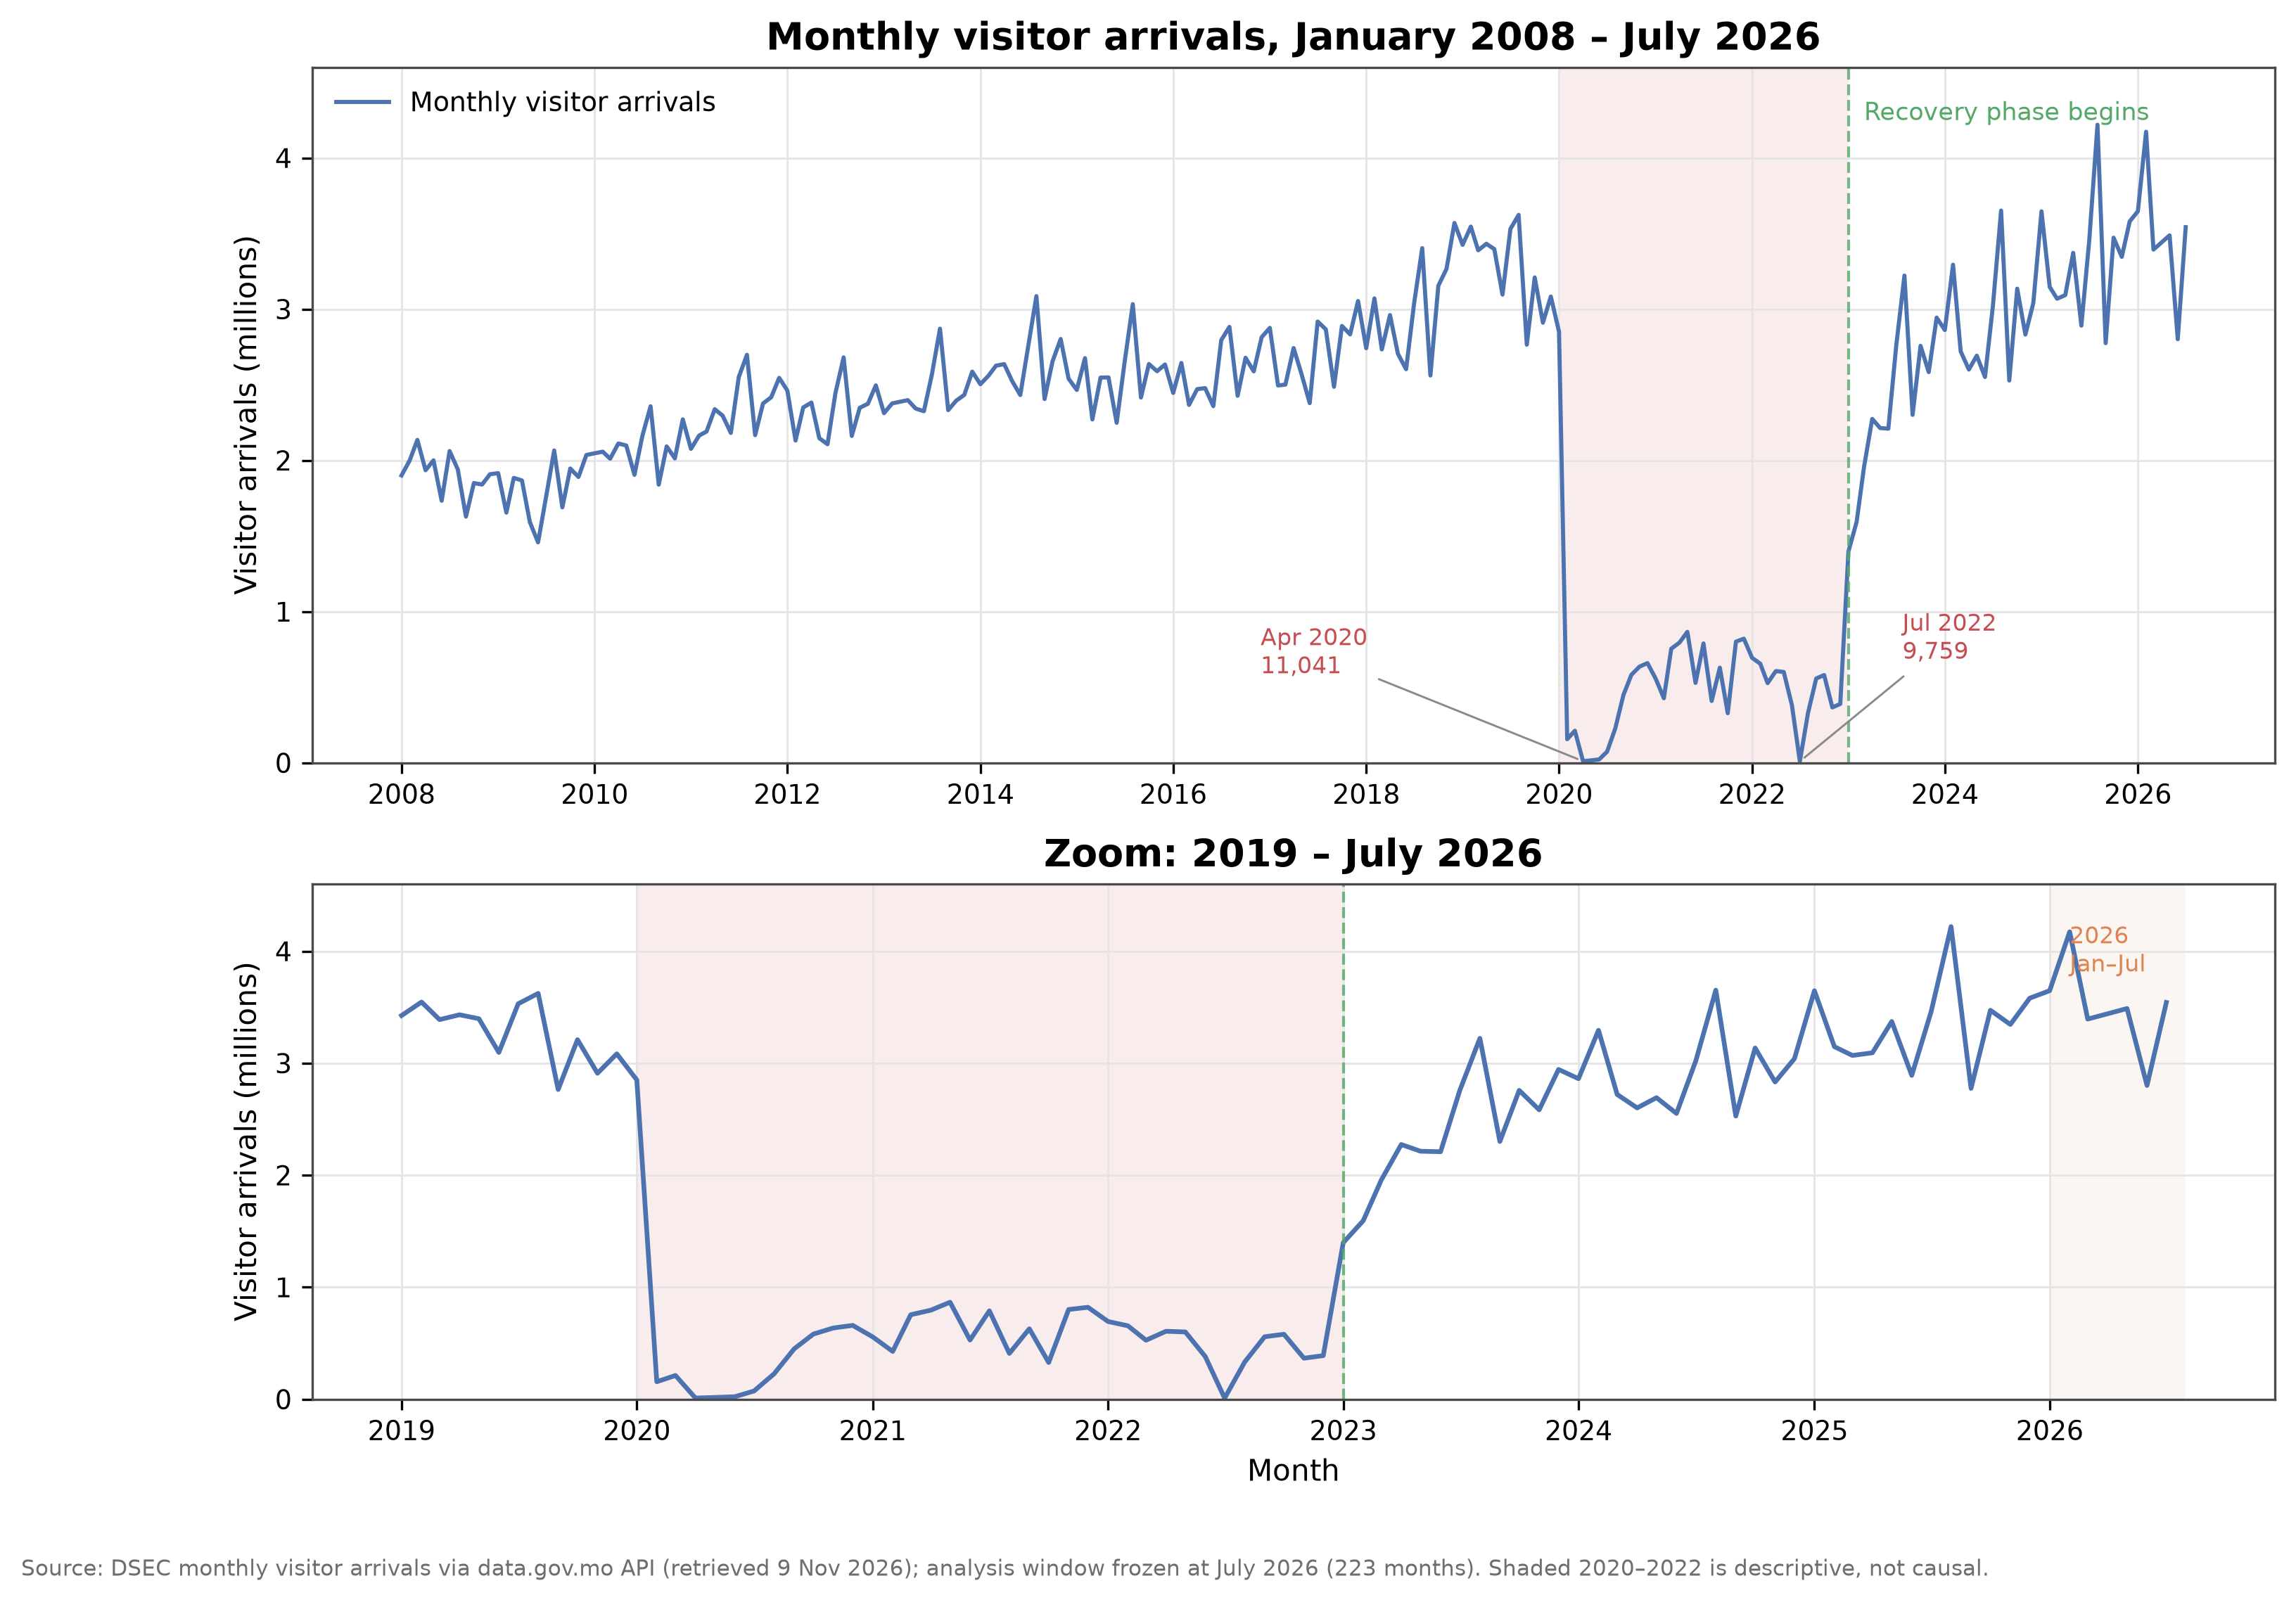

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/core/Figure_03_Monthly_Visitor_Trends.png


In [13]:
figure_03(monthly)
display(Image(filename=str(CORE / 'Figure_03_Monthly_Visitor_Trends.png'), width=1100))
print('Saved:', CORE / 'Figure_03_Monthly_Visitor_Trends.png')

**Interpretation.** The upper panel shows the full 223-month series and the lower panel zooms into
2019–2026. The pandemic interruption is abrupt: April 2020 recorded 11,041 arrivals, and the
lowest month in the frozen window is July 2022 at 9,759. The recovery phase begins in January 2023,
but the path is uneven and includes repeated monthly fluctuations. The shaded 2026 segment covers
January–July only, so it must not be compared mechanically with a full calendar year. The chart
describes volume, not tourism revenue or welfare.

### Figure 4. Additive seasonal decomposition

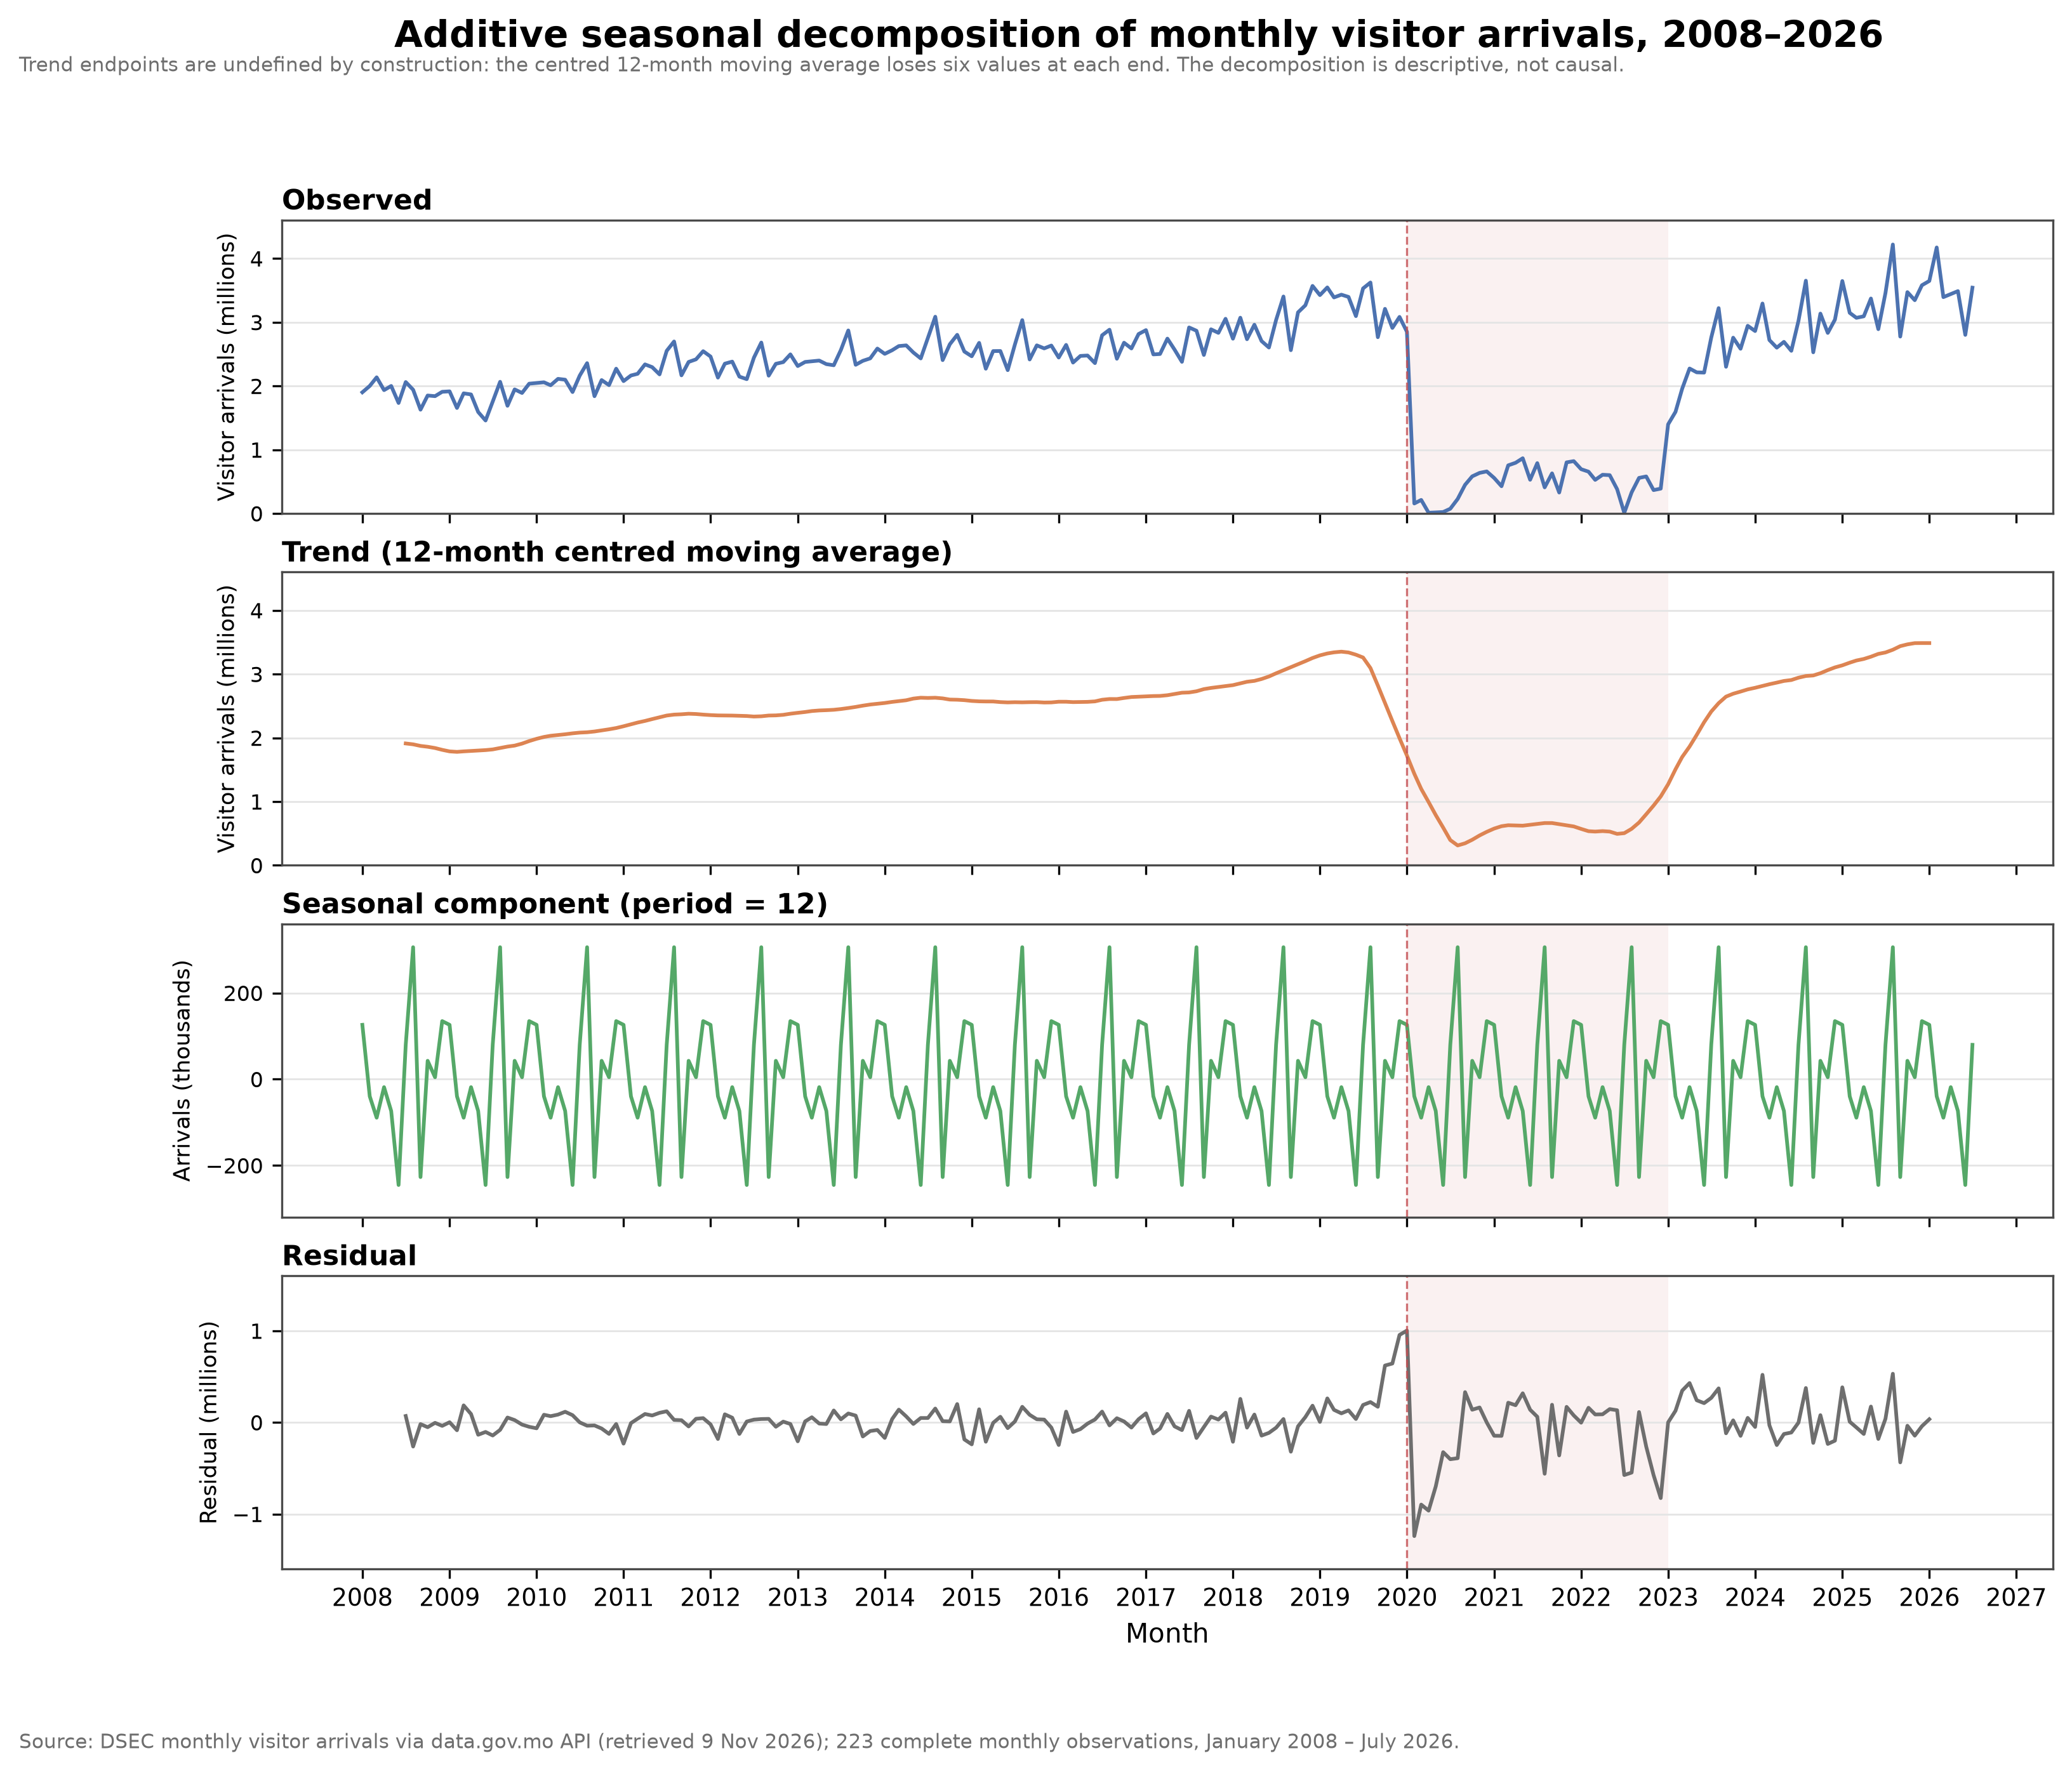

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/core/Figure_04_Seasonal_Decomposition.png


In [14]:
figure_04(monthly)
display(Image(filename=str(CORE / 'Figure_04_Seasonal_Decomposition.png'), width=1100))
print('Saved:', CORE / 'Figure_04_Seasonal_Decomposition.png')

**Interpretation.** The decomposition separates observed arrivals into a 12-month centred trend,
a repeating seasonal component and a residual. The trend loses six observations at each endpoint
by construction, and the residual is large during the pandemic because a stable additive seasonal
pattern cannot absorb a demand shock of that magnitude. August is the strongest seasonal peak in
the full-series decomposition, while June and September are the weakest months. The decomposition
is descriptive; it does not identify the causes of seasonality or imply that the seasonal pattern
is stable through the pandemic.

### Seasonal component estimates

In [15]:
series = monthly.set_index("month")["visitor_arrivals"].asfreq("MS").astype(float)
full_decomposition = seasonal_decompose(series, model="additive", period=12)
pre_2020_series = series.loc[:"2019-12-01"]
pre_2020_decomposition = seasonal_decompose(pre_2020_series, model="additive", period=12)

full_seasonal = full_decomposition.seasonal.groupby(full_decomposition.seasonal.index.month).mean() / 1e3
pre_2020_seasonal = pre_2020_decomposition.seasonal.groupby(pre_2020_decomposition.seasonal.index.month).mean() / 1e3
seasonal_table = pd.DataFrame(
    {
        "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
        "Full 2008–2026 (thousand arrivals)": full_seasonal.to_numpy(),
        "Pre-2020 2008–2019 (thousand arrivals)": pre_2020_seasonal.to_numpy(),
    }
)
display(seasonal_table)
print("Trend NaNs in full decomposition:", int(full_decomposition.trend.isna().sum()))
print("Residual NaNs in full decomposition:", int(full_decomposition.resid.isna().sum()))
print(
    "Full-series seasonal range: "
    f"{full_seasonal.min():,.1f}k to {full_seasonal.max():,.1f}k"
)
print(
    "Pre-2020 seasonal range: "
    f"{pre_2020_seasonal.min():,.1f}k to {pre_2020_seasonal.max():,.1f}k"
)

,Month,Full 2008–2026 (thousand arrivals),Pre-2020 2008–2019 (thousand arrivals)
0,Jan,126.0660,9.5133
1,Feb,-39.7104,7.3109
2,Mar,-89.2900,-63.9819
3,Apr,-18.4960,33.7223
4,May,-73.8416,-83.7817
5,Jun,-245.3506,-238.2829
6,Jul,79.6864,112.3627
7,Aug,306.0736,300.5063
8,Sep,-226.9544,-234.9499
9,Oct,42.6322,18.9422


Trend NaNs in full decomposition: 12
Residual NaNs in full decomposition: 12
Full-series seasonal range: -245.4k to 306.1k
Pre-2020 seasonal range: -238.3k to 300.5k


The full-series decomposition produces a seasonal range of roughly −245k to +306k arrivals.
The August peak is stable in both the full and pre-2020 decompositions, but the disruption phase
changes the scale and interpretation of the residual. The seasonal component is an average pattern;
it is not a forecast, and it cannot absorb a one-off border closure or demand shock.

### Figure 5. Year × month heatmap

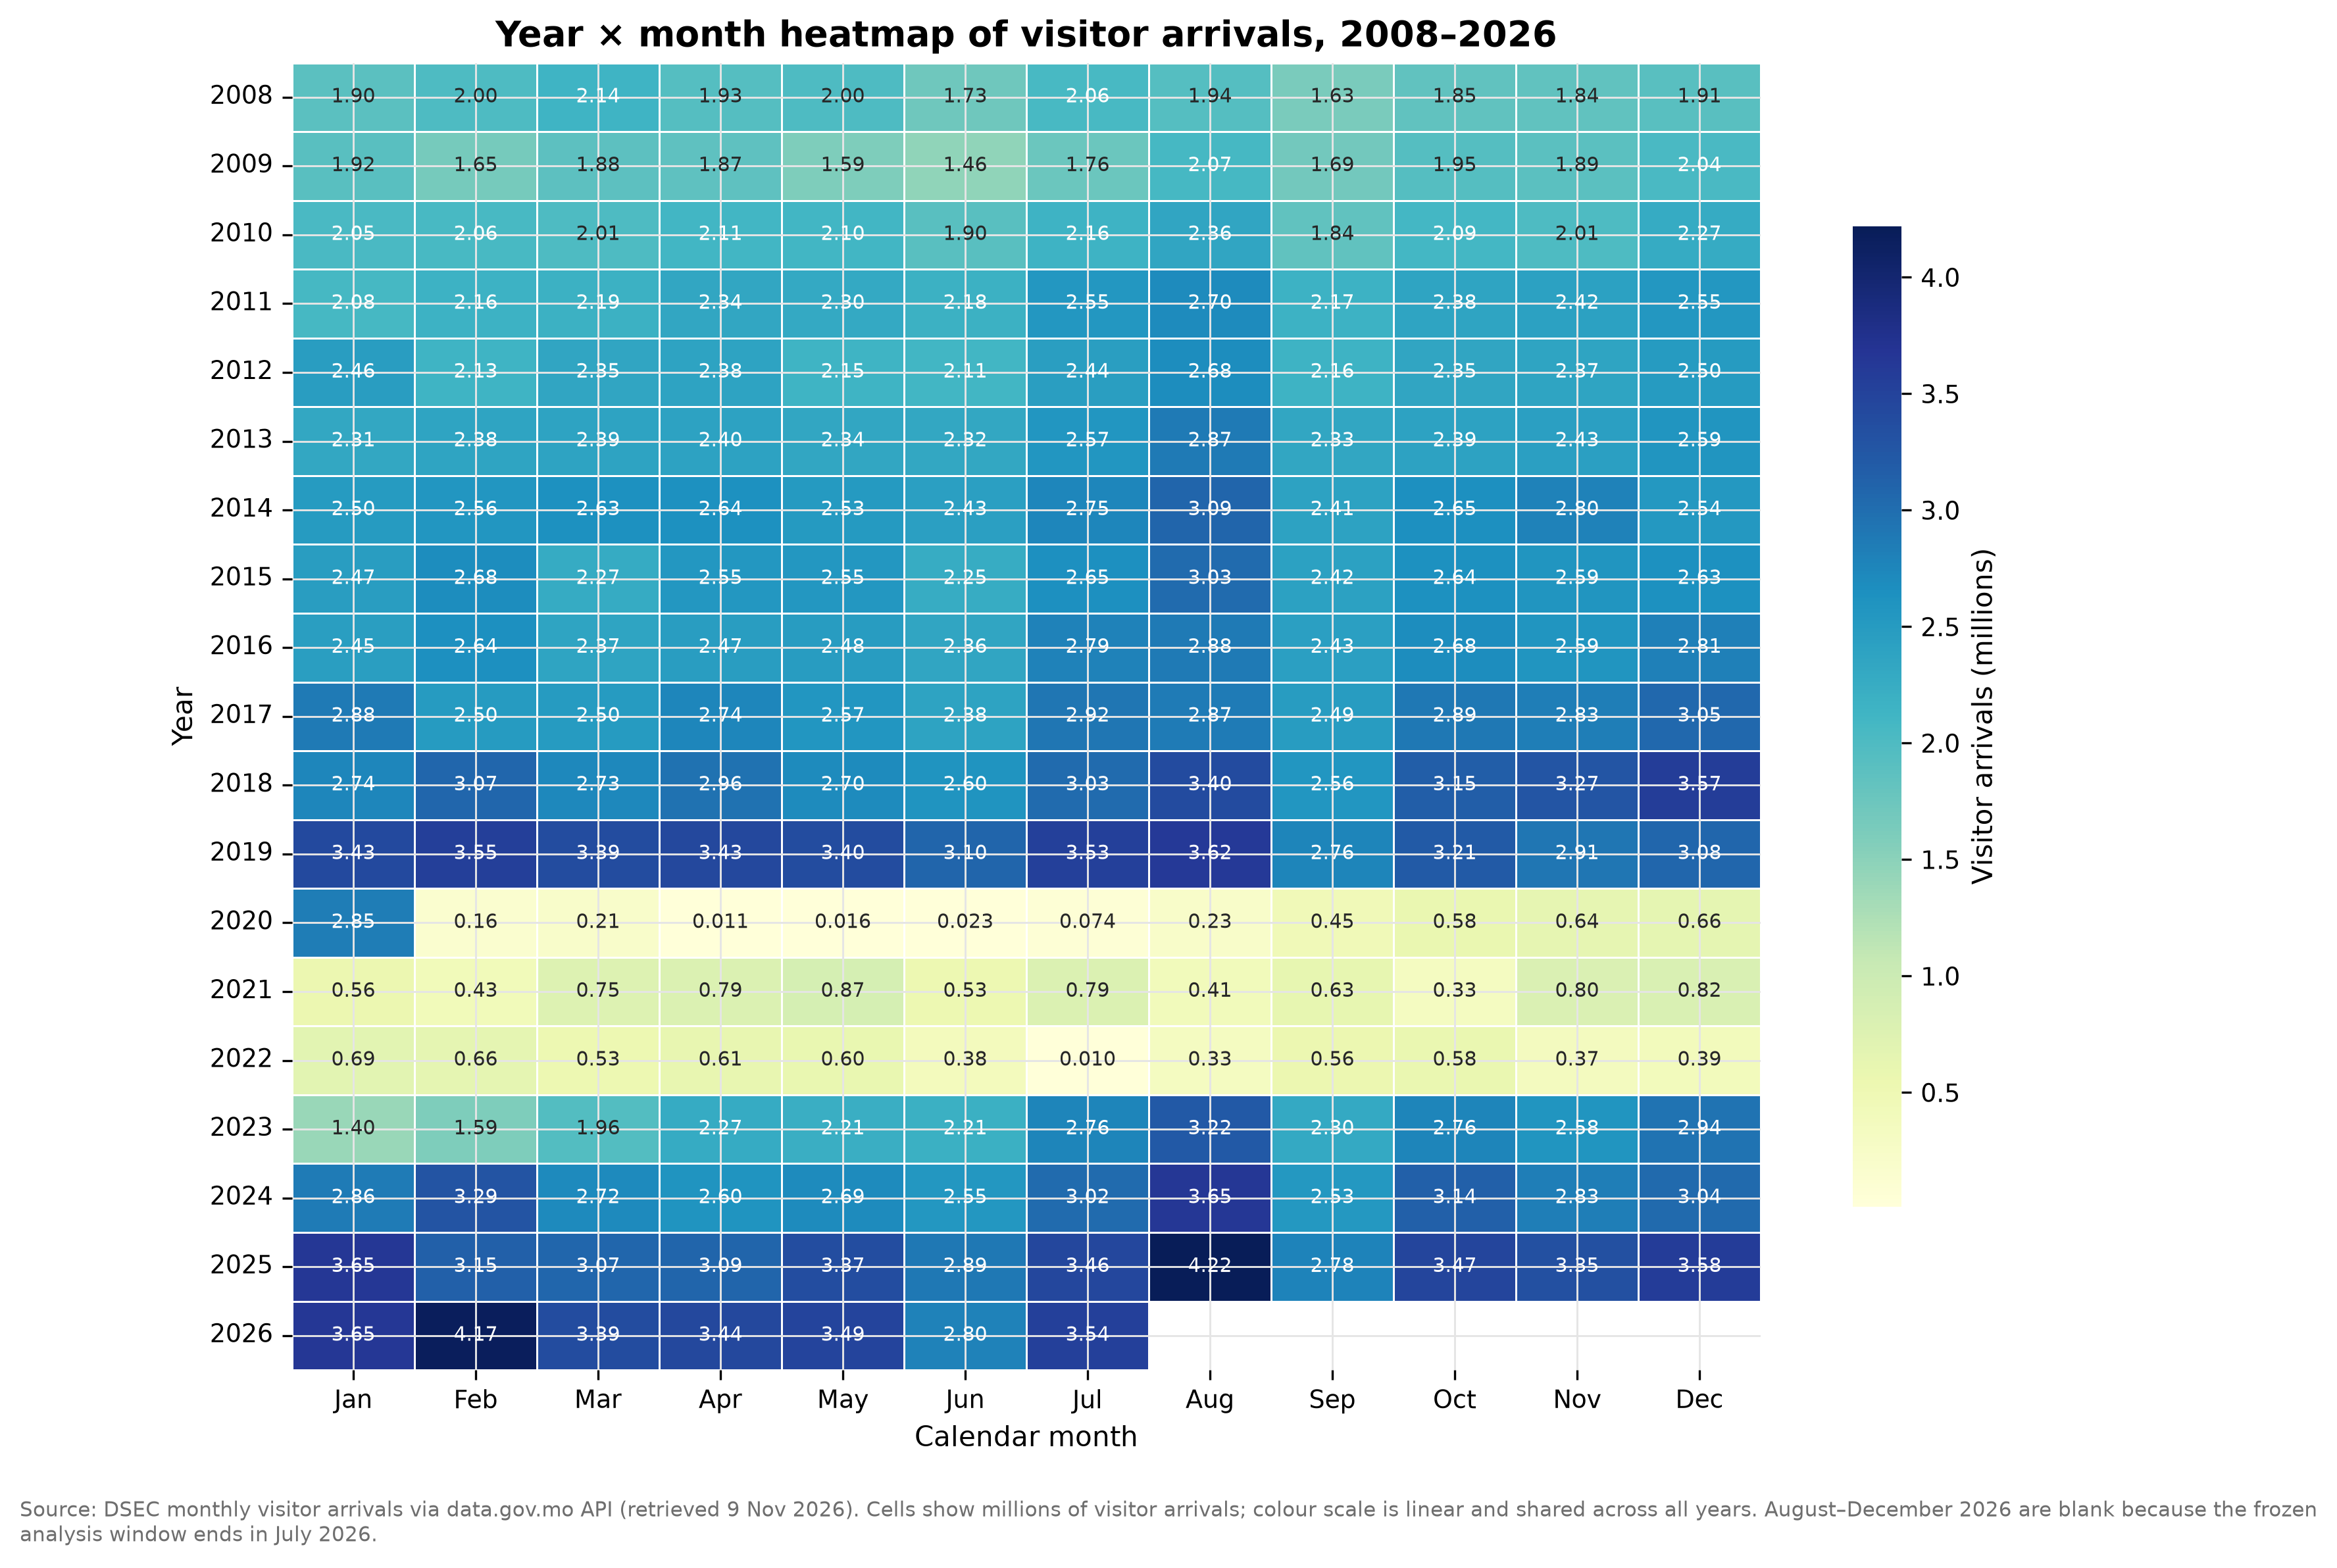

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/core/Figure_05_Year_Month_Heatmap.png


In [16]:
figure_05(monthly)
display(Image(filename=str(CORE / 'Figure_05_Year_Month_Heatmap.png'), width=1100))
print('Saved:', CORE / 'Figure_05_Year_Month_Heatmap.png')

**Interpretation.** The heatmap makes both the long-run level shift and the monthly rhythm visible.
The 2019 row is consistently dark, the 2020 row turns pale after January, and 2021–2022 remain
weak. From 2023 onward the cells become darker again, with 2025 reaching the highest values in the
series. August 2025 is the single darkest cell at 4.22 million arrivals. The 2026 row is blank
after July by design; the blank cells are missing observations, not zeros. Colour is linear and
shared across years, so the visual comparison is consistent.

### Figure 6. Recovery index relative to 2019

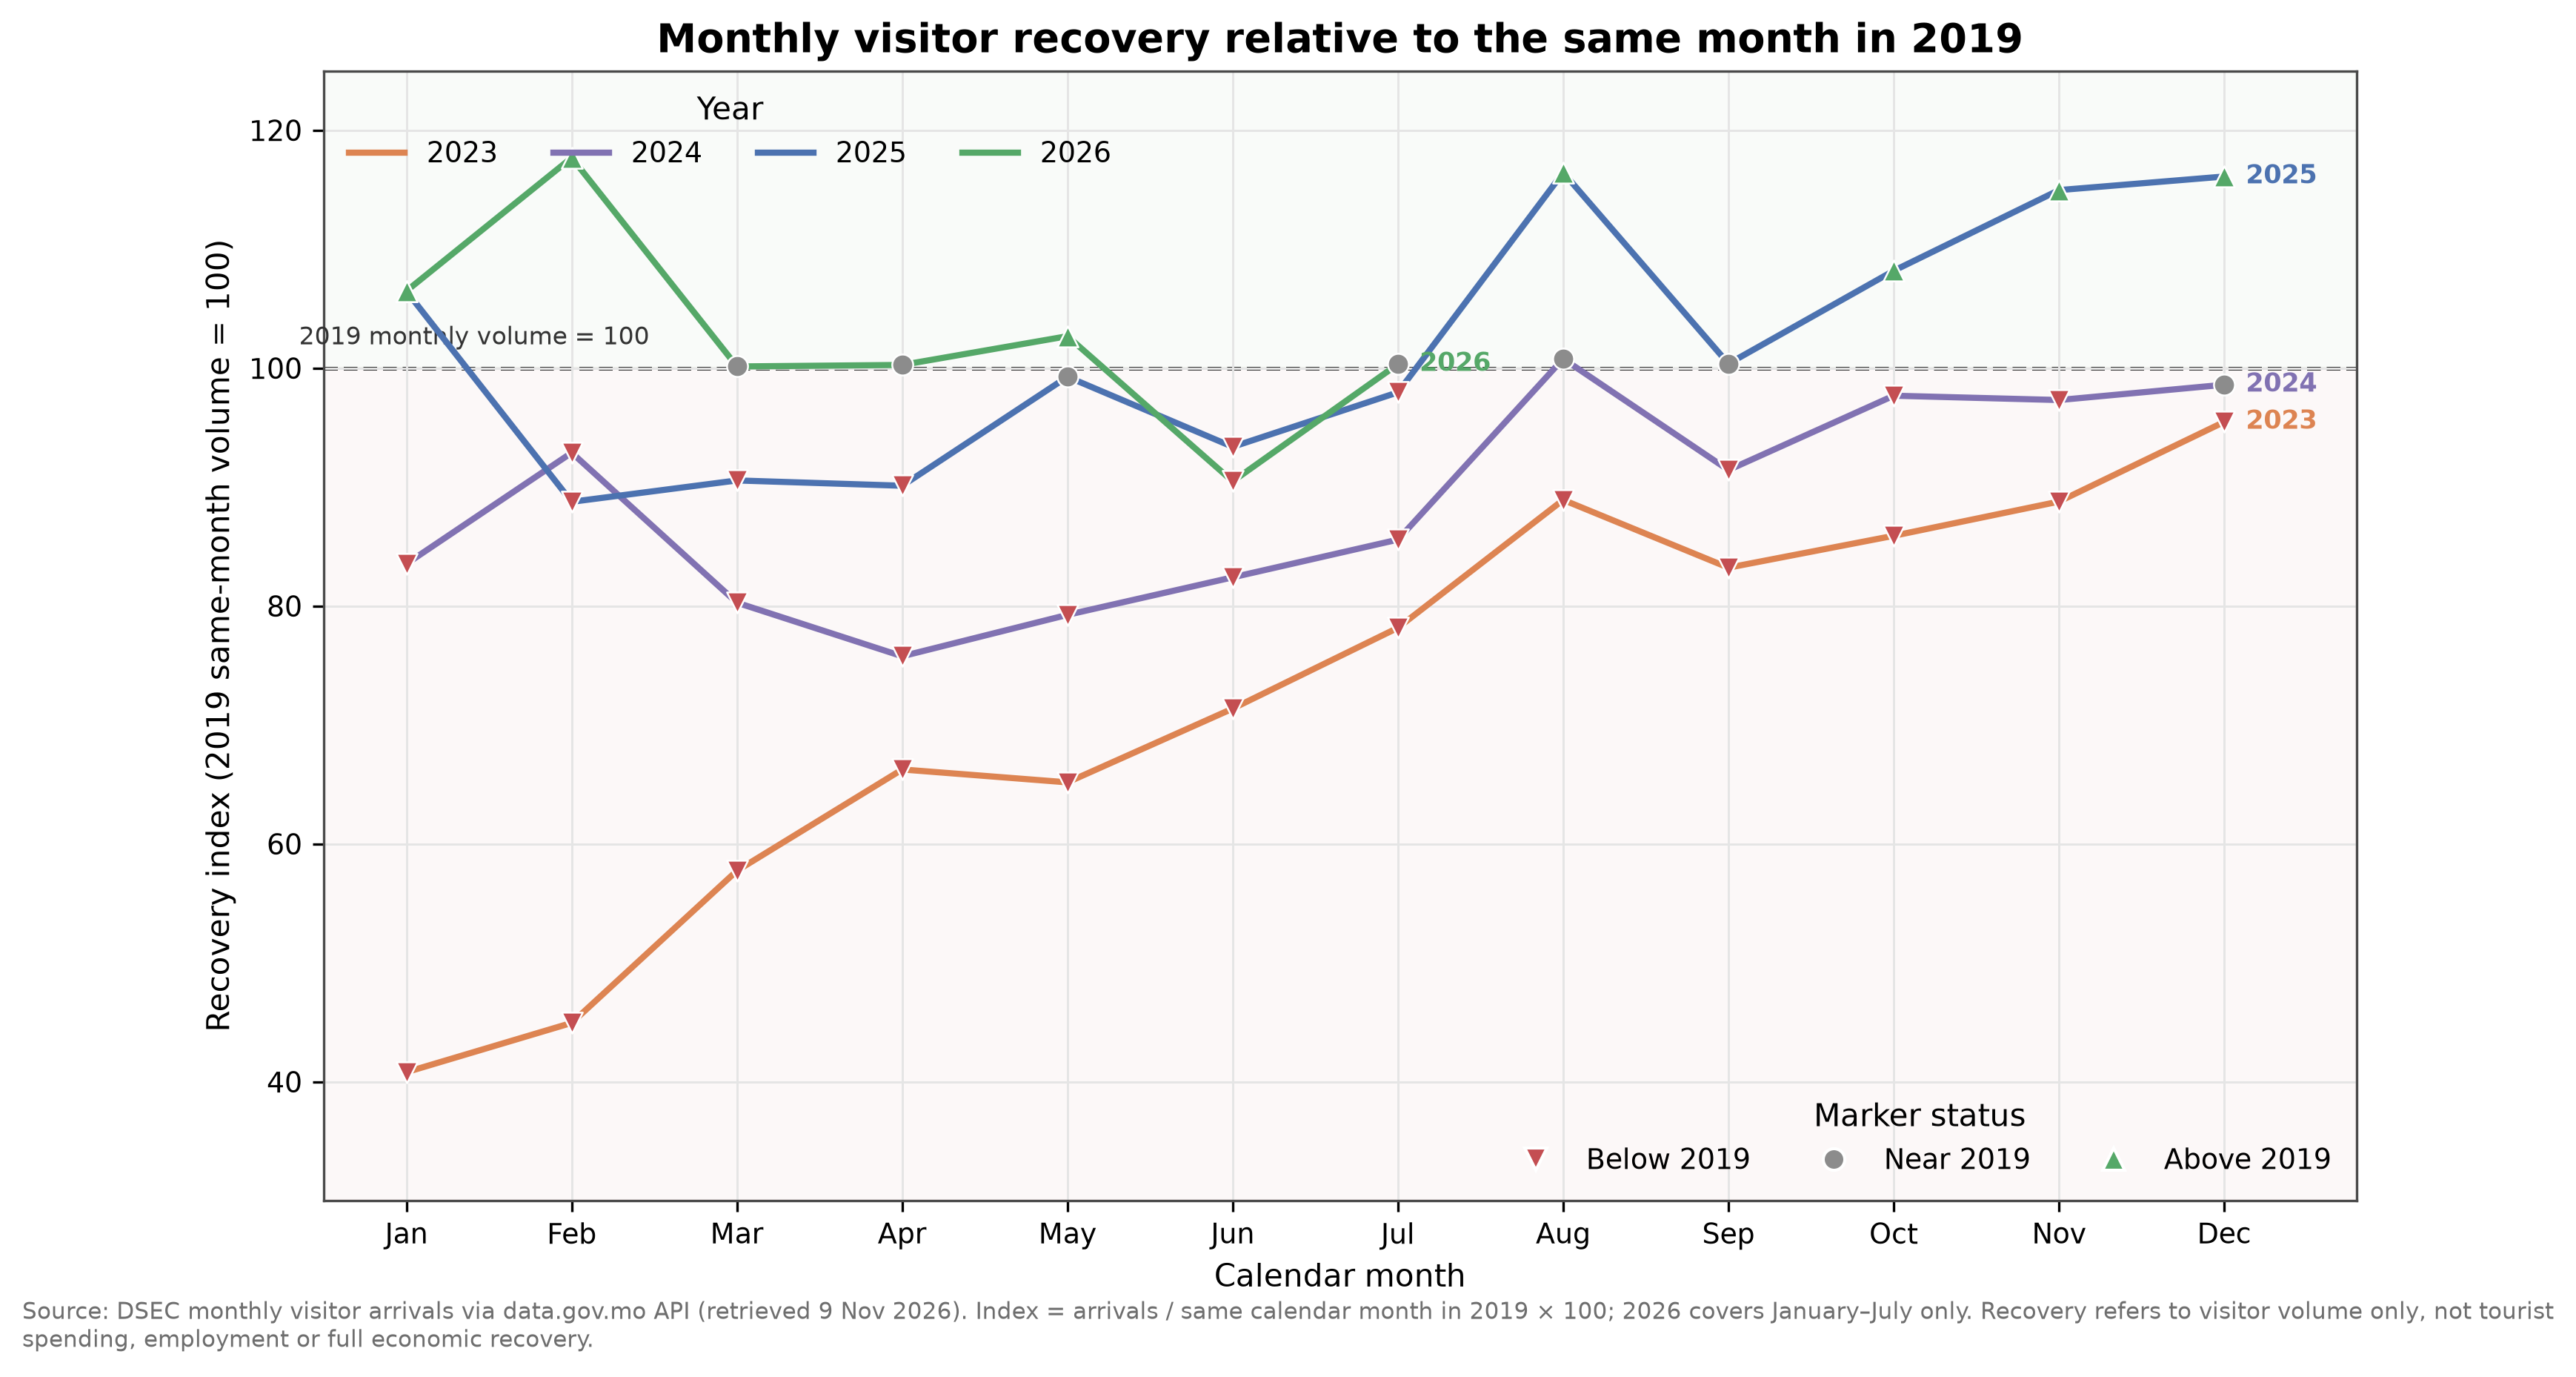

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/core/Figure_06_Recovery_Index.png


In [17]:
figure_06(monthly)
display(Image(filename=str(CORE / 'Figure_06_Recovery_Index.png'), width=1100))
print('Saved:', CORE / 'Figure_06_Recovery_Index.png')

**Interpretation.** The index compares each month with the same calendar month in 2019. In 2026,
January was 106.5, February 117.7, March 100.1, April 100.3, May 102.7, June 90.5 and July 100.3.
This means visitor volume was at or above the 2019 level in most of the observed 2026 months, but
June remained below it. The 100 line is a volume benchmark only: it does not measure tourist
spending, hotel occupancy, employment or the wider Macao economy. The 2026 line stops in July.

### 2026 recovery values

In [18]:
recovery_2026 = monthly.loc[
    monthly.year.eq(2026), ["month", "month_number", "visitor_arrivals", "recovery_index"]
].copy()
recovery_2026["2019 same-month arrivals"] = recovery_2026.month_number.map(
    monthly.loc[monthly.year.eq(2019)].set_index("month_number")["visitor_arrivals"]
)
display(recovery_2026)
print("Recovery index = 100 means the same monthly visitor volume as 2019, not complete economic recovery.")

,month,month_number,visitor_arrivals,recovery_index,2019 same-month arrivals
216,2026-01-01,1,3647328,106.4874,3425126
217,2026-02-01,2,4172940,117.6901,3545701
218,2026-03-01,3,3393636,100.1388,3388931
219,2026-04-01,4,3441396,100.2683,3432187
220,2026-05-01,5,3487994,102.6836,3396835
221,2026-06-01,6,2801152,90.4808,3095853
222,2026-07-01,7,3542218,100.3395,3530233


Recovery index = 100 means the same monthly visitor volume as 2019, not complete economic recovery.


### Figure 7. Source-market composition in 2025

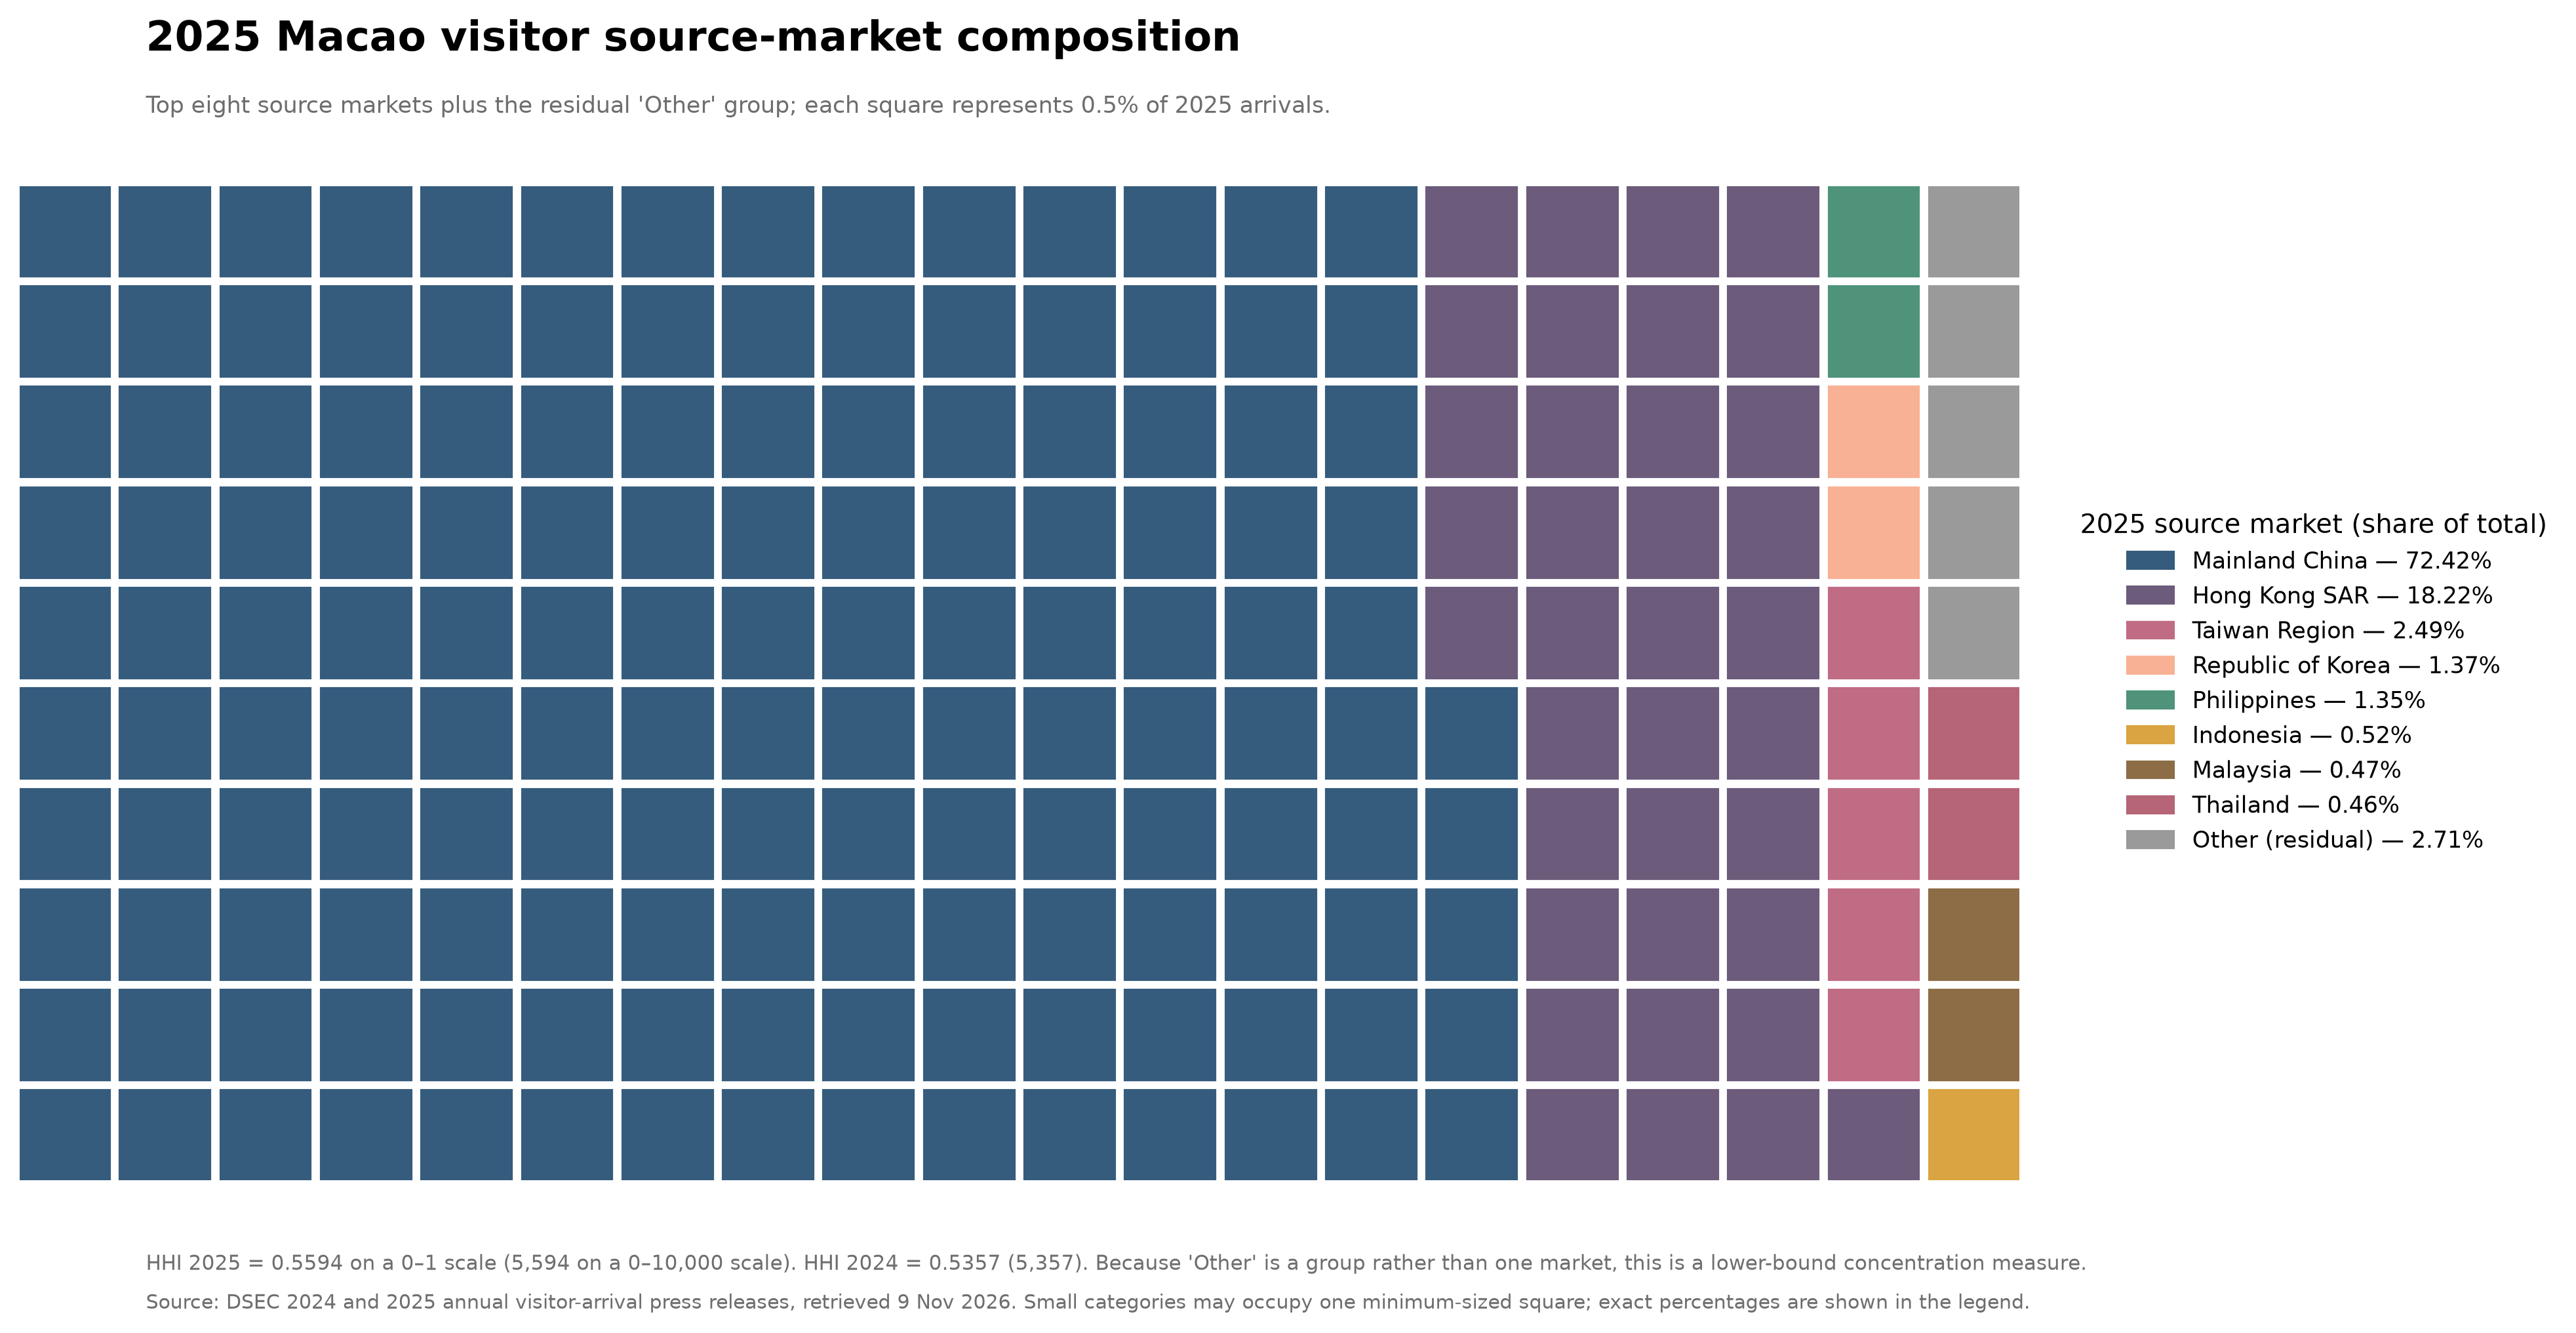

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/core/Figure_07_Source_Market_Composition.png


In [19]:
figure_07(source_markets)
display(Image(filename=str(CORE / 'Figure_07_Source_Market_Composition.png'), width=1100))
print('Saved:', CORE / 'Figure_07_Source_Market_Composition.png')

**Interpretation.** Mainland China supplied 72.42% of 2025 visitor arrivals, Hong Kong SAR 18.22%
and Taiwan Region 2.49%. The top eight markets plus the residual group produce an HHI of 0.5594
on a 0–1 scale (5,594 on a 0–10,000 scale), which is a highly concentrated market structure. The
HHI is a lower bound because "Other" combines several origins rather than representing one market.
The waffle preserves the approximate shares visually, while the legend gives exact percentages.

### Market concentration calculation

In [20]:
market_hhi = source_markets.assign(
    squared_share_2024=lambda d: (d.share_2024_pct / 100) ** 2,
    squared_share_2025=lambda d: (d.share_2025_pct / 100) ** 2,
)
hhi_2024 = market_hhi.squared_share_2024.sum()
hhi_2025 = market_hhi.squared_share_2025.sum()
display(
    pd.DataFrame(
        {
            "Year": [2024, 2025],
            "HHI (0–1)": [hhi_2024, hhi_2025],
            "HHI (0–10,000)": [hhi_2024 * 10000, hhi_2025 * 10000],
            "Total visitor arrivals": [
                source_markets.arrivals_2024.sum(),
                source_markets.arrivals_2025.sum(),
            ],
        }
    )
)
display(source_markets[["market", "arrivals_2024", "arrivals_2025", "share_2025_pct", "yoy_pct"]])

,Year,HHI (0–1),"HHI (0–10,000)",Total visitor arrivals
0,2024,0.5357,"5,356.7117","34,928,650.0000"
1,2025,0.5594,"5,594.1345","40,069,360.0000"


,market,arrivals_2024,arrivals_2025,share_2025_pct,yoy_pct
0,Mainland China,"24,491,424.0000","29,017,164.0000",72.4173,18.4789
1,Hong Kong SAR,"7,179,722.0000","7,300,582.0000",18.2199,1.6834
2,Taiwan Region,"834,411.0000","996,140.0000",2.4860,19.3824
3,Republic of Korea,"492,184.0000","547,638.0000",1.3667,11.2669
4,Philippines,"493,399.0000","540,284.0000",1.3484,9.5025
5,Indonesia,"183,062.0000","208,043.0000",0.5192,13.6462
6,Malaysia,"181,941.0000","188,977.0000",0.4716,3.8672
7,Thailand,"134,658.0000","185,963.0000",0.4641,38.1002
8,Other (residual),"937,849.0000","1,084,569.0000",2.7067,15.6443


### Figure 8. Entry checkpoint map and volumes

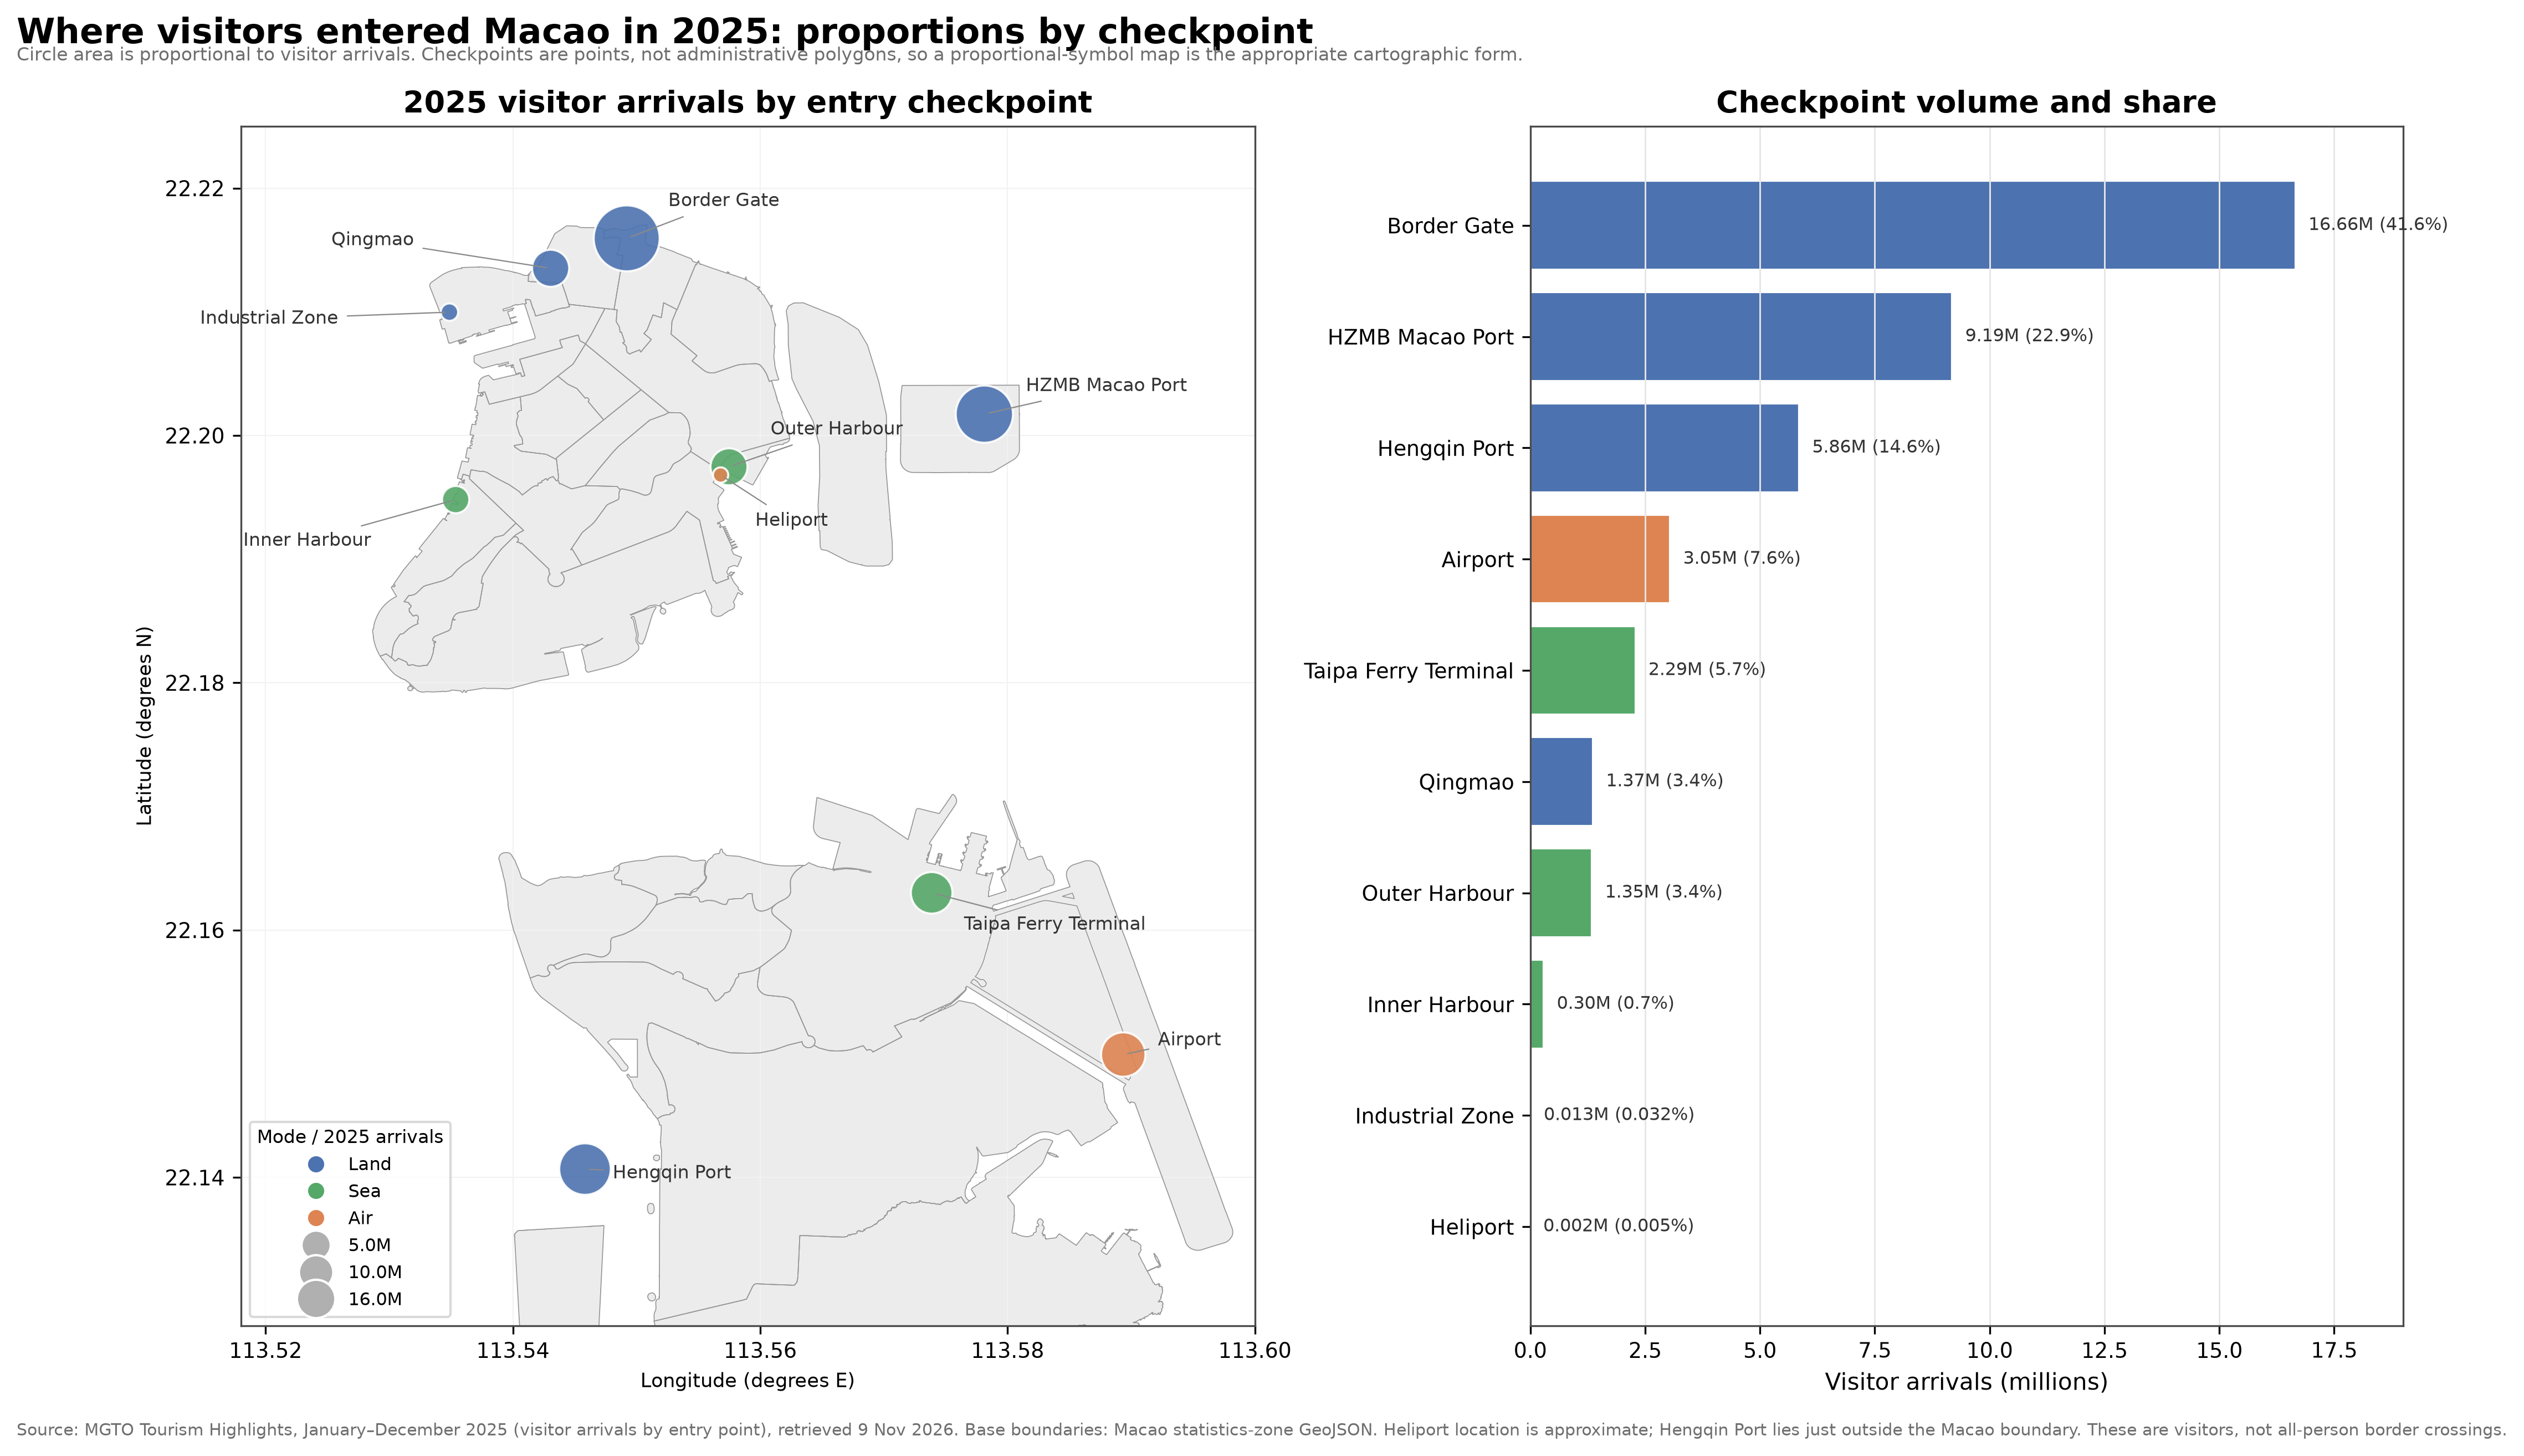

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/core/Figure_08_Entry_Point_Choropleth.png


In [21]:
figure_08()
display(Image(filename=str(CORE / 'Figure_08_Entry_Point_Choropleth.png'), width=1100))
print('Saved:', CORE / 'Figure_08_Entry_Point_Choropleth.png')

**Interpretation.** The map uses MGTO 2025 visitor arrivals by entry point and a real Macao
statistics-zone boundary. Circle area is proportional to arrivals; colour identifies land, sea and
air. Border Gate handled 16.66 million visitors (41.6%), HZMB Macao Port 9.19 million (22.9%) and
Hengqin Port 5.86 million (14.6%). Checkpoints are points rather than administrative polygons,
so a proportional-symbol map is more defensible than a checkpoint choropleth. The heliport
coordinate is approximate, and Hengqin Port lies just outside the Macao boundary. These figures
are visitors, not all-person border crossings.

### Entry-point reconciliation

In [22]:
mode_summary = (
    entry_points.groupby("mode", as_index=False)["visitor_arrivals_2025"]
    .sum()
    .assign(share_2025_pct=lambda d: d.visitor_arrivals_2025 / d.visitor_arrivals_2025.sum() * 100)
    .sort_values("visitor_arrivals_2025", ascending=False)
)
display(mode_summary)
display(entry_points.sort_values("visitor_arrivals_2025", ascending=False))
print("Entry-point total:", f"{entry_points.visitor_arrivals_2025.sum():,}")
print("These are visitor arrivals, not DSEC all-person border crossings.")

,mode,visitor_arrivals_2025,share_2025_pct
1,Land,33084253,82.5675
2,Sea,3935435,9.8216
0,Air,3049672,7.6110


,mode,checkpoint,visitor_arrivals_2025,share_2025_pct
0,Land,Checkpoint of Border Gate,16658849,41.5750
3,Land,Checkpoint of Macao Port Administration Area o...,9187786,22.9297
1,Land,Checkpoint of the Macao Port Area at Hengqin Port,5856198,14.6152
8,Air,Airport,3047559,7.6057
6,Sea,Taipa Ferry Terminal,2291013,5.7176
4,Land,Checkpoint of Qingmao,1368493,3.4153
5,Sea,Outer Harbour Ferry Terminal,1347257,3.3623
7,Sea,Inner Harbour Ferry Terminal,297165,0.7416
2,Land,Checkpoint of the Zhuhai-Macao Cross-Border In...,12927,0.0323
9,Air,Heliport of Outer Harbour Ferry Terminal,2113,0.0053


Entry-point total: 40,069,360
These are visitor arrivals, not DSEC all-person border crossings.


The mode totals reconcile exactly to the published 2025 visitor-arrival total of 40,069,360.
The DSEC border-crossing table is not substituted here because it counts all persons, including
commuters and residents, rather than visitors.

### District distribution, January–July 2026

In [23]:
display(
    districts.head(10)[
        ["DISTRICT_EN", "visitor_person_times_2026_jan_jul", "share_2026_jan_jul_pct"]
    ].rename(
        columns={
            "DISTRICT_EN": "District",
            "visitor_person_times_2026_jan_jul": "Visitor person-times, Jan–Jul 2026",
            "share_2026_jan_jul_pct": "Share (%)",
        }
    )
)
print(
    "District values are person-times, not unique visitor counts. "
    f"Top district share: {districts.iloc[0].share_2026_jan_jul_pct:.2f}%."
)

,District,"Visitor person-times, Jan–Jul 2026",Share (%)
0,COTAI Reclamation Area,50531775,28.1758
1,Baixa de Macau,18937324,10.5592
2,Novos Aterros do Porto Exterior & Aterros da B...,18407142,10.2636
3,Zona de Aterros do Porto Exterior,15841342,8.8329
4,Areia Preta & Iao Hon,13383908,7.4627
5,Cidade & Hipódromo da Taipa,11370845,6.3402
6,Pac On & Taipa Grande,10310530,5.7490
7,Patane & São Paulo,8600478,4.7955
8,Baixa da Taipa,5232962,2.9178
9,Tamagnini Barbosa,4098445,2.2852


District values are person-times, not unique visitor counts. Top district share: 28.18%.


## 8. Supplementary visualizations

The supplementary figures are not duplicates: they examine distributions, phase-specific
seasonality, extreme growth rates, hotel co-movement, HHI contributions, before/after comparisons
and the district geography.

### Figure S1. Yearly distribution

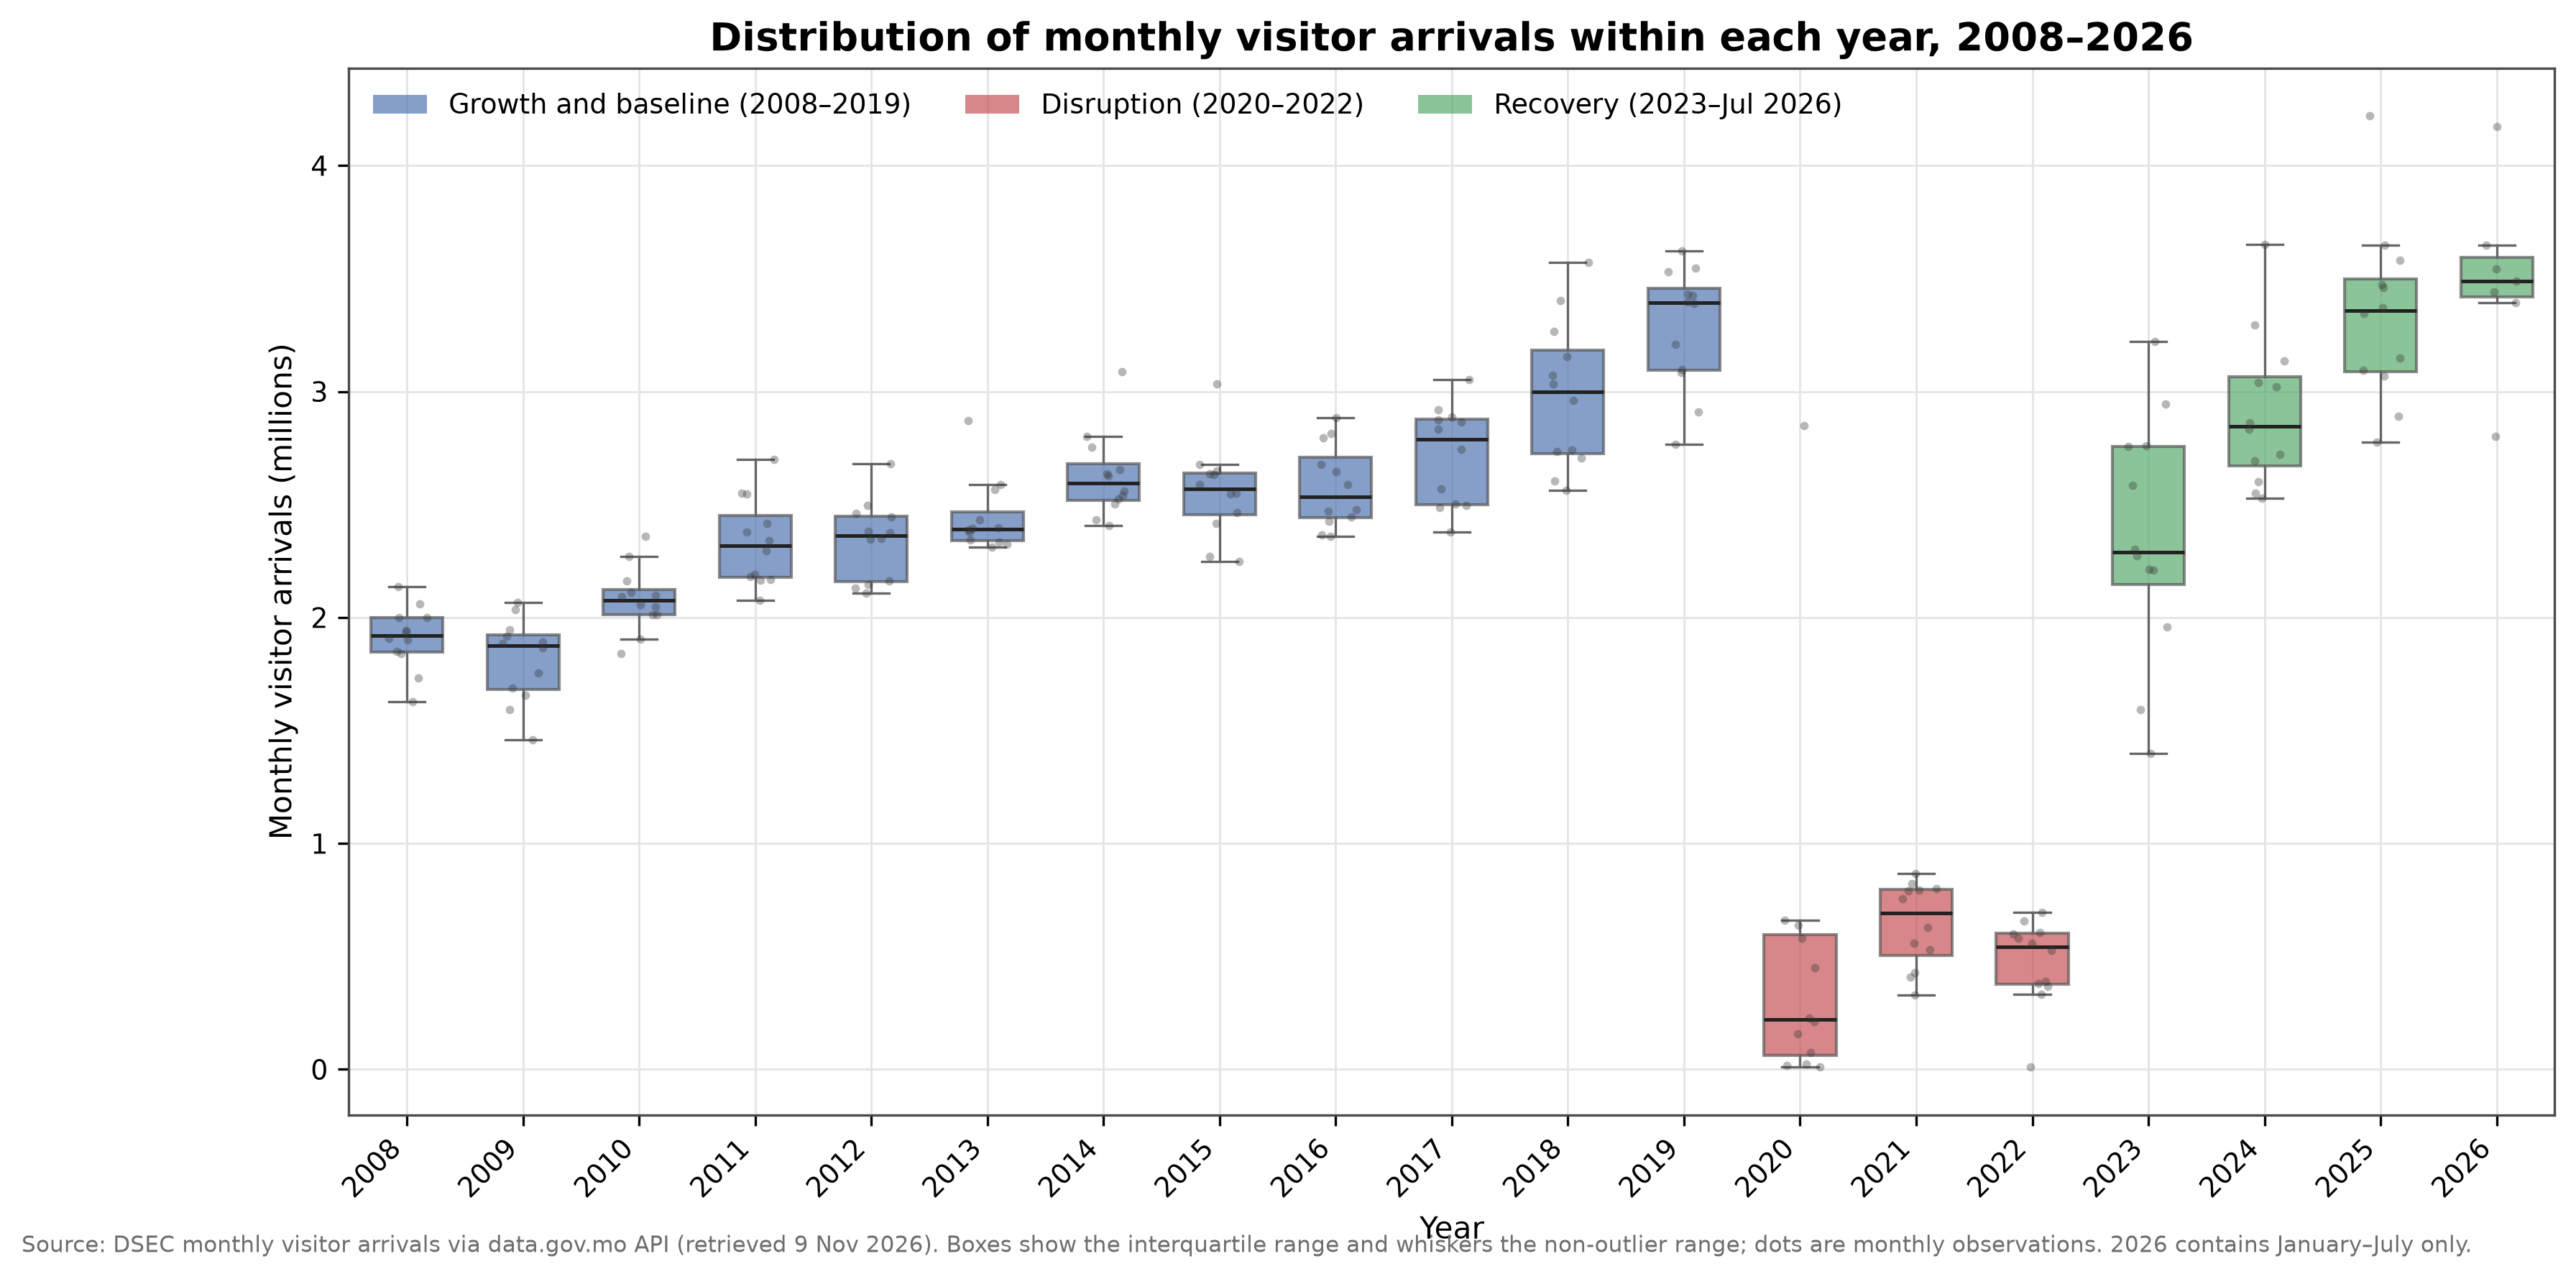

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/supplementary/Figure_S01_Yearly_Boxplot.png


In [24]:
figure_s01(monthly)
display(Image(filename=str(SUPP / 'Figure_S01_Yearly_Boxplot.png'), width=1100))
print('Saved:', SUPP / 'Figure_S01_Yearly_Boxplot.png')

**Interpretation.** The distributions show a clear level shift in 2020–2022 and a gradual return
toward pre-pandemic levels from 2023. Within-year dispersion is large, so annual totals alone
would hide the severity of the monthly troughs. The 2026 box uses seven months only.

### Figure S2. Seasonal profile by phase

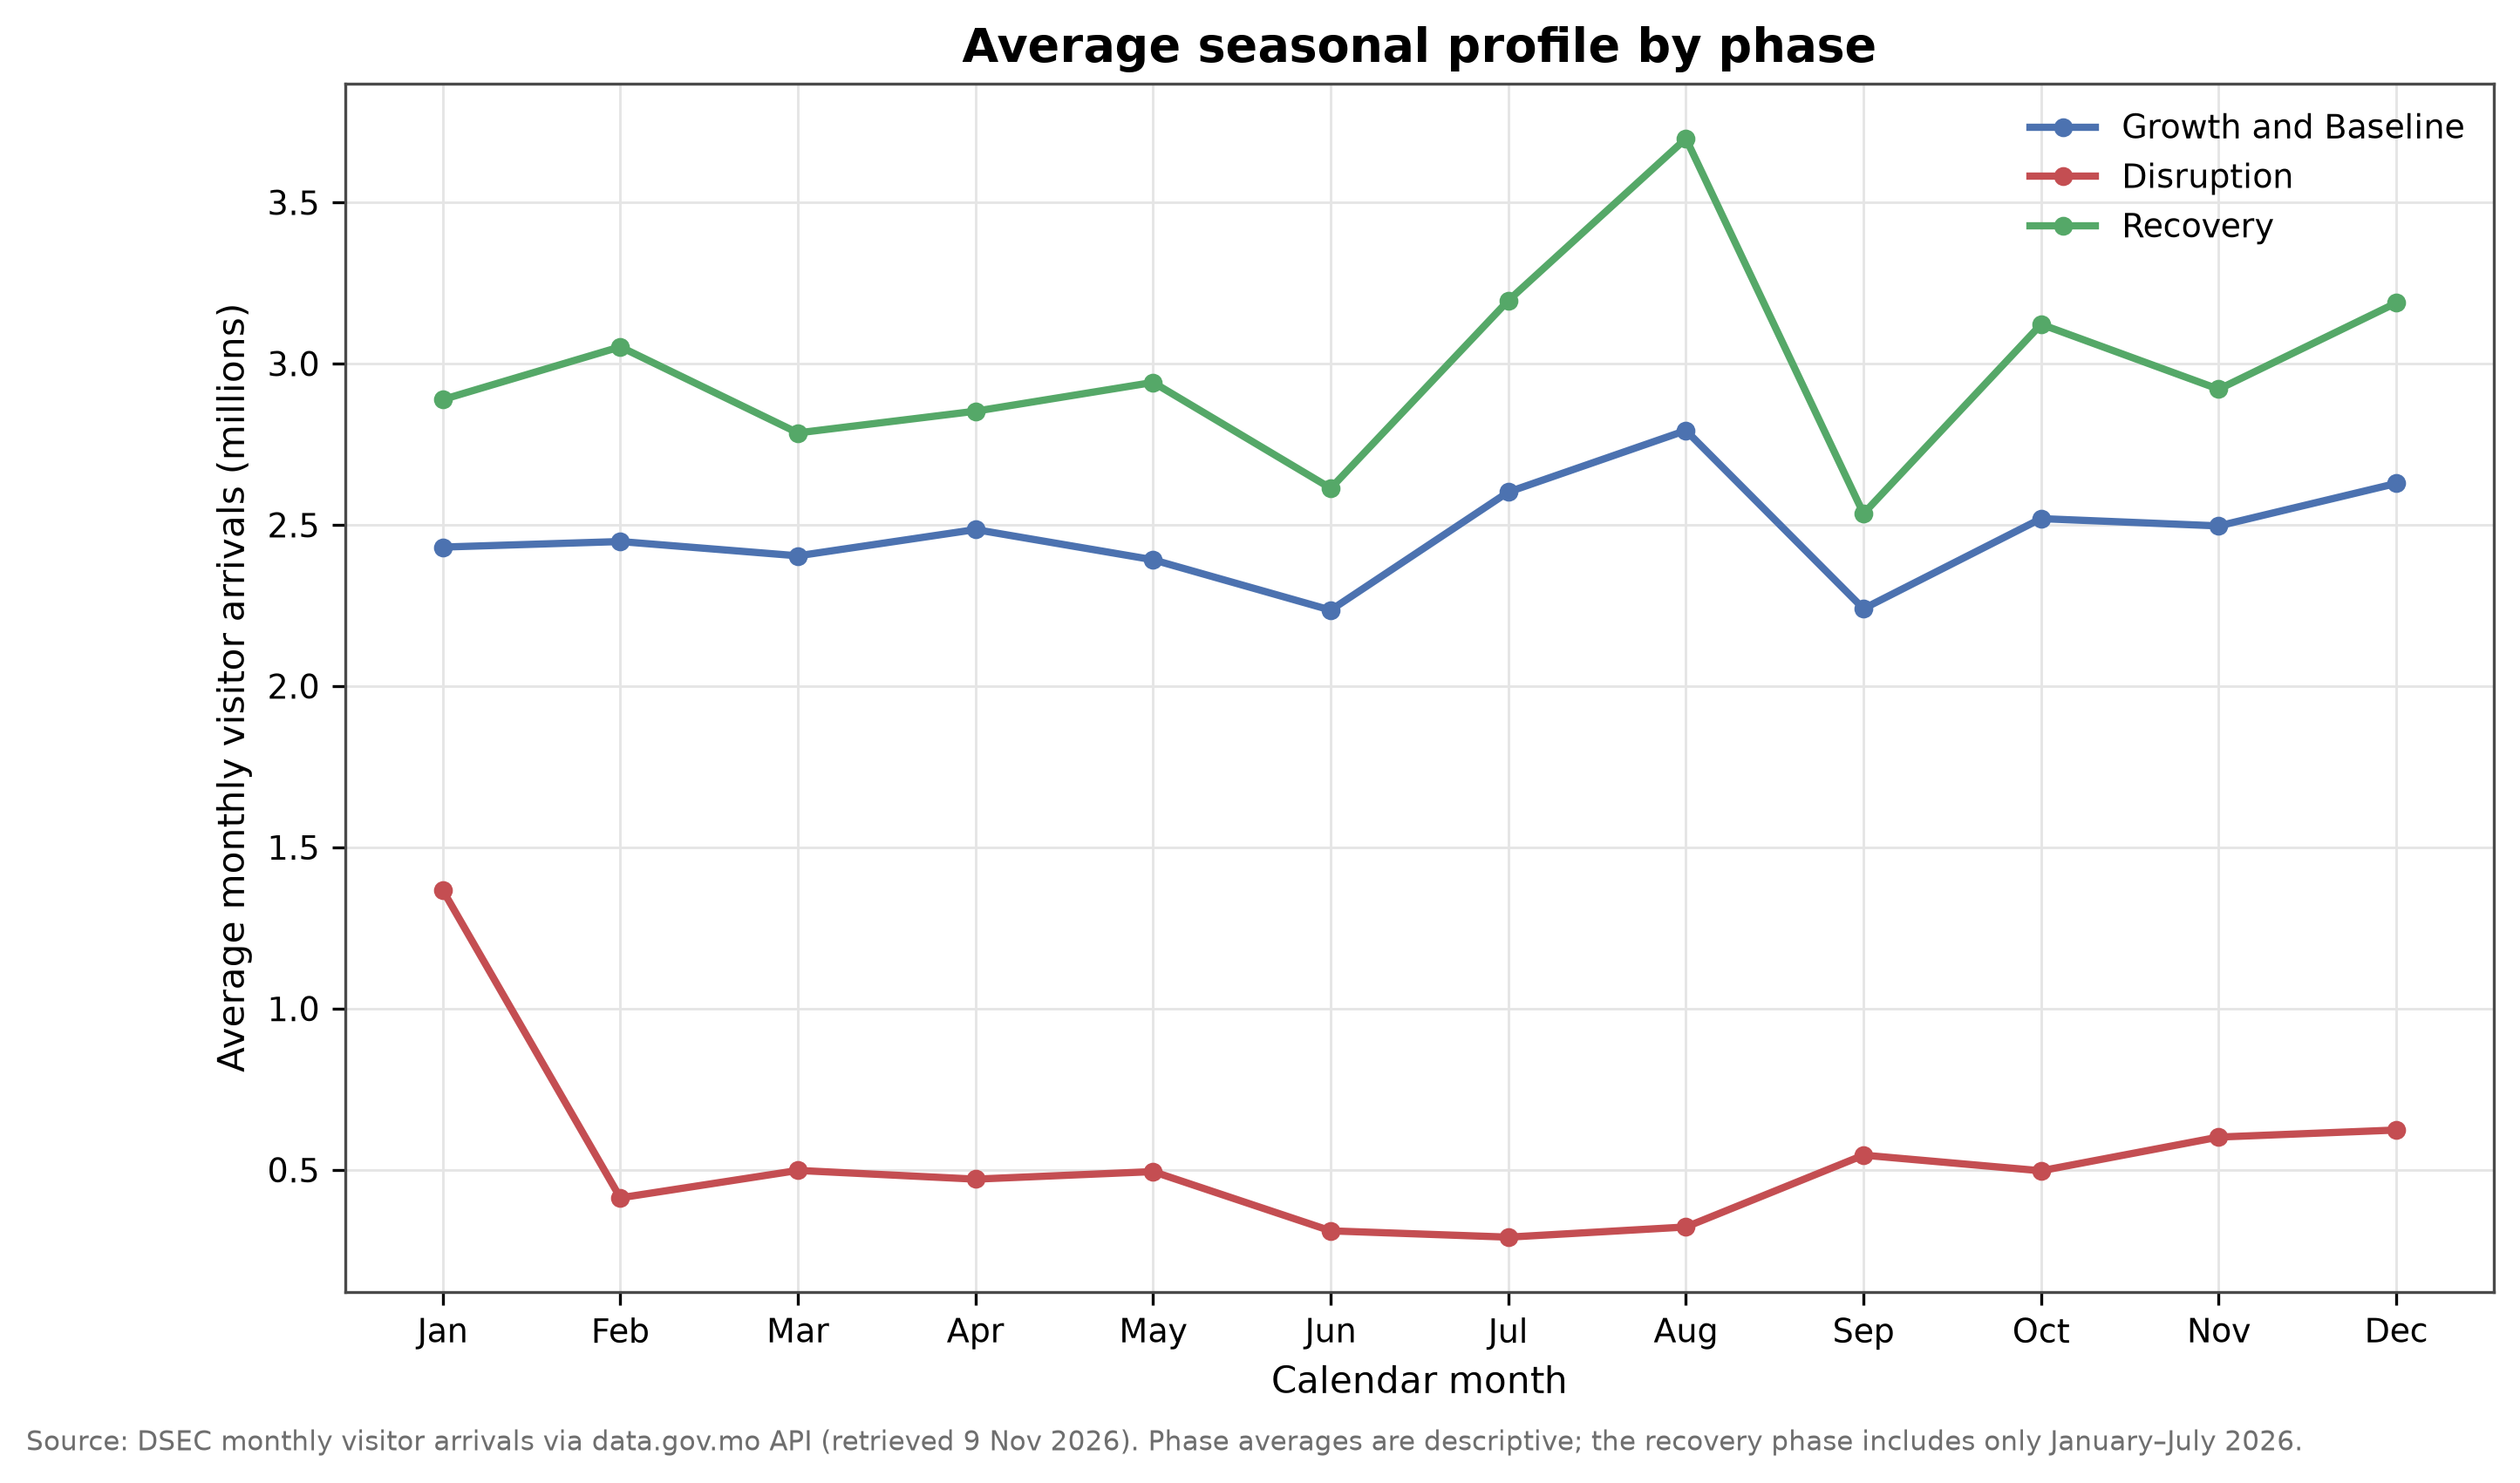

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/supplementary/Figure_S02_Seasonal_Profile_By_Phase.png


In [25]:
figure_s02(monthly)
display(Image(filename=str(SUPP / 'Figure_S02_Seasonal_Profile_By_Phase.png'), width=1100))
print('Saved:', SUPP / 'Figure_S02_Seasonal_Profile_By_Phase.png')

**Interpretation.** The pre-pandemic phase has a stable August peak and a June trough. The
disruption phase is compressed toward low levels and does not preserve the same profile. The
recovery phase has regained the August peak, but its average is based on a shorter and still
changing observation window.

### Figure S3. Year-over-year growth, with extreme values made explicit

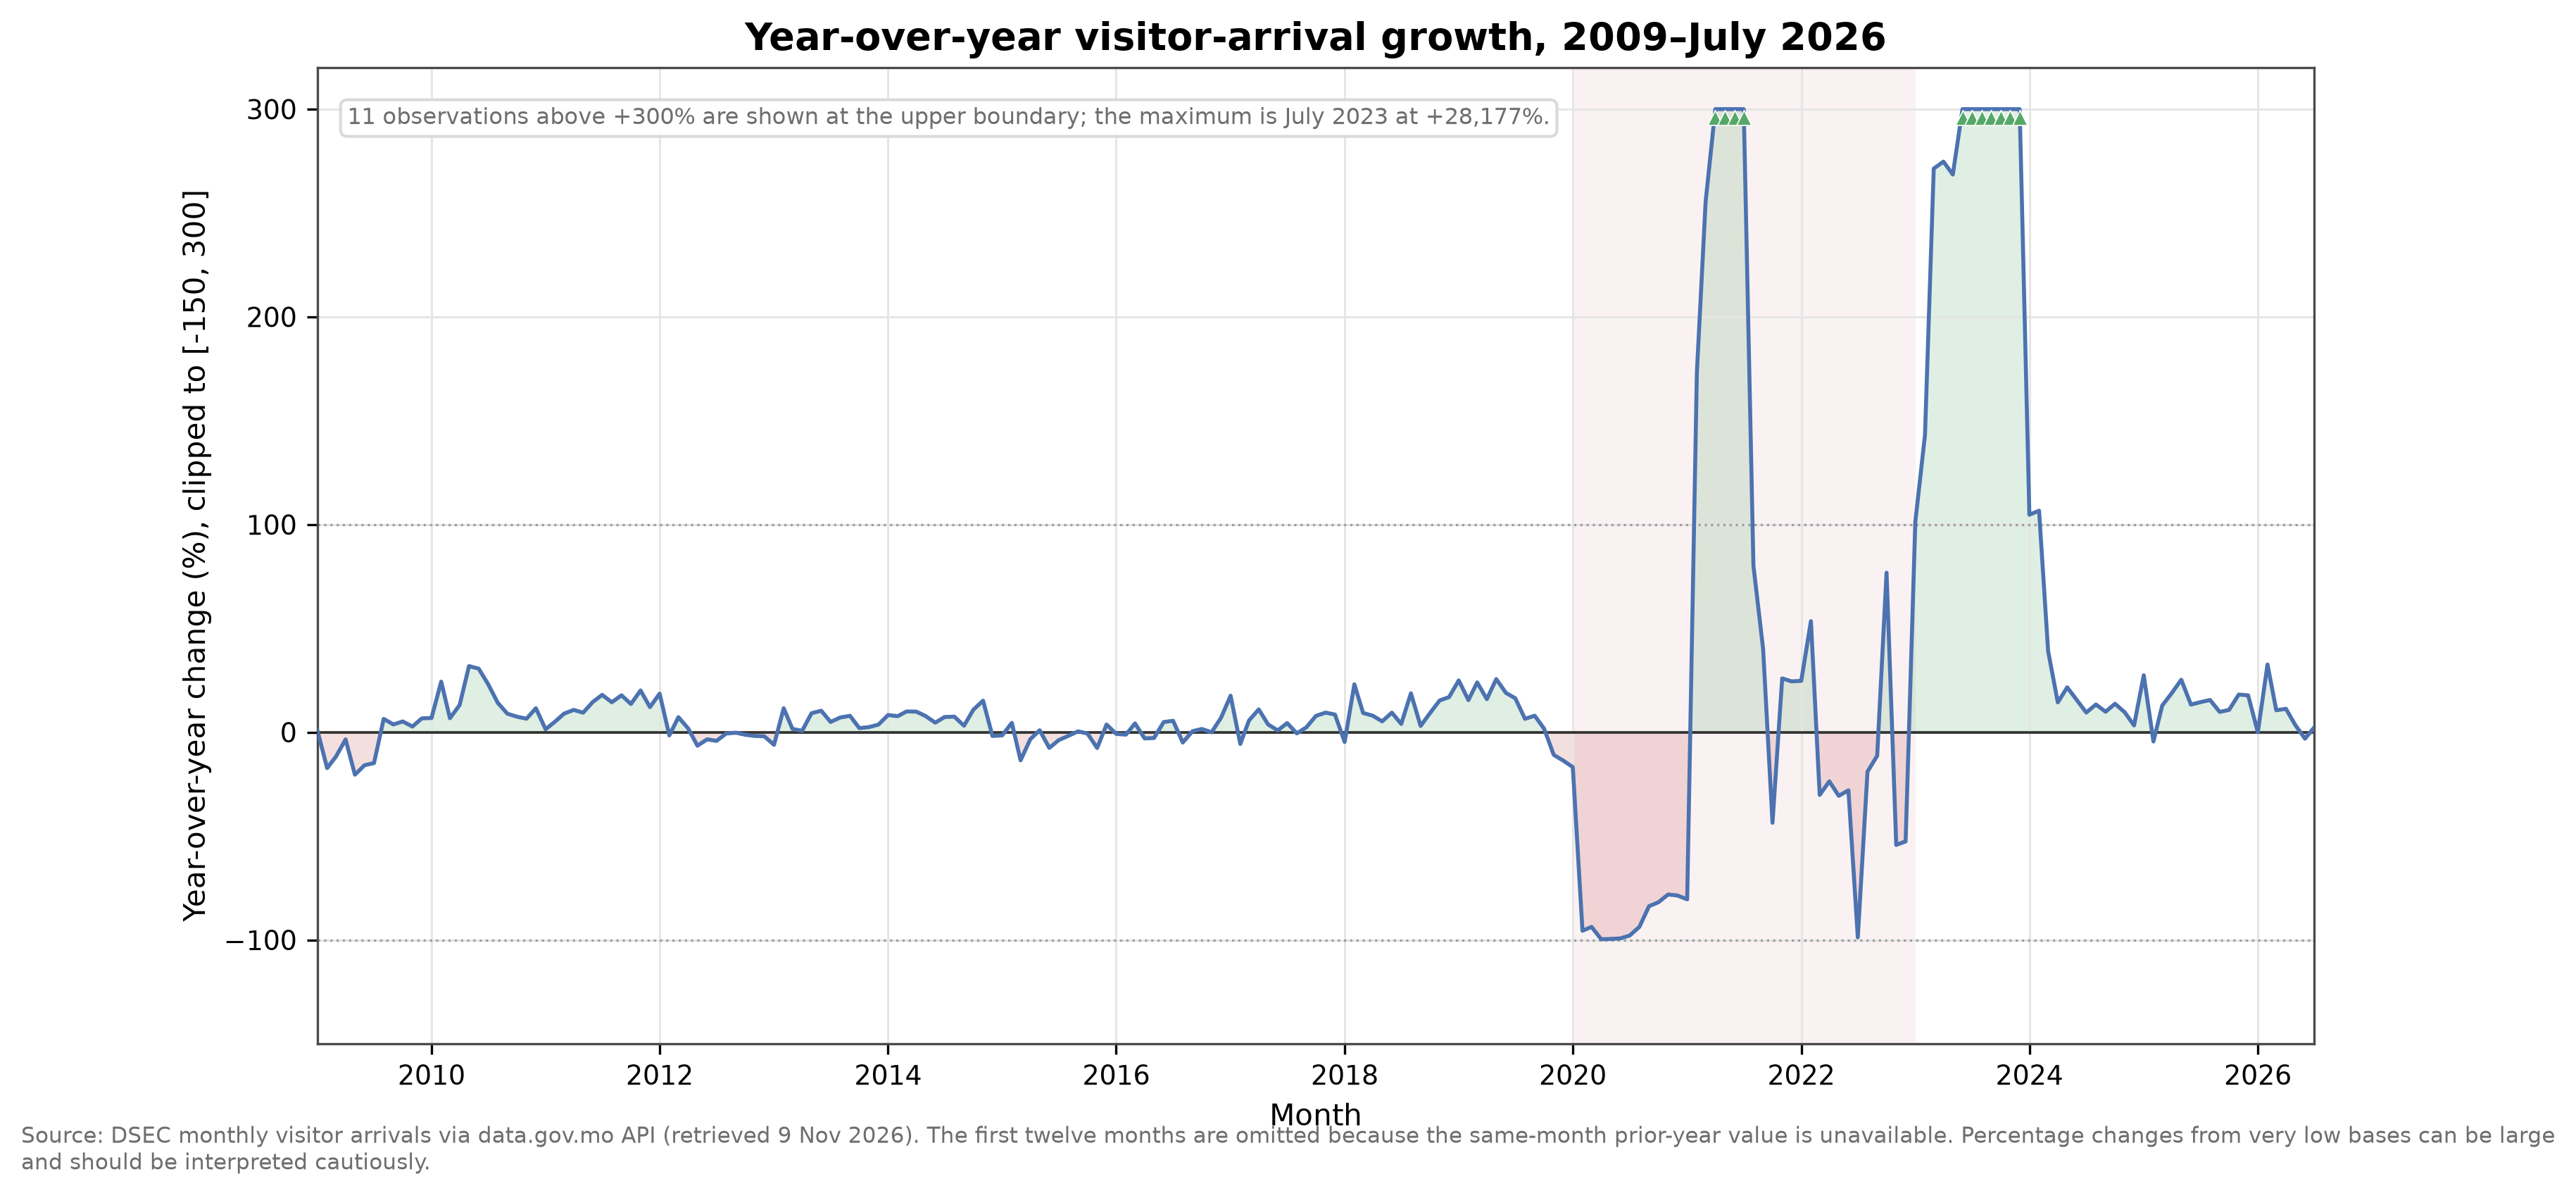

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/supplementary/Figure_S03_YoY_Growth.png


In [26]:
figure_s03(monthly)
display(Image(filename=str(SUPP / 'Figure_S03_YoY_Growth.png'), width=1100))
print('Saved:', SUPP / 'Figure_S03_YoY_Growth.png')

**Interpretation.** Year-over-year changes are useful around turning points but unstable when the
base is tiny. The April 2021 and July 2023 changes are several thousand percent because they are
measured against months near the pandemic trough. Eleven values above +300% are clipped at the
upper boundary and marked with triangles; the maximum is July 2023 at +28,177%. The chart therefore
keeps the typical range readable without hiding the outliers.

### Figure S4. Hotel guests and visitor arrivals

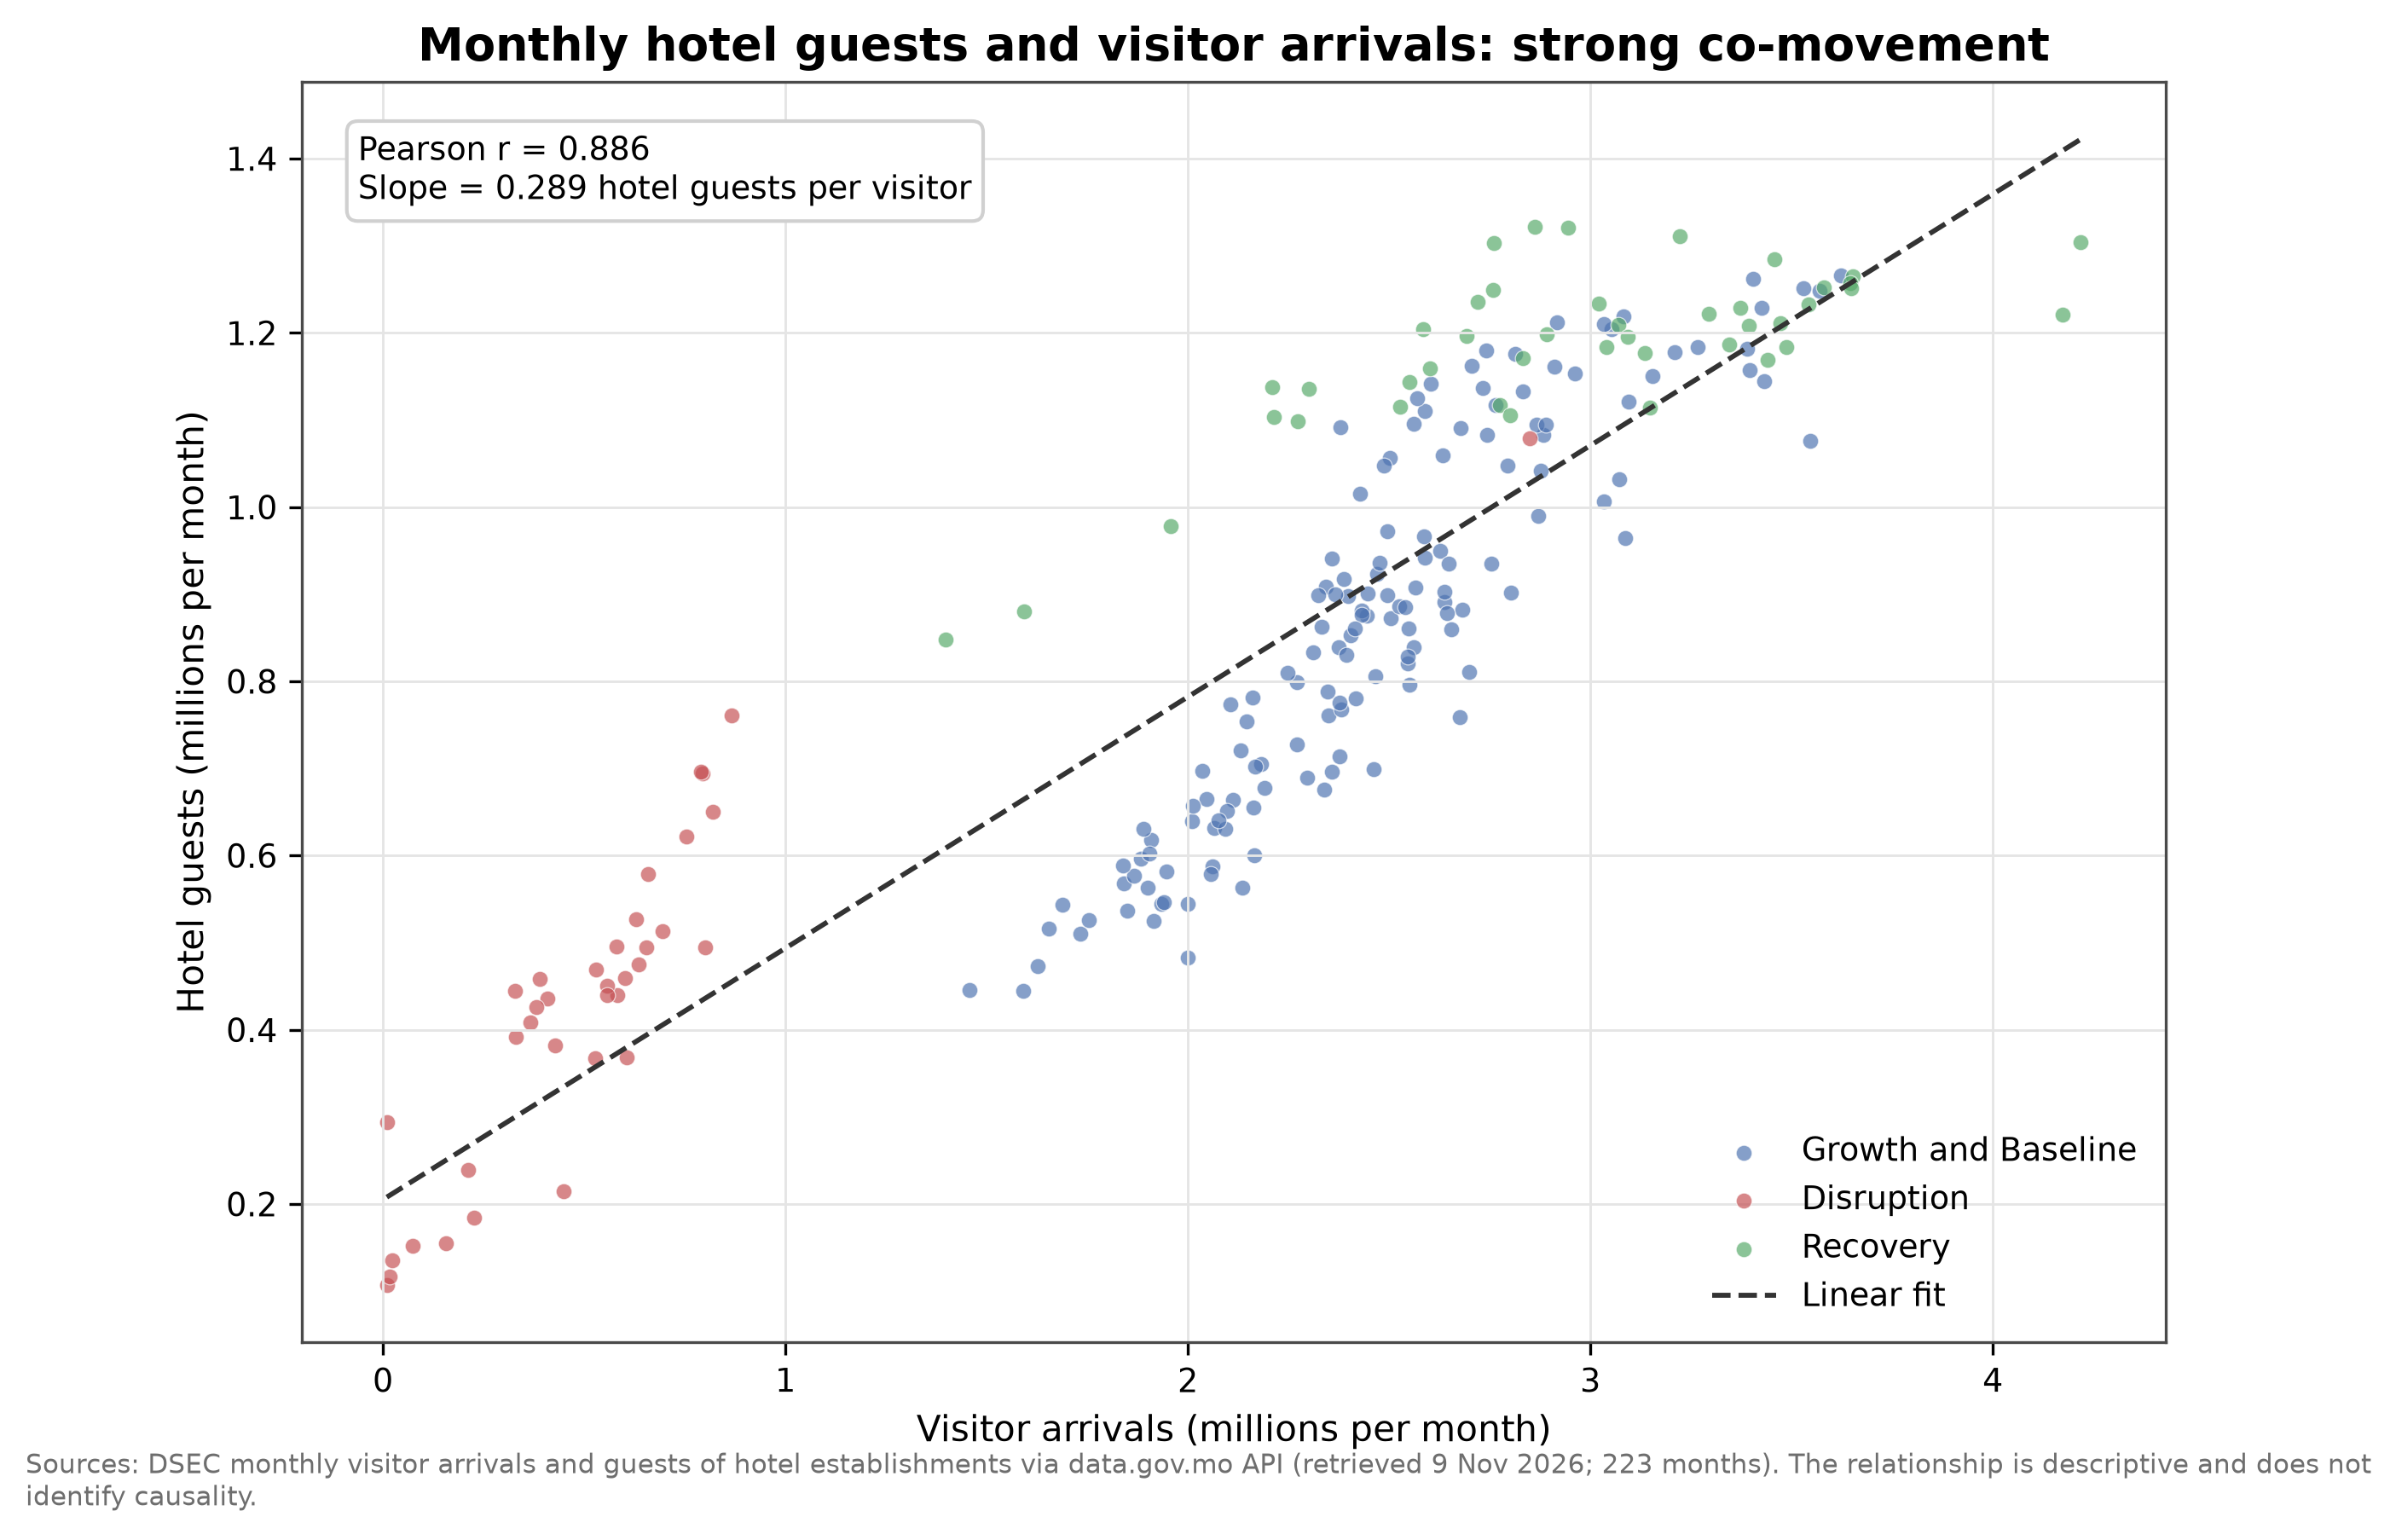

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/supplementary/Figure_S04_Hotel_Guests_vs_Visitors.png


In [27]:
figure_s04(monthly, hotel_guests)
display(Image(filename=str(SUPP / 'Figure_S04_Hotel_Guests_vs_Visitors.png'), width=1100))
print('Saved:', SUPP / 'Figure_S04_Hotel_Guests_vs_Visitors.png')

**Interpretation.** Monthly hotel guests and visitor arrivals move strongly together, with a
Pearson correlation of 0.886. The relationship is not one-to-one: many visitors stay with friends,
relatives or in non-hotel accommodation, and hotel guests can include non-arrival stays. The
regression line is descriptive and not a causal or forecasting model.

### Figure S5. Market concentration

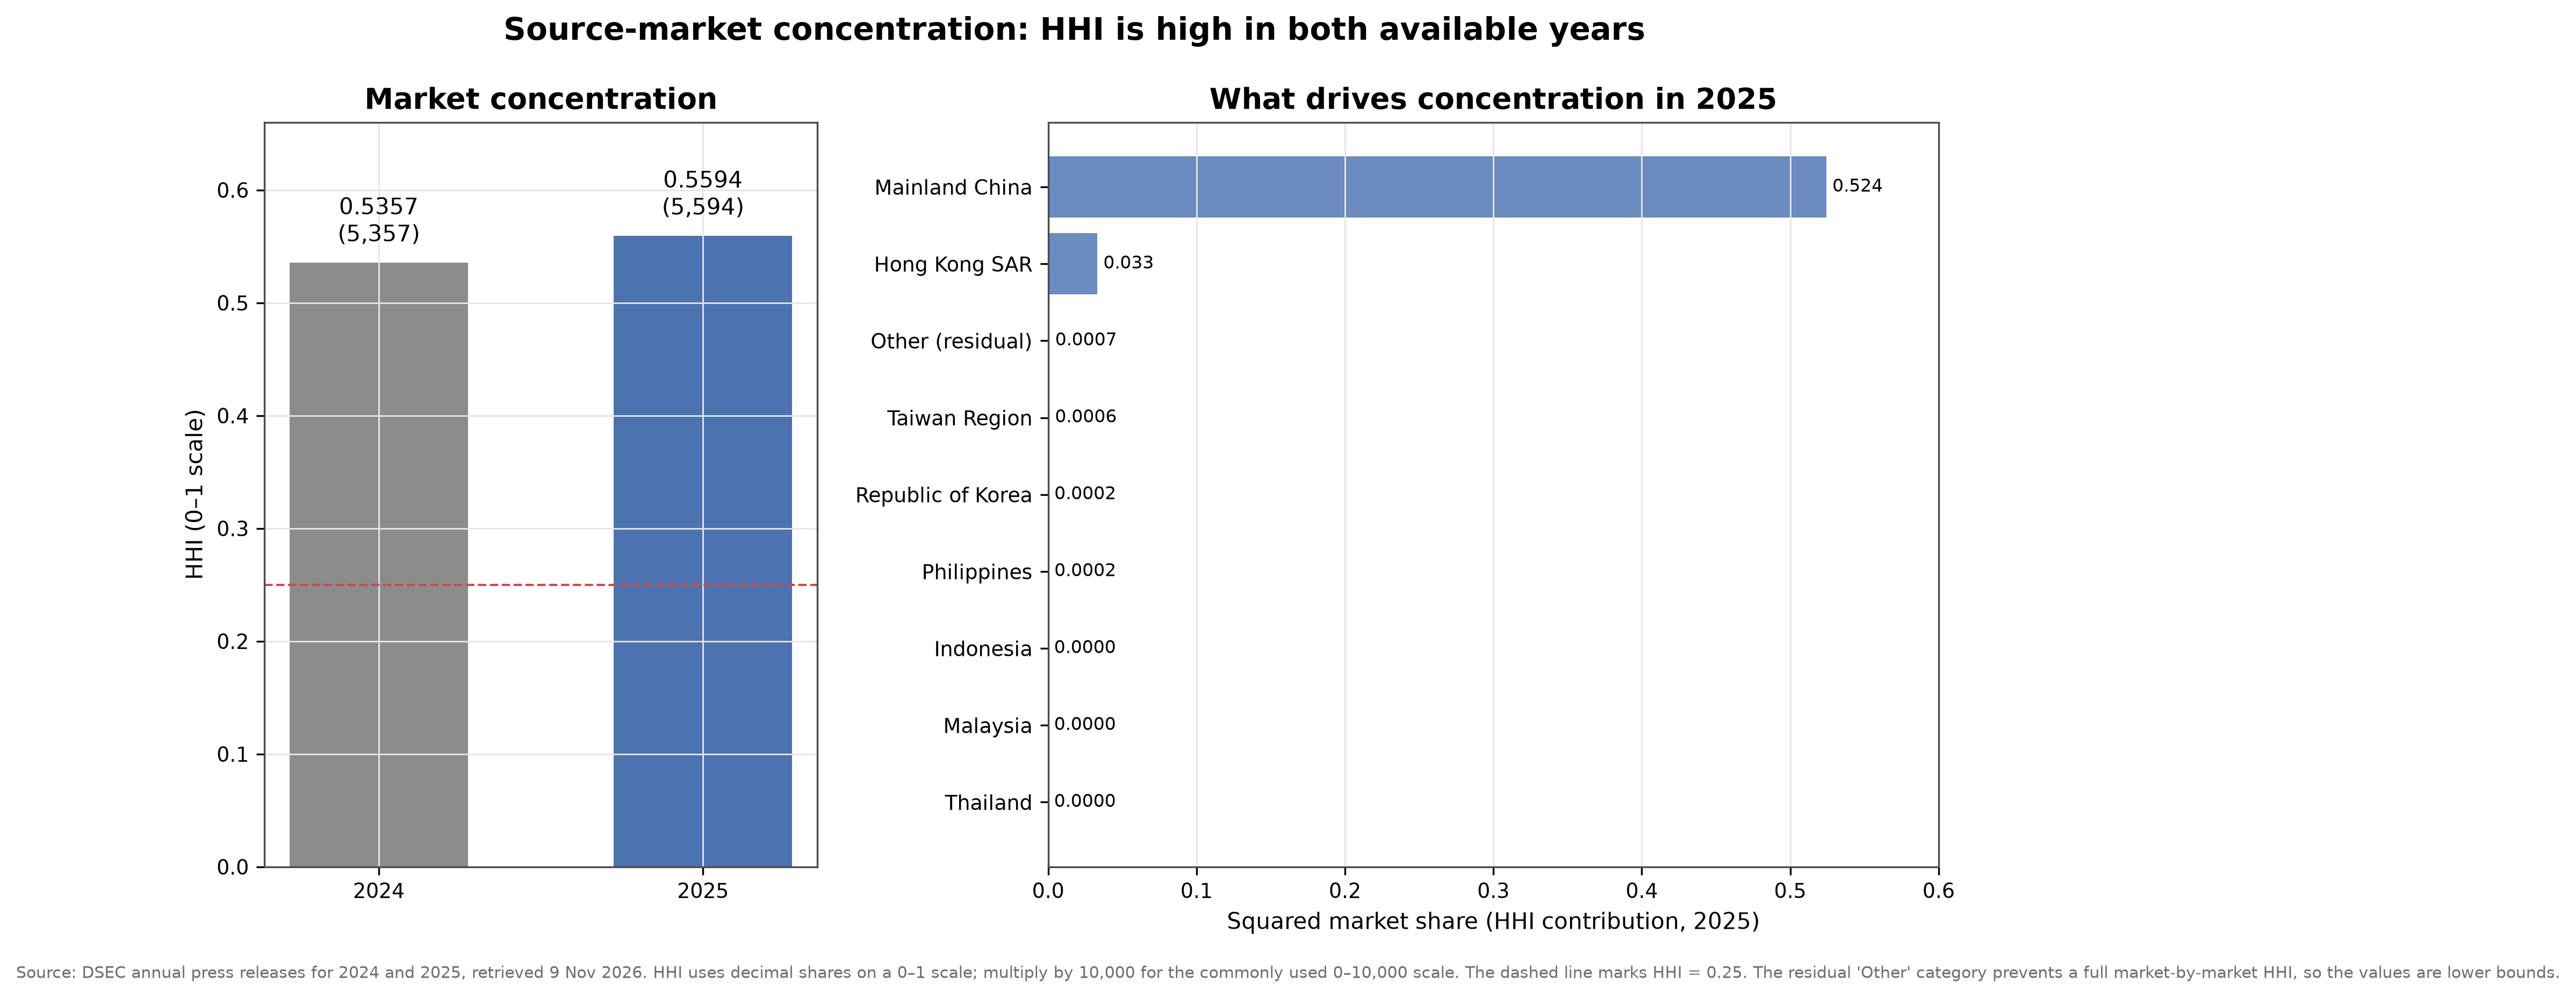

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/supplementary/Figure_S05_Market_Concentration_HHI.png


In [28]:
figure_s05(source_markets)
display(Image(filename=str(SUPP / 'Figure_S05_Market_Concentration_HHI.png'), width=1100))
print('Saved:', SUPP / 'Figure_S05_Market_Concentration_HHI.png')

**Interpretation.** HHI rises from 0.5357 in 2024 to 0.5594 in 2025, driven almost entirely by
Mainland China's squared share (0.524). This is a high concentration level. Because the source
tables group all remaining origins into "Other", the HHI is a lower bound and should not be read
as a fully disaggregated market-structure statistic.

### Figure S6. Pandemic before-and-after comparison

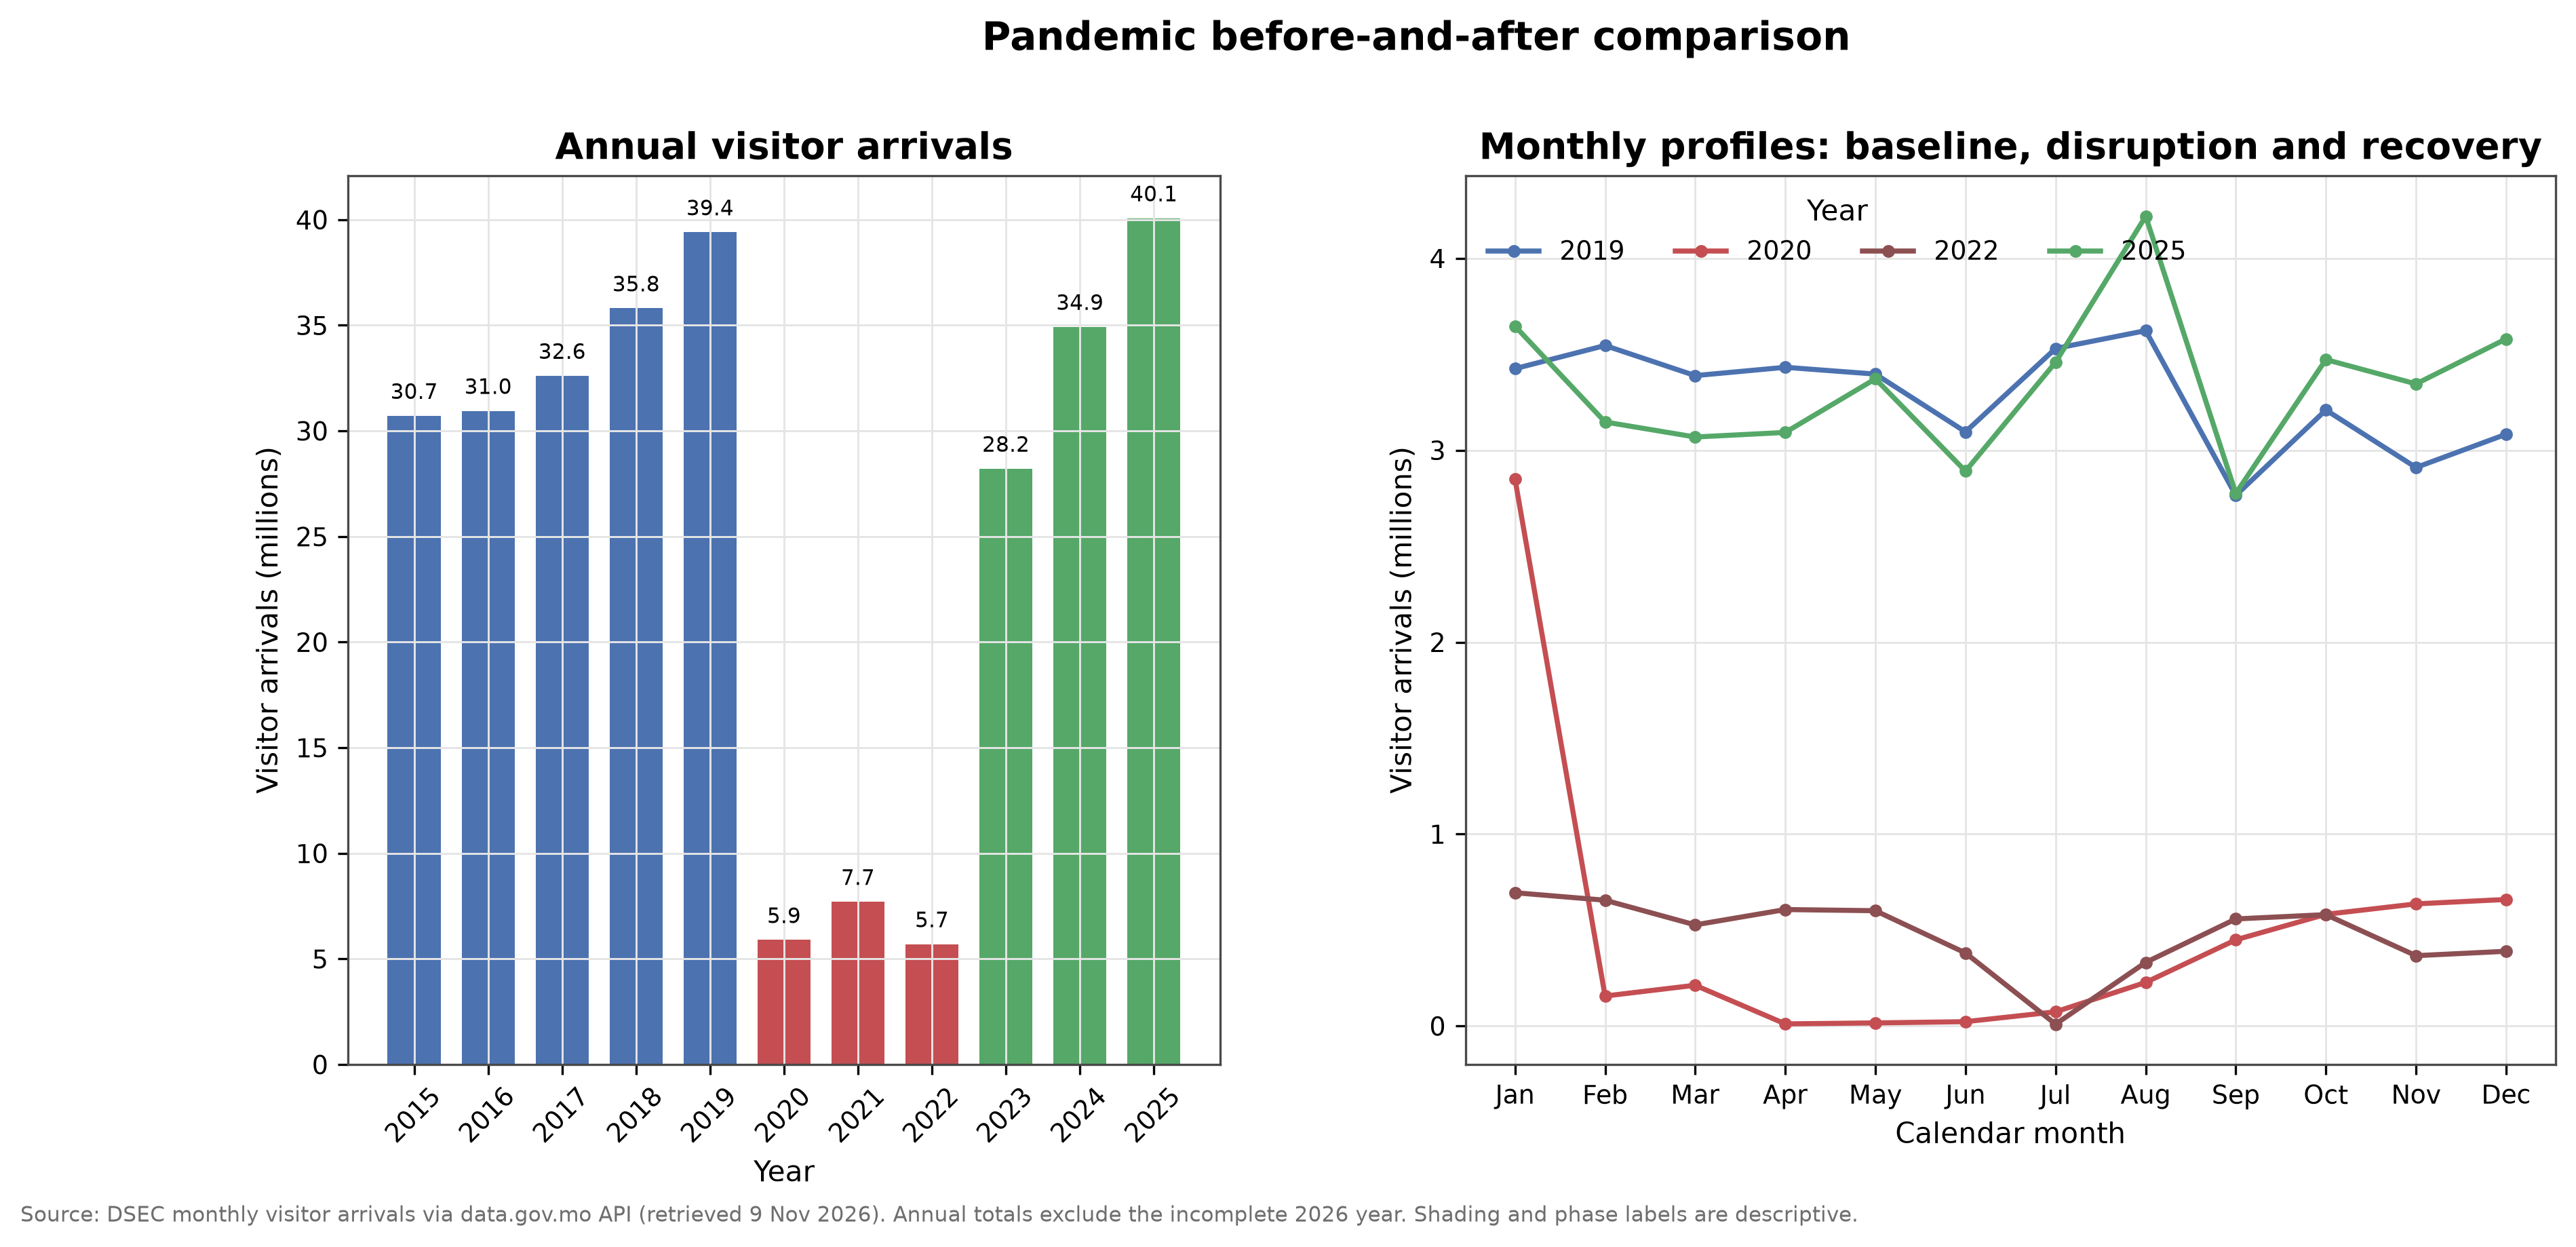

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/supplementary/Figure_S06_Pandemic_Before_After.png


In [29]:
figure_s06(monthly)
display(Image(filename=str(SUPP / 'Figure_S06_Pandemic_Before_After.png'), width=1100))
print('Saved:', SUPP / 'Figure_S06_Pandemic_Before_After.png')

**Interpretation.** The annual bars show the abrupt fall from 39.4 million visitors in 2019 to
5.9 million in 2020, followed by 40.1 million in 2025. The monthly profiles show that the recovery
is not a simple return to the exact 2019 path: 2025 exceeded 2019 in several months while remaining
below it in others. The comparison is descriptive and does not separate policy, preferences and
external demand.

### Figure S7. District choropleth, January–July 2026

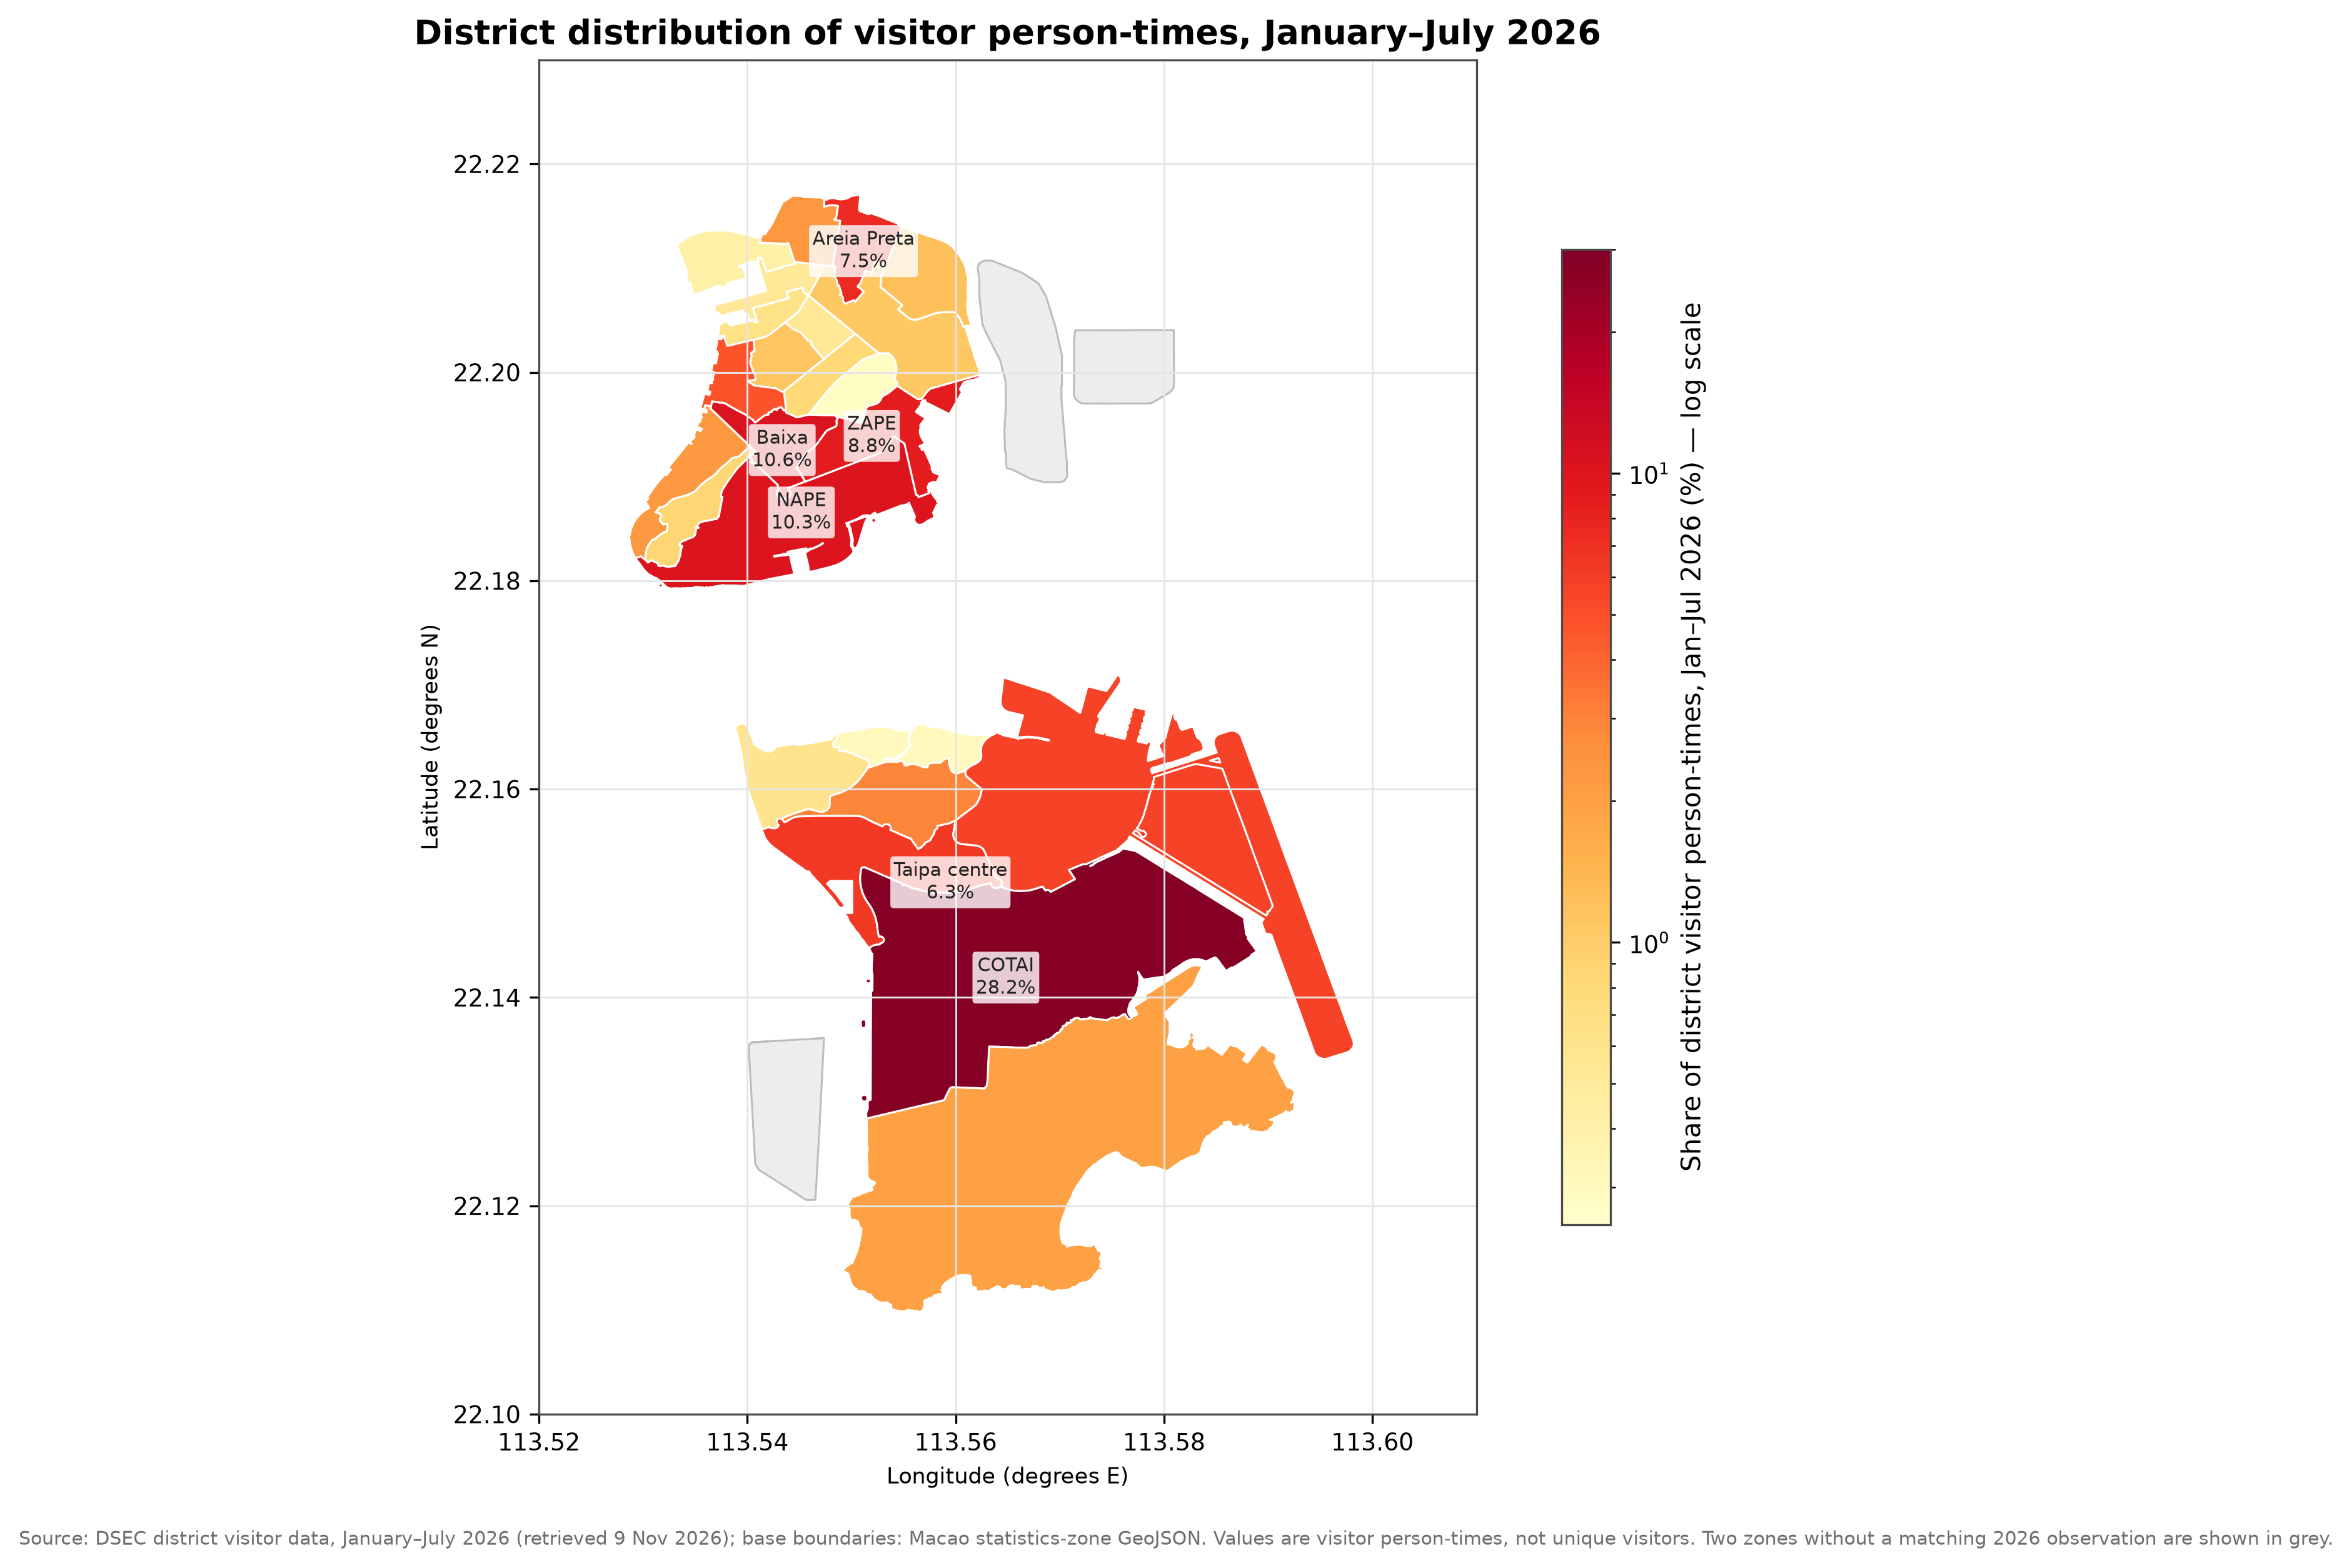

Saved: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/figures/supplementary/Figure_S07_District_Choropleth.png


In [30]:
figure_s07()
display(Image(filename=str(SUPP / 'Figure_S07_District_Choropleth.png'), width=1100))
print('Saved:', SUPP / 'Figure_S07_District_Choropleth.png')

**Interpretation.** COTAI Reclamation Area accounts for 28.2% of recorded district visitor
person-times, followed by Baixa de Macau (10.6%) and NAPE (10.3%). The colour scale is logarithmic
because the district values span a wide range. These are person-times rather than unique visitors:
one person can contribute multiple times across districts. Two zones have no matching 2026
observation and are shown in grey.

## 9. Interactive dashboard integration

The standalone Dash application is in `dashboard/app.py`. It reads only the processed CSV files
written above and does not call an external API. The dashboard exposes KPI cards and filters for
year, month, phase and source market, plus the monthly trend, recovery index, market composition,
seasonal heatmap and GDP relationship.

In [31]:
dashboard_path = PROJECT_ROOT / "dashboard" / "app.py"
print("Dashboard entry point:", dashboard_path)
print("Processed files consumed by the dashboard:")
for name in [
    "monthly_visitor_arrivals.csv",
    "annual_tourism_gdp.csv",
    "source_markets_2024_2025.csv",
    "monthly_hotel_guests.csv",
]:
    path = PROJECT_ROOT / "data" / "processed" / name
    print(f"  {name}: {path.exists()} ({path.stat().st_size:,} bytes)" if path.exists() else f"  {name}: MISSING")
print("Launch command: python dashboard/app.py")
print("Local URL: http://127.0.0.1:8050")

Dashboard entry point: /Users/wangkele/Documents/课程/研一上/数据可视化/project-6人/project/dashboard/app.py
Processed files consumed by the dashboard:
  monthly_visitor_arrivals.csv: True (15,154 bytes)
  annual_tourism_gdp.csv: True (2,057 bytes)
  source_markets_2024_2025.csv: True (921 bytes)
  monthly_hotel_guests.csv: True (4,117 bytes)
Launch command: python dashboard/app.py
Local URL: http://127.0.0.1:8050


The static notebook and the dashboard share the same processed tables, but the dashboard is
intended for interactive exploration rather than for producing the submission figures.

## 10. Key findings

1. **Long-run association is strong but non-causal.** Over 1995–2020, the OLS fit has R² = 0.817
   (0.860 excluding 2020), with a Pearson correlation of 0.904 (0.927 excluding 2020). The
   pandemic observation is an influential outlier.
2. **The disruption was unprecedented in scale.** Annual arrivals fell 85.0% from 39.41 million
   in 2019 to 5.90 million in 2020. The monthly minimum in the frozen window is 9,759 in July
   2022, versus 3.53 million in July 2019.
3. **Volume recovery is close to, but not identical with, 2019.** 2025 recorded 40.07 million
   arrivals, and January–July 2026 was 102.8% of the same 2019 period. Monthly 2026 values range
   from 90.5 (June) to 117.7 (February) on the recovery index.
4. **Seasonality remains visible.** The decomposition identifies August as the strongest seasonal
   peak and June and September as the weakest months. The 2020–2022 period distorts a stable
   additive seasonal model.
5. **Source markets are highly concentrated.** Mainland China accounts for 72.4% of 2025 arrivals;
   HHI is 0.5594 (5,594 on the 0–10,000 scale), and the grouped "Other" category means the true
   market-level HHI is at least this high.
6. **Land entry dominates.** In 2025, Border Gate, HZMB Macao Port and Hengqin Port handled
   41.6%, 22.9% and 14.6% of visitor arrivals respectively. These are checkpoint volumes, not
   unique people or tourism revenue.

## 11. Limitations and responsible interpretation

- The World Bank annual arrival series ends in 2020. Missing 2021–2025 arrivals are not
  interpolated and are not silently replaced by DSEC values.
- DSEC monthly arrivals and World Bank annual arrivals are related but not definitionally
  identical. Cross-source comparisons are therefore descriptive.
- District statistics are **visitor person-times**, not unique visitors. One person can be counted
  in multiple districts or months.
- The source-market table groups smaller origins into "Other"; HHI is therefore a lower bound.
- The recovery index measures visitor volume relative to the matching 2019 month. It says nothing
  about spending, profitability, employment, congestion or resident welfare.
- The checkpoint map uses point coordinates; the heliport coordinate is approximate, and Hengqin
  Port lies outside the Macao boundary. Circle areas encode volume but do not represent catchment
  areas.
- The 2026 monthly series is frozen at July. August–December are deliberately absent.
- OLS results are associations. They do not identify causal effects of GDP, policy or border
  capacity.

## 12. Conclusion

Macao's visitor flow is a story of a long, strongly coupled growth path, an extraordinary
pandemic interruption, and a recovery that has returned aggregate monthly volume close to 2019
without restoring every month or every market equally. The most defensible conclusion is
conditional: the available official data show a strong long-run association and a nearly complete
aggregate volume recovery by early 2026, while concentration in Mainland China and land
checkpoints remains a central structural feature. Causal and welfare claims require additional
data and a different research design.

## 13. References

1. Statistics and Census Service (DSEC), Macao SAR. Monthly visitor arrivals and guests of hotel
   establishments. data.gov.mo API and annual press releases, retrieved 9 November 2026.
2. World Bank. `ST.INT.ARVL` international tourism, number of arrivals, Macao SAR.
   <https://data.worldbank.org/indicator/ST.INT.ARVL?locations=MO>
3. World Bank. `NY.GDP.PCAP.CD` GDP per capita, current US$, Macao SAR.
   <https://data.worldbank.org/indicator/NY.GDP.PCAP.CD?locations=MO>
4. Macao Government Tourism Office (MGTO). Tourism Highlights, January–December 2025.
   <https://www.macaotourism.gov.mo/en/statistics>
5. DSEC. District visitor statistics, January–July 2026.
6. `ngsiolei/macau-map-data`. Macao outline and statistics-zone GeoJSON.
   <https://github.com/ngsiolei/macau-map-data>
7. OpenStreetMap contributors / Nominatim. Checkpoint coordinate queries, 9 November 2026.
   <https://nominatim.openstreetmap.org/>
8. Hyndman, R. J. and Athanasopoulos, G. *Forecasting: Principles and Practice*, for seasonal
   decomposition and time-series caveats.